# PlantSR · Inpainting Week 1: masks, model selection, training check and app layout
AAI 521 Group 1 · Role C (Ali) · Google Colab · **GPU runtime (T4 or better)**

This notebook covers my Week 1 items in the project plan and builds on Peng's prepared dataset (`PlantSR_Preprocessing_Center256.ipynb`).

| Plan item | Section |
|---|---|
| **C1** Generate inpainting masks; verify covered-area ratios and alignment | 4 |
| **C1** Select an inpainting model | 6 |
| **Shared** Short fine-tuning trial; reload the checkpoint in a fresh process | 7 |
| **Shared** Common inference interface `restore(image, task, mask=None, seed=42)` | 5 and 8 |
| **C3 (start)** Application layout: upload, task selection, mask drawing, preview, status, download | 9 |

Run the cells from top to bottom with **Runtime → Change runtime type → T4 GPU**. A full run takes about 50 minutes on a T4, including a one-time download of about 2 GB of model weights. The data is copied to the Colab disk for speed; everything worth keeping is saved to `MyDrive/AAI521/Final_project/inpainting_week1/`:

| Saved output | Purpose |
|---|---|
| `PlantSR_inpainting_masks_v1.zip` | Fixed validation/test masks, masked inputs and manifests for the team |
| `inpainting_val.csv`, `inpainting_test.csv` | Frozen copies of the mask manifests, used to detect any change on reruns |
| `model_selection_val.csv`, `model_selection_summary.csv` | Zero-shot comparison on validation crops |
| `lora_trial/` | Trial LoRA weights, configuration and fresh-process reload report |
| `inpainting_week1_code.zip` | `src/`, `app/`, `configs/` and `docs/` files to commit on `feat/inpaint` |
| `week1_summary.json` | Settings, counts and check results for the report |

All comparisons use **validation** crops. Test masks are generated and checked here so that they are frozen, but no model is run on the test split.

## 1 · Install dependencies

Colab already includes PyTorch, Transformers, OpenCV, scikit-image and Flask. This cell upgrades `diffusers` and `peft`, which provide the inpainting pipeline and the LoRA save/load helpers, and installs `lpips` for perceptual scores. It also removes Colab's preinstalled `torchao` when it is older than 0.16, because recent `peft` refuses to add LoRA layers next to it; this project does not use `torchao`. Missing libraries are installed only when they cannot be imported, so the cell is safe to rerun. Running on your own GPU machine works the same way.

In [1]:
# Install or upgrade the diffusion, LoRA, metric and web-app libraries.
import importlib.util
import os
import subprocess
import sys

if os.environ.get("PLANTSR_SKIP_INSTALL") != "1":
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "--upgrade",
                    "diffusers", "peft", "accelerate"], check=True)
    needed = {"transformers": "transformers", "safetensors": "safetensors", "lpips": "lpips",
              "cv2": "opencv-python-headless", "skimage": "scikit-image", "flask": "flask",
              "gdown": "gdown", "pandas": "pandas", "matplotlib": "matplotlib"}
    missing = [package for module, package in needed.items() if importlib.util.find_spec(module) is None]
    if missing:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)

from importlib.metadata import PackageNotFoundError, version
from packaging.version import Version

# Colab ships an old torchao; recent peft refuses to create LoRA layers while torchao < 0.16 is installed.
# This project does not use torchao, so remove the old copy (no runtime restart needed).
try:
    if Version(version("torchao")) < Version("0.16.0"):
        subprocess.run([sys.executable, "-m", "pip", "uninstall", "--quiet", "-y", "torchao"], check=True)
        importlib.invalidate_caches()
        print("Removed an old torchao that is incompatible with peft (not used by this project).")
except PackageNotFoundError:
    pass

for package in ("torch", "diffusers", "transformers", "peft", "accelerate", "lpips", "opencv-python-headless", "flask"):
    try:
        print(f"{package:24s} {version(package)}")
    except Exception:
        print(f"{package:24s} (not installed)")

Removed an old torchao that is incompatible with peft (not used by this project).
torch                    2.14.1+cu130
diffusers                0.43.0
transformers             5.22.1
peft                     0.21.3
accelerate               1.15.0
lpips                    0.1.4
opencv-python-headless   5.0.0.93
flask                    3.1.3


## 2 · Mount Google Drive and configure paths

The project folder matches Peng's notebook: `/content/drive/MyDrive/AAI521/Final_project`. Put `PlantSR_prepared_for_team.zip` there (open Peng's link and choose **Organize → Add shortcut to My Drive**, or download and upload it). If the ZIP is not found, the next section downloads it from the shared link instead.

Settings used throughout:

| Setting | Value | Why |
|---|---|---|
| `SEED` | 42 | Same seed as the dataset split; also used for masks and diffusion sampling |
| `MODEL_ID` | `stable-diffusion-v1-5/stable-diffusion-inpainting` | Candidate fine-tuning target (section 6 explains the choice) |
| `WORK_RES` | 512 | Native resolution of SD 1.5; 256 × 256 crops are upsampled 2× for the model and resized back |
| `SD_STEPS` | 25 | DPM-Solver++ steps; enough for stable inpainting while keeping evaluation fast |
| `N_SELECT` | 0 (all 166) | Validation crops used for model selection; 32-crop subsets proved too noisy to rank the SD settings |
| `TRIAL_STEPS` | 100 | Length of the short training check from the plan (50–100 steps) |

Every setting can also be overridden with an environment variable such as `PLANTSR_PROJECT_DIR`, which makes the notebook runnable on a local GPU without editing cells.

In [2]:
# Mount Drive, define project paths and settings, and create the code folder.
import csv
import json
import shutil
import time
from pathlib import Path

try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

env = os.environ.get
PROJECT_DIR = Path(env("PLANTSR_PROJECT_DIR", "/content/drive/MyDrive/AAI521/Final_project"))
TEAM_ZIP = PROJECT_DIR / "PlantSR_prepared_for_team.zip"
TEAM_ZIP_DRIVE_ID = "1j_vx9Yuow1pu8MzYmbGY4udXBpB4dBx1"  # Peng's shared PlantSR_prepared_for_team.zip
LOCAL_DIR = Path(env("PLANTSR_LOCAL_DIR", "/content/plantsr"))  # fast Colab disk
PREPARED_DIR = LOCAL_DIR / "prepared"
CODE_DIR = Path(env("PLANTSR_CODE_DIR", "/content/AAI521-Group1-PlantSR-Restoration"))
OUTPUT_DIR = PROJECT_DIR / "inpainting_week1"  # persisted in Drive

SEED = 42
MODEL_ID = env("PLANTSR_MODEL_ID", "stable-diffusion-v1-5/stable-diffusion-inpainting")
WORK_RES = int(env("PLANTSR_WORK_RES", "512"))
SD_STEPS = int(env("PLANTSR_SD_STEPS", "25"))
N_SELECT = int(env("PLANTSR_N_SELECT", "0"))  # 0 = all validation crops (~25 min of SD); 32 = quick check
TRIAL_STEPS = int(env("PLANTSR_TRIAL_STEPS", "100"))
APP_PORT = int(env("PLANTSR_APP_PORT", "7860"))
INPAINT_REL = "derived/inpainting_v1"  # inpainting files live under prepared/ like the team manifests

for folder in (PROJECT_DIR, OUTPUT_DIR, LOCAL_DIR):
    folder.mkdir(parents=True, exist_ok=True)
for sub in ("src/data", "src/inference", "src/evaluation", "src/train", "app/templates", "app/static",
            "configs", "docs"):
    (CODE_DIR / sub).mkdir(parents=True, exist_ok=True)
for package in ("src", "src/data", "src/inference", "src/evaluation", "src/train"):
    (CODE_DIR / package / "__init__.py").touch()
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))


def read_csv(path):
    with Path(path).open(encoding="utf-8-sig", newline="") as stream:
        return list(csv.DictReader(stream))


def write_csv(path, rows, fields):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with Path(path).open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)


print(f"Project folder  {PROJECT_DIR}")
print(f"Drive outputs   {OUTPUT_DIR}")
print(f"Local dataset   {PREPARED_DIR}")
print(f"Code folder     {CODE_DIR}")

Mounted at /content/drive
Project folder  /content/drive/MyDrive/AAI521/Final_project
Drive outputs   /content/drive/MyDrive/AAI521/Final_project/inpainting_week1
Local dataset   /content/plantsr/prepared
Code folder     /content/AAI521-Group1-PlantSR-Restoration


In [3]:
# Check the GPU.
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"GPU {props.name} · {props.total_memory / 1024**3:.1f} GB · compute capability {props.major}.{props.minor}")
else:
    print("No GPU detected. Choose Runtime → Change runtime type → T4 GPU, then rerun from the top.\n"
          "Sections 3–5 work on CPU; the diffusion sections would take hours.")

GPU Tesla T4 · 14.6 GB · compute capability 7.5


## 3 · Restore the shared PlantSR dataset

Extract Peng's ZIP to the Colab disk (reading thousands of PNGs straight from Drive is slow). The cell reuses an existing extraction, falls back to downloading the ZIP from the shared link, and checks the split counts and the saved 256 × 256 evaluation crops. Paths in every manifest are relative to `prepared/`.

In [4]:
# Extract the team dataset to local disk and check split counts and crop sizes.
import zipfile

from IPython.display import Markdown, display
from PIL import Image

if not (PREPARED_DIR / "summary.json").is_file():
    zip_path = TEAM_ZIP
    if not zip_path.is_file():
        import gdown
        print("Team ZIP not found in Drive; downloading it from the shared link…")
        zip_path = LOCAL_DIR / TEAM_ZIP.name
        gdown.download(id=TEAM_ZIP_DRIVE_ID, output=str(zip_path), quiet=False)
    with zipfile.ZipFile(zip_path) as archive:
        if not any(name.startswith("prepared/") for name in archive.namelist()):
            raise ValueError(f"{zip_path} does not contain a prepared/ folder.")
        archive.extractall(LOCAL_DIR)
    print(f"Extracted {zip_path.name} to {LOCAL_DIR}")
else:
    print(f"Using the existing extraction at {PREPARED_DIR}")

summary = json.loads((PREPARED_DIR / "summary.json").read_text(encoding="utf-8"))
manifests = {split: read_csv(PREPARED_DIR / "manifests" / f"{split}.csv") for split in ("train", "val", "test")}

crop_sizes = {}
for split in ("val", "test"):
    sizes = set()
    for row in manifests[split]:
        with Image.open(PREPARED_DIR / row["eval_crop_path"]) as crop:
            sizes.add(crop.size)
    crop_sizes[split] = sorted(sizes)
missing_hr = [r["sample_id"] for rows in manifests.values() for r in rows if not (PREPARED_DIR / r["hr_path"]).is_file()]

table = ["| Split | Images | Saved 256 × 256 crops |", "|---|---:|---|"]
for split, rows in manifests.items():
    table.append(f"| {split} | {len(rows)} | {crop_sizes.get(split, 'full-size only (random crops in training)')} |")
display(Markdown("\n".join(table)))
print("Summary counts:", summary.get("final_counts"))
if missing_hr:
    raise FileNotFoundError(f"{len(missing_hr)} full-size images are missing, e.g. {missing_hr[:3]}")
if any(sizes != [(256, 256)] for sizes in crop_sizes.values()):
    raise ValueError(f"Unexpected evaluation crop sizes: {crop_sizes}")

Team ZIP not found in Drive; downloading it from the shared link…


Downloading...
From (original): https://drive.google.com/uc?id=1j_vx9Yuow1pu8MzYmbGY4udXBpB4dBx1
From (redirected): https://drive.google.com/uc?id=1j_vx9Yuow1pu8MzYmbGY4udXBpB4dBx1&confirm=t&uuid=8d9b1668-561f-4914-ae88-1f543df8f3ec
To: /content/plantsr/PlantSR_prepared_for_team.zip
100%|██████████| 1.80G/1.80G [00:16<00:00, 106MB/s]


Extracted PlantSR_prepared_for_team.zip to /content/plantsr


| Split | Images | Saved 256 × 256 crops |
|---|---:|---|
| train | 663 | full-size only (random crops in training) |
| val | 166 | [(256, 256)] |
| test | 200 | [(256, 256)] |

Summary counts: {'train': 663, 'val': 166, 'test': 200}


## 4 · Inpainting masks (C1)

### 4.1 Write the mask generator

The cell below writes `src/data/inpaint_masks.py` into the code folder; the same file goes into the repository. Conventions from the team README:

- **mask 1 = missing / reconstruct, 0 = preserve**, saved as single-channel PNGs with values 0 and 255;
- roughly **5–20% coverage**, with two families: *rectangle* (one to three boxes, like block damage or occlusion) and *free-form* (brush strokes with round joints, like scratches);
- **fixed validation/test masks**: each mask's seed is derived from `(SEED, split, sample_id, generator version)`, so regenerating always yields identical pixels. Mask types alternate and target coverages are spread evenly over 5–20% within each type, so every coverage bin is represented;
- **training masks** are sampled on the fly *after* the random crop and flip, so the image and mask always share the same geometry.

The masked inputs replace missing pixels with grey (128). Models must not depend on that value: the diffusion wrapper re-applies the mask itself.

In [5]:
%%writefile "{CODE_DIR}/src/data/inpaint_masks.py"
"""Reproducible inpainting masks for the PlantSR benchmark.

Convention shared by the whole team: mask value 1 = missing / reconstruct, 0 = preserve.
Masks are saved as single-channel PNGs with 0 (preserve) and 255 (missing).

Two mask families are used, each covering roughly 5-20% of a 256 x 256 crop:
  * rectangle - one to three axis-aligned boxes (block damage, occlusion)
  * freeform  - brush strokes with round joints (scratches, irregular damage)

Validation/test masks are fixed: each one is generated from a seed derived from
(base seed, split, sample_id, generator version), so regenerating them always gives
identical pixels. Training masks are sampled on the fly after cropping/flipping, so the
image and mask always share the same geometry.
"""
from __future__ import annotations

import hashlib
import json
import math
from pathlib import Path

import cv2
import numpy as np
from PIL import Image

GENERATOR_VERSION = "plantsr_inpaint_masks_v1"
COVERAGE_RANGE = (0.05, 0.20)
MASK_TYPES = ("rectangle", "freeform")
FILL_VALUE = 128  # grey written into missing pixels of the saved masked inputs
MANIFEST_FIELDS = [
    # Fields agreed in the team README, in the agreed order.
    "sample_id", "source_image_id", "split", "task", "input_path", "target_path",
    "mask_path", "crop_coordinates", "degradation_parameters", "seed",
    # Extra inpainting columns for quick filtering and integrity checks.
    "mask_type", "mask_coverage", "coverage_bin", "mask_sha256",
]


def seed_for(*parts) -> int:
    """Stable 63-bit seed from arbitrary JSON-serialisable parts."""
    digest = hashlib.sha256(json.dumps(parts, ensure_ascii=False).encode()).hexdigest()
    return int(digest[:15], 16)


def coverage(mask: np.ndarray) -> float:
    return float(np.asarray(mask, dtype=bool).mean())


def coverage_bin(value: float) -> str:
    if value < 0.10:
        return "small_5_10"
    if value < 0.15:
        return "medium_10_15"
    return "large_15_20"


def _bbox(mask: np.ndarray) -> list[int]:
    ys, xs = np.nonzero(mask)
    if len(xs) == 0:
        return [0, 0, 0, 0]
    return [int(xs.min()), int(ys.min()), int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1)]


def _rectangles(rng: np.random.Generator, h: int, w: int, target: float, upper: float):
    mask = np.zeros((h, w), np.uint8)
    n = int(rng.integers(1, 4))
    shares = rng.dirichlet(np.ones(n)) if n > 1 else np.array([1.0])
    rects = []
    for share in shares:
        area = max(64.0, share * target * h * w)
        aspect = float(np.exp(rng.uniform(np.log(1 / 3), np.log(3))))
        rw = int(np.clip(round(math.sqrt(area * aspect)), 6, int(0.9 * w)))
        rh = int(np.clip(round(area / max(rw, 1)), 6, int(0.9 * h)))
        x = int(rng.integers(0, w - rw + 1))
        y = int(rng.integers(0, h - rh + 1))
        mask[y:y + rh, x:x + rw] = 1
        rects.append([x, y, rw, rh])
    return mask, {"rectangles_xywh": rects}


def _strokes(rng: np.random.Generator, h: int, w: int, target: float, upper: float):
    mask = np.zeros((h, w), np.uint8)
    scale = min(h, w) / 256.0
    strokes, misses = [], 0
    while coverage(mask) < target and len(strokes) < 40 and misses < 20:
        candidate = mask.copy()
        width = max(2, int(round(rng.integers(8, 25) * scale)))
        x, y = float(rng.uniform(0, w)), float(rng.uniform(0, h))
        angle = float(rng.uniform(0, 2 * math.pi))
        points = [(x, y)]
        for _ in range(int(rng.integers(3, 9))):
            angle += float(rng.uniform(-math.pi / 2, math.pi / 2))
            length = float(rng.uniform(10, 40)) * scale
            x = float(np.clip(x + length * math.cos(angle), 0, w - 1))
            y = float(np.clip(y + length * math.sin(angle), 0, h - 1))
            points.append((x, y))
        pts = [(int(round(px)), int(round(py))) for px, py in points]
        for a, b in zip(pts[:-1], pts[1:]):
            cv2.line(candidate, a, b, 1, thickness=width, lineType=cv2.LINE_8)
        for p in pts:
            cv2.circle(candidate, p, width // 2, 1, thickness=-1, lineType=cv2.LINE_8)
        if coverage(candidate) > upper:  # this stroke overshoots; try another one
            misses += 1
            continue
        mask = candidate
        strokes.append({"width": width, "vertices": len(pts)})
    return mask, {"strokes": strokes}


def make_mask(rng: np.random.Generator, height: int = 256, width: int = 256, mask_type: str | None = None,
              target: float | None = None, coverage_range=COVERAGE_RANGE, rel_tol: float = 0.15,
              max_attempts: int = 200):
    """Return (mask uint8 {0,1}, params) whose coverage is close to `target`.

    Candidates are resampled until coverage is within +/- rel_tol of the target and inside
    the global coverage range; the closest valid candidate is kept if no attempt is exact.
    """
    lo, hi = coverage_range
    if mask_type is None:
        mask_type = MASK_TYPES[int(rng.integers(0, len(MASK_TYPES)))]
    if mask_type not in MASK_TYPES:
        raise ValueError(f"Unknown mask type {mask_type!r}; use one of {MASK_TYPES}.")
    if target is None:
        target = float(rng.uniform(lo, hi))
    if not lo <= target <= hi:
        raise ValueError(f"Target coverage {target:.3f} is outside {coverage_range}.")
    draw = _rectangles if mask_type == "rectangle" else _strokes
    upper = min(hi, target * (1 + rel_tol))
    best = None
    for attempt in range(1, max_attempts + 1):
        mask, shapes = draw(rng, height, width, target, upper)
        value = coverage(mask)
        if not lo <= value <= hi:
            continue
        error = abs(value - target) / target
        if best is None or error < best[0]:
            best = (error, mask, shapes, attempt)
        if error <= rel_tol:
            break
    if best is None:
        raise RuntimeError(f"Could not generate a {mask_type} mask inside {coverage_range}.")
    _, mask, shapes, attempt = best
    value = coverage(mask)
    params = {
        "generator": GENERATOR_VERSION,
        "mask_type": mask_type,
        "target_coverage": round(float(target), 5),
        "coverage": round(value, 5),
        "attempts": attempt,
        "bbox_xywh": _bbox(mask),
        "touches_border": bool(mask[0].any() or mask[-1].any() or mask[:, 0].any() or mask[:, -1].any()),
        **shapes,
    }
    return mask.astype(np.uint8), params


def fixed_eval_masks(sample_ids, split: str, base_seed: int = 42, size=(256, 256), coverage_range=COVERAGE_RANGE):
    """Deterministic masks for a validation/test split.

    Mask types alternate (half rectangle, half free-form) and target coverages are spread
    evenly over the coverage range within each type, so every coverage bin is represented.
    Returns {sample_id: (mask, params, seed)}.
    """
    h, w = size
    lo, hi = coverage_range
    order = sorted(sample_ids, key=lambda sid: seed_for(base_seed, split, "order", sid))
    per_type = math.ceil(len(order) / len(MASK_TYPES))
    out = {}
    for index, sid in enumerate(order):
        mask_type = MASK_TYPES[index % len(MASK_TYPES)]
        k = index // len(MASK_TYPES)
        target = lo + (hi - lo) * (k + 0.5) / per_type
        seed = seed_for(base_seed, split, sid, GENERATOR_VERSION)
        mask, params = make_mask(np.random.default_rng(seed), h, w, mask_type, target, coverage_range)
        out[sid] = (mask, params, seed)
    return out


class TrainingMaskSampler:
    """Random masks for training, sampled after the crop/flip so geometry always matches."""

    def __init__(self, seed: int = 42, coverage_range=COVERAGE_RANGE, rectangle_probability: float = 0.5):
        self.rng = np.random.default_rng(seed)
        self.coverage_range = coverage_range
        self.rectangle_probability = rectangle_probability

    def __call__(self, height: int, width: int):
        mask_type = "rectangle" if self.rng.random() < self.rectangle_probability else "freeform"
        target = float(self.rng.uniform(*self.coverage_range))
        return make_mask(self.rng, height, width, mask_type, target, self.coverage_range)


# ----------------------------------------------------------------------------- I/O helpers
def save_mask_png(mask: np.ndarray, path) -> None:
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Image.fromarray((np.asarray(mask) > 0).astype(np.uint8) * 255).save(path)


def load_mask_png(path) -> np.ndarray:
    with Image.open(path) as image:
        return (np.asarray(image.convert("L")) > 127).astype(np.uint8)


def apply_mask(image: np.ndarray, mask: np.ndarray, fill: int = FILL_VALUE) -> np.ndarray:
    """Copy of an RGB uint8 image with the missing pixels replaced by `fill`."""
    out = np.array(image, dtype=np.uint8, copy=True)
    out[np.asarray(mask) > 0] = fill
    return out


def overlay(image: np.ndarray, mask: np.ndarray, color=(255, 40, 40), alpha: float = 0.5) -> np.ndarray:
    out = np.asarray(image, dtype=np.float32).copy()
    m = np.asarray(mask) > 0
    out[m] = (1 - alpha) * out[m] + alpha * np.array(color, np.float32)
    edges = cv2.morphologyEx(m.astype(np.uint8), cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
    out[edges] = color
    return out.clip(0, 255).astype(np.uint8)


def sha256_file(path) -> str:
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def read_rgb(path) -> np.ndarray:
    with Image.open(path) as image:
        return np.asarray(image.convert("RGB"))


# ----------------------------------------------------------------------------- eval sets
def build_eval_mask_set(prepared_dir, rows, split: str, base_seed: int = 42,
                        out_rel_dir: str = "derived/inpainting_v1"):
    """Write fixed masks + masked inputs for one split and return manifest rows.

    All paths in the returned rows are relative to `prepared_dir`, like the team manifests.
    """
    prepared_dir = Path(prepared_dir)
    rows = [r for r in rows if r.get("eval_crop_path")]
    if not rows:
        raise ValueError(f"No saved evaluation crops found for split {split!r}.")
    first = read_rgb(prepared_dir / rows[0]["eval_crop_path"])
    masks = fixed_eval_masks([r["sample_id"] for r in rows], split, base_seed, first.shape[:2])
    manifest = []
    for row in sorted(rows, key=lambda r: r["sample_id"]):
        sid = row["sample_id"]
        mask, params, seed = masks[sid]
        target = read_rgb(prepared_dir / row["eval_crop_path"])
        if target.shape[:2] != mask.shape:
            raise ValueError(f"{sid}: crop {target.shape[:2]} does not match mask {mask.shape}.")
        mask_rel = f"{out_rel_dir}/masks/{split}/{sid}.png"
        input_rel = f"{out_rel_dir}/inputs/{split}/{sid}.png"
        save_mask_png(mask, prepared_dir / mask_rel)
        (prepared_dir / input_rel).parent.mkdir(parents=True, exist_ok=True)
        Image.fromarray(apply_mask(target, mask)).save(prepared_dir / input_rel)
        params = {**params, "fill_value": FILL_VALUE, "base_seed": base_seed}
        manifest.append({
            "sample_id": sid,
            "source_image_id": f"{row['official_split']}/{row['relative_path']}",
            "split": split,
            "task": "inpainting",
            "input_path": input_rel,
            "target_path": row["eval_crop_path"],
            "mask_path": mask_rel,
            "crop_coordinates": json.dumps({k: int(row[f"crop_{k}"]) for k in ("x", "y", "width", "height")}),
            "degradation_parameters": json.dumps(params, separators=(",", ":")),
            "seed": seed,
            "mask_type": params["mask_type"],
            "mask_coverage": f"{params['coverage']:.5f}",
            "coverage_bin": coverage_bin(params["coverage"]),
            "mask_sha256": sha256_file(prepared_dir / mask_rel),
        })
    return manifest


def verify_eval_mask_set(prepared_dir, manifest, source_rows=None, coverage_range=COVERAGE_RANGE,
                         check_hr_alignment: bool = True):
    """Check coverage ratios and pixel alignment for a fixed inpainting set.

    Returns a list of problem strings (empty means every check passed). Checks:
      * files exist; mask, target and input have identical height/width
      * mask is strictly binary and its coverage is within range and matches the manifest
      * the mask PNG hash matches the manifest (masks have not been regenerated differently)
      * input == target on every preserved pixel and == FILL_VALUE on every missing pixel
      * optional: target crop == HR image cropped at the recorded coordinates
    """
    prepared_dir = Path(prepared_dir)
    lo, hi = coverage_range
    source = {r["sample_id"]: r for r in (source_rows or [])}
    problems = []
    for row in manifest:
        sid = row["sample_id"]
        try:
            target = read_rgb(prepared_dir / row["target_path"])
            masked = read_rgb(prepared_dir / row["input_path"])
            with Image.open(prepared_dir / row["mask_path"]) as raw:
                raw_mask = np.asarray(raw.convert("L"))
        except (OSError, FileNotFoundError) as exc:
            problems.append(f"{sid}: cannot read files ({exc})")
            continue
        if not set(np.unique(raw_mask)).issubset({0, 255}):
            problems.append(f"{sid}: mask PNG is not strictly 0/255")
        mask = raw_mask > 127
        if not (target.shape[:2] == masked.shape[:2] == mask.shape):
            problems.append(f"{sid}: size mismatch target {target.shape[:2]}, input {masked.shape[:2]}, mask {mask.shape}")
            continue
        value = float(mask.mean())
        if not lo - 1e-9 <= value <= hi + 1e-9:
            problems.append(f"{sid}: coverage {value:.4f} outside {coverage_range}")
        if abs(value - float(row["mask_coverage"])) > 1e-4:
            problems.append(f"{sid}: coverage {value:.5f} differs from manifest {row['mask_coverage']}")
        if row.get("mask_sha256") and sha256_file(prepared_dir / row["mask_path"]) != row["mask_sha256"]:
            problems.append(f"{sid}: mask hash differs from manifest")
        if not np.array_equal(masked[~mask], target[~mask]):
            problems.append(f"{sid}: preserved pixels of the input differ from the target")
        if not np.all(masked[mask] == FILL_VALUE):
            problems.append(f"{sid}: missing pixels of the input are not the fill value")
        if check_hr_alignment and sid in source and source[sid].get("hr_path"):
            box = json.loads(row["crop_coordinates"])
            with Image.open(prepared_dir / source[sid]["hr_path"]) as hr:
                region = np.asarray(hr.convert("RGB").crop(
                    (box["x"], box["y"], box["x"] + box["width"], box["y"] + box["height"])))
            if not np.array_equal(region, target):
                problems.append(f"{sid}: saved crop does not match the HR image at {box}")
    return problems

Writing /content/AAI521-Group1-PlantSR-Restoration/src/data/inpaint_masks.py


### 4.2 Preview the two mask families

Draw one rectangle mask and one free-form mask at each target coverage on the same validation crop. The red overlay marks pixels to reconstruct; titles show the target and achieved coverage.

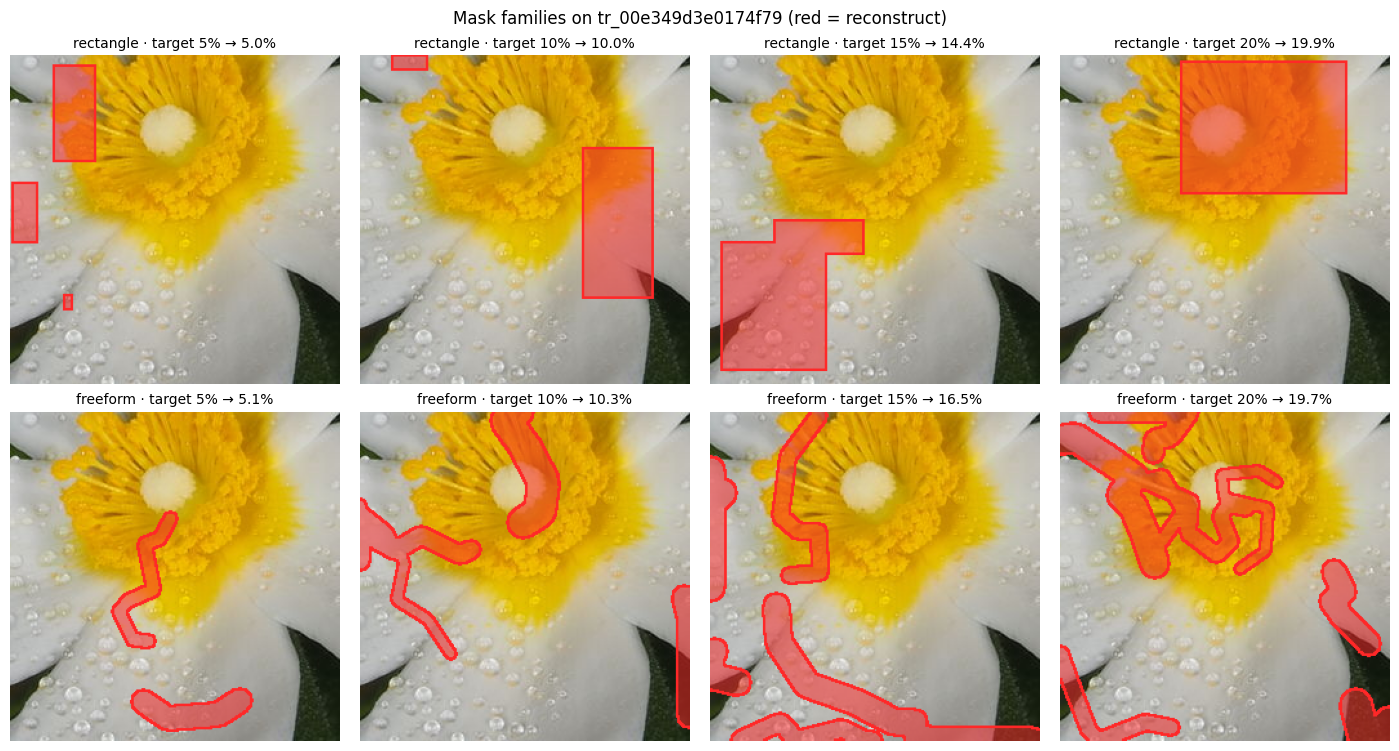

In [6]:
# Preview rectangle and free-form masks at four target coverages.
import matplotlib.pyplot as plt
import numpy as np

import src.data.inpaint_masks as masks_module
importlib.reload(masks_module)  # pick up edits when cells are rerun
from src.data.inpaint_masks import (MANIFEST_FIELDS, MASK_TYPES, apply_mask, build_eval_mask_set, coverage,
                                    load_mask_png, make_mask, overlay, read_rgb, seed_for,
                                    verify_eval_mask_set)

preview_row = sorted(manifests["val"], key=lambda r: r["sample_id"])[0]
preview_crop = read_rgb(PREPARED_DIR / preview_row["eval_crop_path"])
fig, axes = plt.subplots(2, 4, figsize=(14, 7.4), layout="constrained")
for r, mask_type in enumerate(MASK_TYPES):
    for c, target in enumerate((0.05, 0.10, 0.15, 0.20)):
        mask, params = make_mask(np.random.default_rng(seed_for(SEED, "preview", mask_type, target)),
                                 256, 256, mask_type, target)
        axes[r, c].imshow(overlay(preview_crop, mask))
        axes[r, c].set_title(f"{mask_type} · target {target:.0%} → {params['coverage']:.1%}", fontsize=10)
        axes[r, c].axis("off")
fig.suptitle(f"Mask families on {preview_row['sample_id']} (red = reconstruct)")
plt.show()

### 4.3 Generate the fixed validation and test masks

For every saved evaluation crop, write the mask, the masked input and one manifest row. The manifest uses the team fields (`sample_id, source_image_id, split, task, input_path, target_path, mask_path, crop_coordinates, degradation_parameters, seed`) plus `mask_type`, `mask_coverage`, `coverage_bin` and `mask_sha256`. `source_image_id` is the official folder plus file name, so the original photo is unambiguous.

The first run saves a copy of each manifest to Drive. Later runs regenerate the masks and compare every mask hash with that frozen copy, stopping if anything differs.

In [7]:
# Write fixed masks, masked inputs and manifests; compare with the frozen copies in Drive.
inpaint_manifests, INPAINT_MANIFEST = {}, {}
for split in ("val", "test"):
    start = time.perf_counter()
    rows = build_eval_mask_set(PREPARED_DIR, manifests[split], split, SEED, INPAINT_REL)
    path = PREPARED_DIR / INPAINT_REL / f"inpainting_{split}.csv"
    write_csv(path, rows, MANIFEST_FIELDS)
    frozen = OUTPUT_DIR / f"inpainting_{split}.csv"
    if frozen.is_file():
        previous = {r["sample_id"]: r["mask_sha256"] for r in read_csv(frozen)}
        changed = [r["sample_id"] for r in rows if previous.get(r["sample_id"]) != r["mask_sha256"]]
        if changed or len(previous) != len(rows):
            raise RuntimeError(f"{split}: {len(changed)} masks differ from the frozen copy {frozen}. "
                               "Masks must stay fixed; investigate before continuing.")
        status = "identical to the frozen copy in Drive"
    else:
        shutil.copy2(path, frozen)
        status = "saved as the frozen copy in Drive"
    inpaint_manifests[split], INPAINT_MANIFEST[split] = rows, path
    print(f"{split:5s} {len(rows):4d} masks in {time.perf_counter() - start:4.1f}s · {status}")

(PREPARED_DIR / INPAINT_REL / "README.md").write_text(
    "# PlantSR inpainting masks v1\n\n"
    "Paths in inpainting_{val,test}.csv are relative to prepared/.\n"
    "Masks: single-channel PNG, 255 = missing/reconstruct, 0 = preserve.\n"
    "Inputs: evaluation crop with missing pixels set to 128 (grey).\n"
    f"Generator: src/data/inpaint_masks.py, base seed {SEED}, coverage 5-20%, rectangle/free-form alternating.\n",
    encoding="utf-8")
print("Example row:", {k: inpaint_manifests["val"][0][k] for k in ("sample_id", "source_image_id", "mask_type",
                                                                  "mask_coverage", "mask_path")})

val    166 masks in  7.4s · identical to the frozen copy in Drive
test   200 masks in 12.5s · identical to the frozen copy in Drive
Example row: {'sample_id': 'tr_00e349d3e0174f79', 'source_image_id': 'official_train/img132.jpg', 'mask_type': 'rectangle', 'mask_coverage': '0.12360', 'mask_path': 'derived/inpainting_v1/masks/val/tr_00e349d3e0174f79.png'}


### 4.4 Verify covered-area ratios

Summarise the achieved coverage by split and mask type, count masks per coverage bin, and plot the distributions. Every mask must fall inside 5–20%; the generator accepts a candidate only when it is within ±15% (relative) of its target.

count     min    mean     max
split mask_type                               
test  freeform     100  0.0530  0.1327  0.1996
      rectangle    100  0.0505  0.1229  0.1999
val   freeform      83  0.0536  0.1325  0.1995
      rectangle     83  0.0514  0.1233  0.1986

coverage_bin     large_15_20  medium_10_15  small_5_10
split mask_type                                       
test  freeform            41            30          29
      rectangle           31            34          35
val   freeform            32            27          24
      rectangle           23            32          28

Largest relative deviation from target: 15.0%


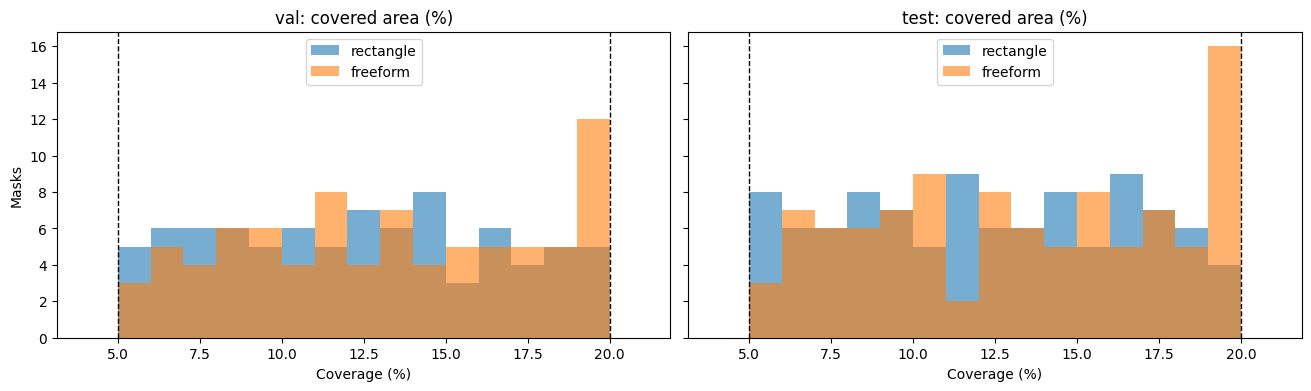

All masks are within the 5–20% coverage range.


In [8]:
# Coverage statistics, bin counts and histograms for the fixed masks.
import pandas as pd

coverage_df = pd.DataFrame([
    {"split": r["split"], "mask_type": r["mask_type"], "coverage": float(r["mask_coverage"]),
     "coverage_bin": r["coverage_bin"],
     "target": json.loads(r["degradation_parameters"])["target_coverage"]}
    for split in ("val", "test") for r in inpaint_manifests[split]])
coverage_df["relative_error"] = (coverage_df.coverage - coverage_df.target).abs() / coverage_df.target
display(coverage_df.groupby(["split", "mask_type"]).coverage.agg(["count", "min", "mean", "max"]).round(4))
display(pd.crosstab([coverage_df.split, coverage_df.mask_type], coverage_df.coverage_bin))
print(f"Largest relative deviation from target: {coverage_df.relative_error.max():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True, layout="constrained")
for ax, split in zip(axes, ("val", "test")):
    for mask_type in MASK_TYPES:
        values = coverage_df.query("split == @split and mask_type == @mask_type").coverage * 100
        ax.hist(values, bins=np.arange(4, 21.5, 1), alpha=0.6, label=mask_type)
    for limit in (5, 20):
        ax.axvline(limit, color="k", linestyle="--", linewidth=1)
    ax.set_title(f"{split}: covered area (%)")
    ax.set_xlabel("Coverage (%)")
    ax.legend()
axes[0].set_ylabel("Masks")
plt.show()

out_of_range = coverage_df[(coverage_df.coverage < 0.05) | (coverage_df.coverage > 0.20)]
if len(out_of_range):
    raise ValueError(f"{len(out_of_range)} masks fall outside 5–20% coverage")
print("All masks are within the 5–20% coverage range.")

### 4.5 Verify alignment

Check every fixed mask against its crop:

1. mask, target crop and masked input have the same 256 × 256 size; the mask PNG is strictly 0/255;
2. stored coverage and mask hash match the manifest;
3. the masked input equals the target on every preserved pixel and is grey on every missing pixel;
4. the saved crop equals the full-size image cropped at the recorded coordinates (Peng's center-crop alignment);
5. the diffusion model sees the same region: resizing the mask to `WORK_RES` with nearest-neighbour sampling and back reproduces it exactly (2× upsampling is lossless).

In [9]:
# Pixel-level alignment checks for all validation and test masks.
alignment = {}
for split in ("val", "test"):
    problems = verify_eval_mask_set(PREPARED_DIR, inpaint_manifests[split], manifests[split])
    alignment[split] = problems
    print(f"{split:5s} {len(inpaint_manifests[split])} masks checked · {len(problems)} problems")
    for problem in problems[:10]:
        print("   ", problem)

ious = []
for row in inpaint_manifests["val"] + inpaint_manifests["test"]:
    mask = load_mask_png(PREPARED_DIR / row["mask_path"]).astype(bool)
    up = Image.fromarray(mask.astype(np.uint8) * 255).resize((WORK_RES, WORK_RES), Image.NEAREST)
    back = np.asarray(up.resize(mask.shape[::-1], Image.NEAREST)) > 127
    ious.append((mask & back).sum() / (mask | back).sum())
print(f"Mask round trip 256 → {WORK_RES} → 256: minimum IoU {min(ious):.4f}")

if any(alignment.values()):
    raise ValueError("Alignment problems found; see the messages above.")
if WORK_RES % 256 == 0 and min(ious) < 1.0:
    raise ValueError("Integer upsampling should reproduce the masks exactly.")
print("All alignment checks passed.")

val   166 masks checked · 0 problems
test  200 masks checked · 0 problems
Mask round trip 256 → 512 → 256: minimum IoU 1.0000
All alignment checks passed.


### 4.6 Inspect a gallery of fixed masks

Twelve validation masks chosen across the coverage range: the clean crop, the masked input the models receive, and the overlay.

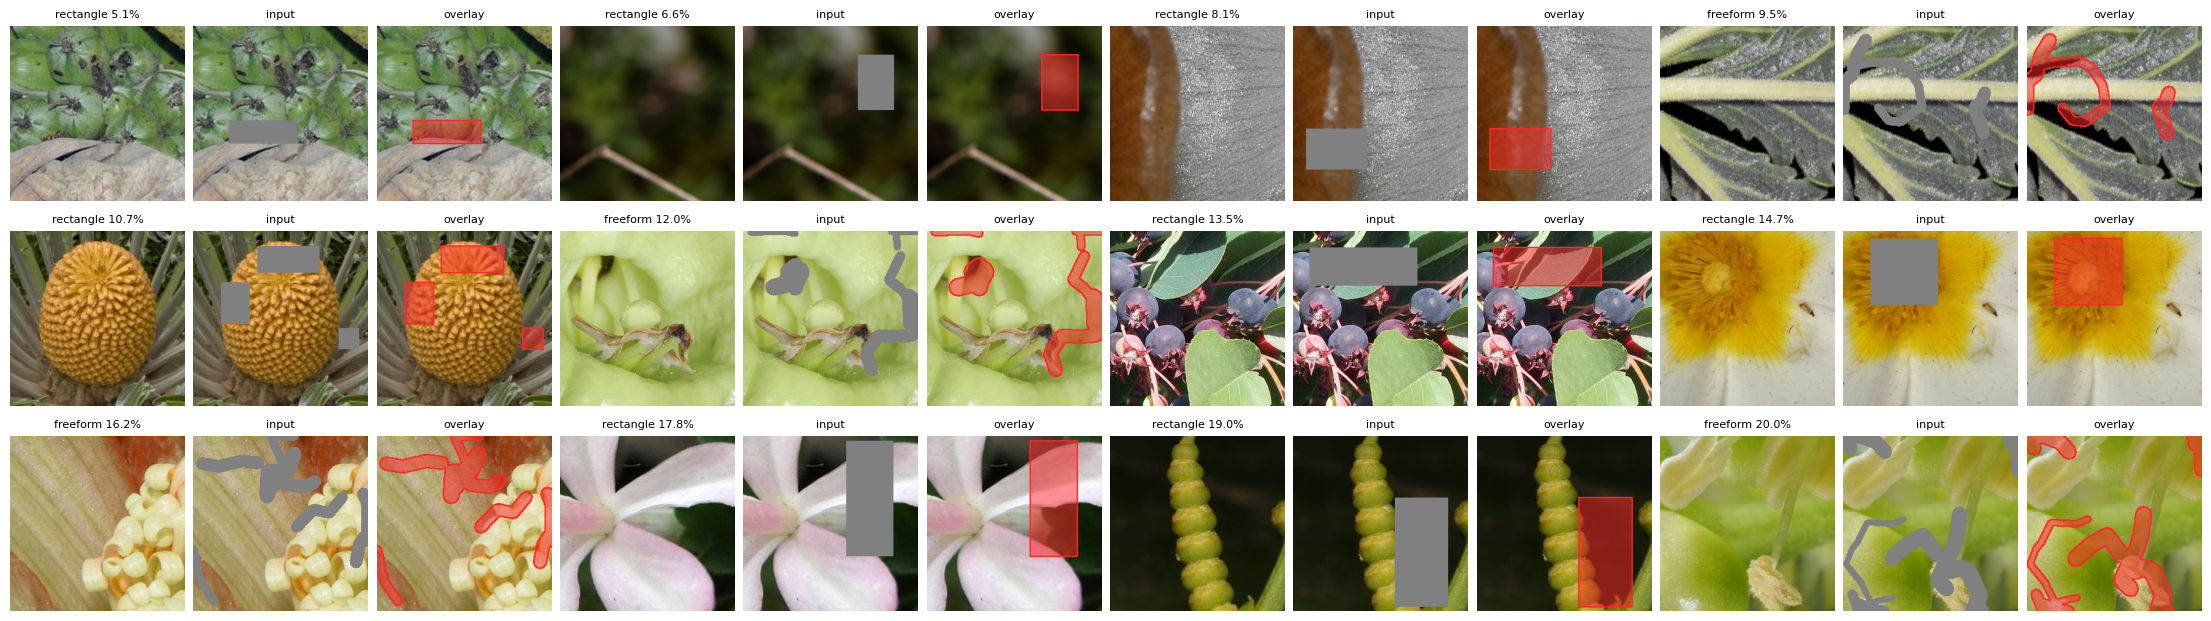

In [10]:
# Show clean crop, masked input and overlay for 12 validation masks spread over the coverage range.
by_coverage = sorted(inpaint_manifests["val"], key=lambda r: float(r["mask_coverage"]))
gallery = [by_coverage[i] for i in np.linspace(0, len(by_coverage) - 1, min(12, len(by_coverage))).astype(int)]
gallery_rows = len(gallery) // 4 + (len(gallery) % 4 > 0)
fig, axes = plt.subplots(gallery_rows, 12, figsize=(22, 2.05 * gallery_rows), layout="constrained", squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for i, row in enumerate(gallery):
    target = read_rgb(PREPARED_DIR / row["target_path"])
    masked = read_rgb(PREPARED_DIR / row["input_path"])
    mask = load_mask_png(PREPARED_DIR / row["mask_path"])
    r, c = divmod(i, 4)
    for j, (img, label) in enumerate(((target, "clean"), (masked, "input"), (overlay(target, mask), "overlay"))):
        axes[r, c * 3 + j].imshow(img)
        axes[r, c * 3 + j].set_title(f"{label}" if j else f"{row['mask_type']} {float(row['mask_coverage']):.1%}",
                                     fontsize=8)
plt.show()

### 4.7 Package the masks for the team

Zip `prepared/derived/inpainting_v1/` (manifests, masks, masked inputs and a short README) into Drive. Extracting the ZIP in the same folder as `PlantSR_prepared_for_team.zip` merges it into the existing `prepared/` tree, so all manifest paths resolve without changes.

In [11]:
# Zip the fixed inpainting set into Drive for teammates.
masks_zip = OUTPUT_DIR / "PlantSR_inpainting_masks_v1.zip"
with zipfile.ZipFile(masks_zip, "w", compression=zipfile.ZIP_STORED) as archive:
    for path in sorted((PREPARED_DIR / INPAINT_REL).rglob("*")):
        if path.is_file():
            archive.write(path, arcname=Path("prepared") / path.relative_to(PREPARED_DIR))
print(f"{masks_zip}  ({masks_zip.stat().st_size / 1024**2:.1f} MB)")

/content/drive/MyDrive/AAI521/Final_project/inpainting_week1/PlantSR_inpainting_masks_v1.zip  (30.6 MB)


## 5 · Metrics and the common inference interface

### 5.1 Inpainting metrics

After compositing (`final = (1 - mask) * input + mask * generated`) every visible pixel is copied, so full-image scores mostly measure the copied area. The metrics therefore focus on the missing region and its boundary:

| Metric | Region | Direction |
|---|---|---|
| `masked_psnr`, `masked_l1` | missing pixels | PSNR ↑, L1 ↓ |
| `masked_ssim` | SSIM map averaged over missing pixels (7 × 7 windows include context at the edge) | ↑ |
| `boundary_l1`, `boundary_grad_l1` | 3-px band on both sides of the mask edge: colour and gradient error, where seams appear | ↓ |
| `masked_bbox_lpips` | LPIPS (AlexNet) on the padded bounding box of the missing region | ↓ |
| `full_psnr_supplementary`, `full_ssim_supplementary` | whole crop; reported only as supplementary results | ↑ |

Rows are written in the team's long results format: `sample_id, task, method, checkpoint_revision, seed, metric_name, metric_value, inference_seconds, status, error_note`.

In [12]:
%%writefile "{CODE_DIR}/src/evaluation/inpaint_metrics.py"
"""Inpainting metrics focused on the missing region and its boundary.

All functions take RGB uint8 arrays (H, W, 3) or float arrays in [0, 1] and a mask with
1 = missing/reconstructed, 0 = preserved. Full-image scores are supplementary only: when
visible pixels are copied back by compositing they inflate full-image PSNR/SSIM.
"""
from __future__ import annotations

import math

import cv2
import numpy as np
from skimage.metrics import structural_similarity

RESULT_FIELDS = ["sample_id", "task", "method", "checkpoint_revision", "seed", "metric_name",
                 "metric_value", "inference_seconds", "status", "error_note"]


def to_float(image) -> np.ndarray:
    arr = np.asarray(image)
    if arr.dtype == np.uint8:
        return arr.astype(np.float32) / 255.0
    return np.clip(arr.astype(np.float32), 0.0, 1.0)


def as_mask(mask) -> np.ndarray:
    arr = np.asarray(mask)
    if arr.ndim == 3:
        arr = arr[..., 0]
    return arr > (127 if arr.dtype == np.uint8 and arr.max() > 1 else 0.5)


def composite(known, generated, mask) -> np.ndarray:
    """final = (1 - mask) * known + mask * generated, returned as uint8 RGB."""
    m = as_mask(mask)[..., None]
    out = np.where(m, np.asarray(generated, np.uint8), np.asarray(known, np.uint8))
    return out.astype(np.uint8)


def _psnr(mse: float) -> float:
    return float("inf") if mse <= 1e-12 else 10.0 * math.log10(1.0 / mse)


def boundary_band(mask, width: int = 3) -> np.ndarray:
    """Pixels within `width` px on either side of the mask edge (where seams appear)."""
    m = as_mask(mask).astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * width + 1, 2 * width + 1))
    return (cv2.dilate(m, kernel) > 0) & ~(cv2.erode(m, kernel) > 0)


def _gradient_magnitude(rgb: np.ndarray) -> np.ndarray:
    gray = cv2.cvtColor((rgb * 255).astype(np.float32), cv2.COLOR_RGB2GRAY) / 255.0
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    return np.sqrt(gx * gx + gy * gy)


def _bbox(mask: np.ndarray, pad: int, min_size: int, shape) -> tuple[int, int, int, int]:
    ys, xs = np.nonzero(mask)
    h, w = shape
    def span(lo, hi, limit):
        lo, hi = max(0, lo - pad), min(limit, hi + 1 + pad)
        if hi - lo < min_size:  # grow small boxes symmetrically, staying inside the image
            lo = max(0, lo - (min_size - (hi - lo)) // 2)
            hi = min(limit, lo + min_size)
            lo = max(0, hi - min_size)
        return int(lo), int(hi)

    x0, x1 = span(xs.min(), xs.max(), w)
    y0, y1 = span(ys.min(), ys.max(), h)
    return x0, y0, x1, y1


class LPIPSMetric:
    """LPIPS on the padded bounding box of the missing region (optional dependency)."""

    def __init__(self, net: str = "alex", device: str | None = None, pad: int = 8, min_size: int = 64):
        import lpips  # noqa: WPS433 - optional dependency
        import torch

        self.torch = torch
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.model = lpips.LPIPS(net=net, verbose=False).to(self.device).eval()
        self.pad, self.min_size = pad, min_size

    def __call__(self, output, reference, mask) -> float:
        out, ref, m = to_float(output), to_float(reference), as_mask(mask)
        x0, y0, x1, y1 = _bbox(m, self.pad, self.min_size, m.shape)
        tensors = [
            self.torch.from_numpy(a[y0:y1, x0:x1]).permute(2, 0, 1)[None].to(self.device) * 2 - 1
            for a in (out, ref)
        ]
        with self.torch.no_grad():
            return float(self.model(*tensors).item())


def inpaint_metrics(output, reference, mask, lpips_fn=None, band_width: int = 3) -> dict:
    """Missing-region, boundary and (supplementary) full-image metrics."""
    out, ref, m = to_float(output), to_float(reference), as_mask(mask)
    if out.shape != ref.shape or out.shape[:2] != m.shape:
        raise ValueError(f"Shape mismatch: output {out.shape}, reference {ref.shape}, mask {m.shape}")
    if not m.any():
        raise ValueError("Mask is empty; nothing to evaluate.")
    diff = out - ref
    hole = diff[m]
    band = boundary_band(m, band_width)
    ssim_full, ssim_map = structural_similarity(ref, out, channel_axis=2, data_range=1.0, full=True)
    ssim_map = ssim_map.mean(axis=2)
    grad_out, grad_ref = _gradient_magnitude(out), _gradient_magnitude(ref)
    metrics = {
        "mask_coverage": float(m.mean()),
        "masked_l1": float(np.abs(hole).mean()),
        "masked_psnr": _psnr(float((hole ** 2).mean())),
        "masked_ssim": float(ssim_map[m].mean()),
        "boundary_l1": float(np.abs(diff[band]).mean()),
        "boundary_grad_l1": float(np.abs(grad_out[band] - grad_ref[band]).mean()),
        "full_psnr_supplementary": _psnr(float((diff ** 2).mean())),
        "full_ssim_supplementary": float(ssim_full),
    }
    if lpips_fn is not None:
        metrics["masked_bbox_lpips"] = lpips_fn(out, ref, m)
    return metrics


def full_metrics(output, reference) -> dict:
    """PSNR/SSIM for tasks without a mask (denoising, SR, colorization)."""
    out, ref = to_float(output), to_float(reference)
    if out.shape != ref.shape:
        raise ValueError(f"Shape mismatch: output {out.shape}, reference {ref.shape}")
    return {
        "psnr": _psnr(float(((out - ref) ** 2).mean())),
        "ssim": float(structural_similarity(ref, out, channel_axis=2, data_range=1.0)),
    }


def result_rows(sample_id, method, metrics: dict | None, *, task="inpainting", checkpoint_revision="",
                seed="", inference_seconds=None, status="ok", error_note=""):
    """Long-format rows matching the team's results fields."""
    base = {"sample_id": sample_id, "task": task, "method": method,
            "checkpoint_revision": checkpoint_revision, "seed": seed,
            "inference_seconds": "" if inference_seconds is None else round(float(inference_seconds), 4),
            "status": status, "error_note": error_note}
    if not metrics:
        return [{**base, "metric_name": "", "metric_value": ""}]
    return [{**base, "metric_name": k, "metric_value": v} for k, v in metrics.items()]

Writing /content/AAI521-Group1-PlantSR-Restoration/src/evaluation/inpaint_metrics.py


### 5.2 Inference interface, baselines and the diffusion wrapper

- `src/inference/interface.py` defines `restore(image, task, mask=None, seed=42)`, the `RestoreResult` returned to callers, the `TaskHandler` base class each teammate implements, and a `Registry` that loads models lazily, keeps at most one large GPU model in memory and serialises GPU work with a lock.
- `src/inference/baselines.py` registers simple baselines for all four tasks (OpenCV Telea and Navier–Stokes inpainting, non-local means, bicubic ×4, grayscale), so the app runs every task before the fine-tuned models are ready.
- `src/inference/sd_inpaint.py` wraps Stable Diffusion inpainting: upsample to the working resolution, generate, resize back, then composite the missing region only.
- `src/inference/factory.py` builds the application registry from `configs/app.json`.

In [13]:
%%writefile "{CODE_DIR}/src/inference/interface.py"
"""Common inference interface shared by the four restoration tasks.

    result = restore(image, task, mask=None, seed=42)            # agreed team signature
    result = restore(image, task, mask=None, seed=42, method="sd15_finetuned")  # optional extra

Each task owner implements a `TaskHandler` subclass (see docs/inference_interface.md).
The `Registry` keeps at most `max_gpu_models` GPU models loaded, serialises GPU work with a
lock, times every call and converts failures into a result object instead of an exception.
"""
from __future__ import annotations

import gc
import threading
import time
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
from PIL import Image, ImageOps

TASKS = ("denoising", "super_resolution", "colorization", "inpainting")
TASK_LABELS = {
    "denoising": "Denoising",
    "super_resolution": "Super-resolution (4x)",
    "colorization": "Colorization",
    "inpainting": "Inpainting",
}


@dataclass
class RestoreResult:
    image: Image.Image | None
    task: str
    method: str
    model_version: str
    input_size: tuple[int, int]          # (width, height) received
    processed_size: tuple[int, int]      # (width, height) the model actually ran at
    output_size: tuple[int, int]         # (width, height) of the returned image
    elapsed_seconds: float
    success: bool
    error: str | None = None
    extra: dict = field(default_factory=dict)

    def metadata(self) -> dict:
        """JSON-safe summary (everything except the image)."""
        return {
            "task": self.task, "method": self.method, "model_version": self.model_version,
            "input_size": list(self.input_size), "processed_size": list(self.processed_size),
            "output_size": list(self.output_size), "elapsed_seconds": round(self.elapsed_seconds, 3),
            "success": self.success, "error": self.error, **self.extra,
        }


class TaskHandler:
    """Base class for one restoration method of one task.

    Subclasses set the class attributes and implement `run`; heavy models also implement
    `load`/`unload` so the registry can move them on and off the GPU.
    """

    task: str = ""
    method: str = ""
    version: str = ""
    label: str = ""
    description: str = ""
    uses_gpu: bool = False
    needs_mask: bool = False
    generative: bool = False  # True when the seed changes the output

    def __init__(self):
        self._loaded = not self.uses_gpu

    @property
    def loaded(self) -> bool:
        return self._loaded

    def load(self) -> None:
        self._loaded = True

    def unload(self) -> None:
        self._loaded = not self.uses_gpu

    def run(self, image: Image.Image, mask: np.ndarray | None, seed: int):
        """Return (output PIL image, processed (width, height))."""
        raise NotImplementedError

    def describe(self) -> dict:
        return {"method": self.method, "label": self.label or self.method, "version": self.version,
                "description": self.description, "uses_gpu": self.uses_gpu,
                "generative": self.generative, "loaded": self.loaded}


def normalize_image(image) -> Image.Image:
    """Accept a path, PIL image or array and return an RGB PIL image."""
    if isinstance(image, (str, Path)):
        with Image.open(image) as src:
            image = ImageOps.exif_transpose(src)
            image.load()
    elif isinstance(image, np.ndarray):
        arr = image
        if arr.dtype != np.uint8:
            arr = (np.clip(arr, 0, 1) * 255).round().astype(np.uint8)
        image = Image.fromarray(arr)
    if not isinstance(image, Image.Image):
        raise TypeError(f"Unsupported image type: {type(image).__name__}")
    if image.mode in ("RGBA", "LA") or (image.mode == "P" and "transparency" in image.info):
        rgba = image.convert("RGBA")
        background = Image.new("RGBA", rgba.size, (255, 255, 255, 255))
        image = Image.alpha_composite(background, rgba)
    return image.convert("RGB")


def normalize_mask(mask, size: tuple[int, int]) -> np.ndarray:
    """Return a uint8 {0,1} mask of shape (height, width); 1 = missing/reconstruct."""
    if isinstance(mask, (str, Path)):
        with Image.open(mask) as src:
            mask = src.convert("L")
            mask.load()
    if isinstance(mask, Image.Image):
        if mask.mode in ("RGBA", "LA"):
            alpha = np.asarray(mask.getchannel("A"))
            gray = np.asarray(mask.convert("L"))
            mask = Image.fromarray(np.where(alpha > 0, gray, 0).astype(np.uint8))
        if mask.size != size:
            mask = mask.convert("L").resize(size, Image.NEAREST)
        arr = np.asarray(mask.convert("L")) > 127
    else:
        arr = np.asarray(mask)
        if arr.ndim == 3:
            arr = arr[..., 0]
        threshold = 127 if arr.dtype == np.uint8 and arr.max() > 1 else 0.5
        arr = arr > threshold
        if arr.shape != (size[1], size[0]):
            arr = np.asarray(Image.fromarray(arr.astype(np.uint8) * 255).resize(size, Image.NEAREST)) > 127
    return arr.astype(np.uint8)


class Registry:
    def __init__(self, max_gpu_models: int = 1):
        self.max_gpu_models = max_gpu_models
        self._handlers: dict[str, dict[str, TaskHandler]] = {task: {} for task in TASKS}
        self._defaults: dict[str, str] = {}
        self._lock = threading.RLock()
        self._last_used: dict[tuple[str, str], float] = {}

    # ------------------------------------------------------------------ registration
    def register(self, handler: TaskHandler, default: bool = False) -> TaskHandler:
        if handler.task not in TASKS:
            raise ValueError(f"Unknown task {handler.task!r}")
        self._handlers[handler.task][handler.method] = handler
        if default or handler.task not in self._defaults:
            self._defaults[handler.task] = handler.method
        return handler

    def set_default(self, task: str, method: str) -> None:
        self.handler(task, method)  # validates the pair
        self._defaults[task] = method

    def handler(self, task: str, method: str | None = None) -> TaskHandler:
        if task not in TASKS:
            raise ValueError(f"Unknown task {task!r}; choose one of {TASKS}")
        methods = self._handlers[task]
        if not methods:
            raise ValueError(f"No method is registered for {task!r}")
        method = method or self._defaults[task]
        if method not in methods:
            raise ValueError(f"Unknown method {method!r} for {task!r}; available: {sorted(methods)}")
        return methods[method]

    def describe(self) -> list[dict]:
        return [{
            "task": task, "label": TASK_LABELS[task],
            "needs_mask": any(h.needs_mask for h in self._handlers[task].values()),
            "default_method": self._defaults.get(task),
            "methods": [h.describe() for h in self._handlers[task].values()],
        } for task in TASKS]

    # ------------------------------------------------------------------ GPU memory
    def _ensure_loaded(self, target: TaskHandler) -> None:
        if target.loaded:
            return
        if target.uses_gpu:
            loaded = [h for methods in self._handlers.values() for h in methods.values()
                      if h.uses_gpu and h.loaded and h is not target]
            loaded.sort(key=lambda h: self._last_used.get((h.task, h.method), 0.0))
            while len(loaded) >= self.max_gpu_models:
                loaded.pop(0).unload()
                free_gpu_memory()
        target.load()

    def unload_all(self) -> None:
        with self._lock:
            for methods in self._handlers.values():
                for h in methods.values():
                    if h.uses_gpu and h.loaded:
                        h.unload()
            free_gpu_memory()

    # ------------------------------------------------------------------ inference
    def restore(self, image, task: str, mask=None, seed: int = 42, method: str | None = None) -> RestoreResult:
        start = time.perf_counter()
        input_size = (0, 0)
        handler = None
        try:
            handler = self.handler(task, method)
            pil = normalize_image(image)
            input_size = pil.size
            mask_arr = None
            if handler.needs_mask:
                if mask is None:
                    raise ValueError("This task needs a mask (white = area to fill).")
                mask_arr = normalize_mask(mask, pil.size)
                if not mask_arr.any():
                    raise ValueError("The mask is empty. Paint or upload the area to fill (white = missing).")
                if mask_arr.all():
                    raise ValueError("The mask covers the whole image; leave some context visible.")
            with self._lock:
                self._ensure_loaded(handler)
                self._last_used[(handler.task, handler.method)] = time.time()
                output, processed = handler.run(pil, mask_arr, int(seed))
            output = normalize_image(output)
            extra = {"mask_coverage": round(float(mask_arr.mean()), 5)} if mask_arr is not None else {}
            return RestoreResult(output, task, handler.method, handler.version, input_size,
                                 tuple(processed), output.size, time.perf_counter() - start, True, None, extra)
        except Exception as exc:  # noqa: BLE001 - report every failure to the caller
            message = str(exc) if isinstance(exc, ValueError) else f"{type(exc).__name__}: {exc}"
            if "out of memory" in str(exc).lower():
                message = "GPU out of memory. Try a smaller image or retry after other jobs finish. " + message
                if handler is not None and handler.uses_gpu:
                    handler.unload()
                free_gpu_memory()
            return RestoreResult(None, task, getattr(handler, "method", method or ""),
                                 getattr(handler, "version", ""), input_size, (0, 0), (0, 0),
                                 time.perf_counter() - start, False, message)


def free_gpu_memory() -> None:
    gc.collect()
    try:
        import torch

        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except ImportError:
        pass


_default_registry: Registry | None = None


def set_default_registry(registry: Registry) -> None:
    global _default_registry
    _default_registry = registry


def restore(image, task: str, mask=None, seed: int = 42, method: str | None = None) -> RestoreResult:
    """Team-wide entry point. Uses the registry configured with `set_default_registry`."""
    if _default_registry is None:
        raise RuntimeError("No registry configured; call set_default_registry(build_registry(...)) first.")
    return _default_registry.restore(image, task, mask=mask, seed=seed, method=method)

Writing /content/AAI521-Group1-PlantSR-Restoration/src/inference/interface.py


In [14]:
%%writefile "{CODE_DIR}/src/inference/baselines.py"
"""Simple, CPU-only baselines for all four tasks.

They follow the team evaluation table (README section 7) and let the application run every
task end to end before the fine-tuned models are integrated. Each one is labelled as a
baseline in the UI so it is never mistaken for a learned model.
"""
from __future__ import annotations

import cv2
import numpy as np
from PIL import Image

from .interface import TaskHandler


def _fit(image: Image.Image, max_side: int | None) -> Image.Image:
    if not max_side or max(image.size) <= max_side:
        return image
    scale = max_side / max(image.size)
    size = (max(1, round(image.width * scale)), max(1, round(image.height * scale)))
    return image.resize(size, Image.LANCZOS)


class OpenCVInpaint(TaskHandler):
    task = "inpainting"
    needs_mask = True

    def __init__(self, flag: str = "telea", radius: int = 5):
        self.flag = flag
        self.radius = radius
        self.method = f"opencv_{flag}"
        self.label = {"telea": "OpenCV Telea (baseline)", "ns": "OpenCV Navier-Stokes (baseline)"}[flag]
        self.version = f"opencv-{cv2.__version__}-{flag}-r{radius}"
        self.description = "Classical diffusion-based fill from the hole boundary. No learning."
        super().__init__()

    def run(self, image, mask, seed):
        rgb = np.asarray(image)
        flag = cv2.INPAINT_TELEA if self.flag == "telea" else cv2.INPAINT_NS
        filled = cv2.inpaint(rgb, (mask > 0).astype(np.uint8) * 255, self.radius, flag)
        out = np.where(mask[..., None] > 0, filled, rgb).astype(np.uint8)
        return Image.fromarray(out), image.size


class NLMeansDenoise(TaskHandler):
    task = "denoising"
    method = "opencv_nlmeans"
    label = "Non-local means (baseline)"
    description = "OpenCV fastNlMeansDenoisingColored (h=10). Large images are reduced to 1024 px."

    def __init__(self, strength: int = 10, max_side: int = 1024):
        self.strength, self.max_side = strength, max_side
        self.version = f"opencv-{cv2.__version__}-nlmeans-h{strength}"
        super().__init__()

    def run(self, image, mask, seed):
        work = _fit(image, self.max_side)
        out = cv2.fastNlMeansDenoisingColored(np.asarray(work), None, self.strength, self.strength, 7, 21)
        return Image.fromarray(out), work.size


class BicubicSR(TaskHandler):
    task = "super_resolution"
    method = "bicubic_x4"
    label = "Bicubic x4 (baseline)"
    description = "Bicubic 4x upscaling. Inputs larger than 512 px are reduced first."

    def __init__(self, scale: int = 4, max_input_side: int = 512):
        self.scale, self.max_input_side = scale, max_input_side
        self.version = f"pil-bicubic-x{scale}"
        super().__init__()

    def run(self, image, mask, seed):
        work = _fit(image, self.max_input_side)
        out = work.resize((work.width * self.scale, work.height * self.scale), Image.BICUBIC)
        return out, work.size


class GrayscaleColorization(TaskHandler):
    task = "colorization"
    method = "grayscale_rgb"
    label = "Grayscale as RGB (weak baseline)"
    version = "pil-grayscale"
    description = "Returns the luminance replicated to three channels. A deliberately weak reference."

    def run(self, image, mask, seed):
        return image.convert("L").convert("RGB"), image.size


def register_baselines(registry) -> None:
    registry.register(OpenCVInpaint("telea"))
    registry.register(OpenCVInpaint("ns"))
    registry.register(NLMeansDenoise())
    registry.register(BicubicSR())
    registry.register(GrayscaleColorization())

Writing /content/AAI521-Group1-PlantSR-Restoration/src/inference/baselines.py


In [15]:
%%writefile "{CODE_DIR}/src/inference/sd_inpaint.py"
"""Stable Diffusion 1.5 inpainting handler (pretrained or with a PlantSR LoRA adapter).

Model: stable-diffusion-v1-5/stable-diffusion-inpainting (CreativeML OpenRAIL-M). Its UNet
takes 9 input channels: 4 noisy latents + 1 mask + 4 latents of the masked image. White
(1) in the mask means "repaint", which matches the team convention.

The model was trained at 512 x 512, so 256 x 256 benchmark crops are upsampled to the
working resolution, inpainted, resized back and composited:
    final = (1 - mask) * input + mask * generated
Visible pixels are therefore copied exactly; only the missing region comes from the model.
"""
from __future__ import annotations

import hashlib
import re
import warnings
from pathlib import Path

import numpy as np
from PIL import Image

from .interface import TaskHandler, free_gpu_memory

DEFAULT_MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-inpainting"
DEFAULT_PROMPT = "a high-resolution photo of a plant, natural leaves, sharp focus"
DEFAULT_NEGATIVE = "blurry, text, watermark, frame, border, cartoon, painting"
FILL_VALUE = 128


def pick_device(prefer: str | None = None):
    import torch

    if prefer:
        device = torch.device(prefer)
    elif torch.cuda.is_available():
        device = torch.device("cuda")
    else:
        device = torch.device("cpu")
    dtype = torch.float16 if device.type == "cuda" else torch.float32
    return device, dtype


def load_inpaint_pipeline(model_id: str = DEFAULT_MODEL_ID, device=None, dtype=None, scheduler: str = "dpm",
                          local_files_only: bool = False):
    """Load the inpainting pipeline (fp16 weights on GPU when available, no safety checker).

    The safety checker is disabled because it blacks out false positives, which would corrupt
    benchmark metrics on plant photos; inputs are user photos of plants, not text prompts.
    """
    import torch
    from diffusers import DPMSolverMultistepScheduler, StableDiffusionInpaintPipeline

    if device is None or dtype is None:
        auto_device, auto_dtype = pick_device()
        device = device or auto_device
        dtype = dtype or auto_dtype
    kwargs = dict(torch_dtype=dtype, safety_checker=None, requires_safety_checker=False,
                  local_files_only=local_files_only)
    pipe = None
    warnings.filterwarnings("ignore", message=".*`torch_dtype` is deprecated.*")  # newer diffusers prefer `dtype`
    if dtype == torch.float16:
        try:
            pipe = StableDiffusionInpaintPipeline.from_pretrained(model_id, variant="fp16", **kwargs)
        except (OSError, ValueError):
            pipe = None  # no fp16 variant files: load the default weights and cast
    if pipe is None:
        pipe = StableDiffusionInpaintPipeline.from_pretrained(model_id, **kwargs)
    if scheduler == "dpm":
        pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
    pipe.set_progress_bar_config(disable=True)
    return pipe.to(device)


def snapshot_revision(pipe) -> str:
    """Hugging Face commit hash of the loaded base weights, when loaded from the hub cache."""
    path = str(getattr(pipe.unet.config, "_name_or_path", ""))
    match = re.search(r"snapshots[\\/]([0-9a-f]{40})", path)
    return match.group(1)[:12] if match else "local"


def model_size(width: int, height: int, work_res: int, multiple: int = 8) -> tuple[int, int]:
    """Scale so the long side equals `work_res`, rounding both sides to a multiple of 8."""
    scale = work_res / max(width, height)
    w = max(multiple, int(round(width * scale / multiple)) * multiple)
    h = max(multiple, int(round(height * scale / multiple)) * multiple)
    return w, h


def lora_file(lora_path) -> Path:
    path = Path(lora_path)
    if path.is_dir():
        candidates = sorted(path.glob("*.safetensors"))
        if not candidates:
            raise FileNotFoundError(f"No .safetensors LoRA file in {path}")
        return candidates[0]
    return path


def short_hash(path) -> str:
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()[:12]


class StableDiffusionInpaint(TaskHandler):
    task = "inpainting"
    uses_gpu = True
    needs_mask = True
    generative = True

    def __init__(self, method: str = "sd15_pretrained", model_id: str = DEFAULT_MODEL_ID, lora_path=None,
                 work_res: int = 512, prompt: str = DEFAULT_PROMPT, negative_prompt: str = DEFAULT_NEGATIVE,
                 steps: int = 25, guidance: float = 5.0, label: str | None = None, pipe=None):
        self.method = method
        self.model_id = model_id
        self.lora_path = lora_path
        self.work_res = work_res
        self.prompt = prompt
        self.negative_prompt = negative_prompt
        self.steps = steps
        self.guidance = guidance
        self.pipe = pipe
        self.label = label or ("SD 1.5 inpainting + PlantSR LoRA" if lora_path else "SD 1.5 inpainting (pretrained)")
        self.description = (f"Latent diffusion inpainting at {work_res}px working resolution, "
                            f"{steps} steps, guidance {guidance}. Visible pixels are kept exactly.")
        super().__init__()
        self._refresh_version()
        self._loaded = pipe is not None

    def settings(self) -> dict:
        return {"model_id": self.model_id, "lora_path": str(self.lora_path or ""), "work_res": self.work_res,
                "prompt": self.prompt, "negative_prompt": self.negative_prompt, "steps": self.steps,
                "guidance": self.guidance, "scheduler": "DPMSolverMultistep"}

    def load(self) -> None:
        if self.pipe is None:
            self.pipe = load_inpaint_pipeline(self.model_id)
            if self.lora_path:
                self.pipe.load_lora_weights(str(Path(self.lora_path)), adapter_name="plantsr")
        self._refresh_version()
        self._loaded = True

    def _refresh_version(self) -> None:
        base = f"{self.model_id}@{snapshot_revision(self.pipe)}" if self.pipe is not None else self.model_id
        self.version = base + (f"+lora:{short_hash(lora_file(self.lora_path))}" if self.lora_path else "")

    def unload(self) -> None:
        self.pipe = None
        self._loaded = False
        free_gpu_memory()

    def generate(self, image: Image.Image, mask: np.ndarray, seed: int) -> Image.Image:
        """Raw model output at the input size (before compositing)."""
        import torch

        width, height = image.size
        mw, mh = model_size(width, height, self.work_res)
        rgb = np.asarray(image).copy()
        rgb[mask > 0] = FILL_VALUE  # never let pixels under the mask reach the model
        model_image = Image.fromarray(rgb).resize((mw, mh), Image.BICUBIC)
        model_mask = Image.fromarray((mask > 0).astype(np.uint8) * 255).resize((mw, mh), Image.NEAREST)
        generator = torch.Generator("cpu").manual_seed(int(seed))
        kwargs = dict(prompt=self.prompt, image=model_image, mask_image=model_mask, height=mh, width=mw,
                      num_inference_steps=self.steps, guidance_scale=self.guidance, generator=generator,
                      strength=1.0)
        if self.guidance > 1.0 and self.negative_prompt:
            kwargs["negative_prompt"] = self.negative_prompt
        with torch.inference_mode():
            generated = self.pipe(**kwargs).images[0]
        return generated.resize((width, height), Image.BICUBIC)

    def run(self, image, mask, seed):
        generated = self.generate(image, mask, seed)
        out = np.where(mask[..., None] > 0, np.asarray(generated), np.asarray(image)).astype(np.uint8)
        return Image.fromarray(out), model_size(image.width, image.height, self.work_res)

Writing /content/AAI521-Group1-PlantSR-Restoration/src/inference/sd_inpaint.py


In [16]:
%%writefile "{CODE_DIR}/src/inference/factory.py"
"""Build the application registry from a small JSON config.

Teammates add their handlers here (one `register` call per method) once their wrappers
follow the TaskHandler contract in docs/inference_interface.md.
"""
from __future__ import annotations

import json
from pathlib import Path

from .baselines import register_baselines
from .interface import Registry

DEFAULT_CONFIG = {
    "max_gpu_models": 1,
    "inpainting": {
        "enable_pretrained": True,
        "model_id": "stable-diffusion-v1-5/stable-diffusion-inpainting",
        "work_res": 512,
        "prompt": "a high-resolution photo of a plant, natural leaves, sharp focus",
        "negative_prompt": "blurry, text, watermark, frame, border, cartoon, painting",
        "steps": 25,
        "guidance": 5.0,
        "lora_path": "",
        "lora_label": "",
        "default_method": "",
    },
}


def load_config(path=None) -> dict:
    config = json.loads(json.dumps(DEFAULT_CONFIG))
    if path and Path(path).is_file():
        loaded = json.loads(Path(path).read_text(encoding="utf-8"))
        for key, value in loaded.items():
            if isinstance(value, dict) and isinstance(config.get(key), dict):
                config[key].update(value)
            else:
                config[key] = value
    return config


def build_registry(config: dict | None = None, with_diffusion: bool = True) -> Registry:
    config = config or load_config()
    registry = Registry(max_gpu_models=int(config.get("max_gpu_models", 1)))
    register_baselines(registry)
    inp = config.get("inpainting", {})
    if with_diffusion:
        from .sd_inpaint import StableDiffusionInpaint

        common = {k: inp[k] for k in ("model_id", "work_res", "prompt", "negative_prompt", "steps", "guidance") if k in inp}
        if inp.get("enable_pretrained", True):
            registry.register(StableDiffusionInpaint("sd15_pretrained", **common), default=True)
        lora = inp.get("lora_path")
        if lora and Path(lora).exists():
            registry.register(StableDiffusionInpaint("sd15_finetuned", lora_path=lora, label=inp.get("lora_label") or None,
                                                     **common), default=True)
    if inp.get("default_method"):
        registry.set_default("inpainting", inp["default_method"])
    # --- Teammates: register Real-ESRGAN / denoising / colorization handlers here, e.g.
    # registry.register(RealESRGANHandler(checkpoint=...), default=True)
    return registry

Writing /content/AAI521-Group1-PlantSR-Restoration/src/inference/factory.py


### 5.3 Check the interface with the Telea baseline

Run `restore()` on one validation sample with the classical baseline. The visible pixels of the output must equal the reference exactly, which confirms that compositing and mask alignment work end to end.

{
 "task": "inpainting",
 "method": "opencv_telea",
 "model_version": "opencv-4.14.0-telea-r5",
 "input_size": [
  256,
  256
 ],
 "processed_size": [
  256,
  256
 ],
 "output_size": [
  256,
  256
 ],
 "elapsed_seconds": 0.045,
 "success": true,
 "error": null,
 "mask_coverage": 0.1236
}
Visible pixels identical to the reference: True
{'mask_coverage': 0.1236, 'masked_l1': 0.044, 'masked_psnr': 21.326, 'masked_ssim': 0.6619, 'boundary_l1': 0.0088, 'boundary_grad_l1': 0.0352, 'full_psnr_supplementary': 30.406, 'full_ssim_supplementary': 0.955}


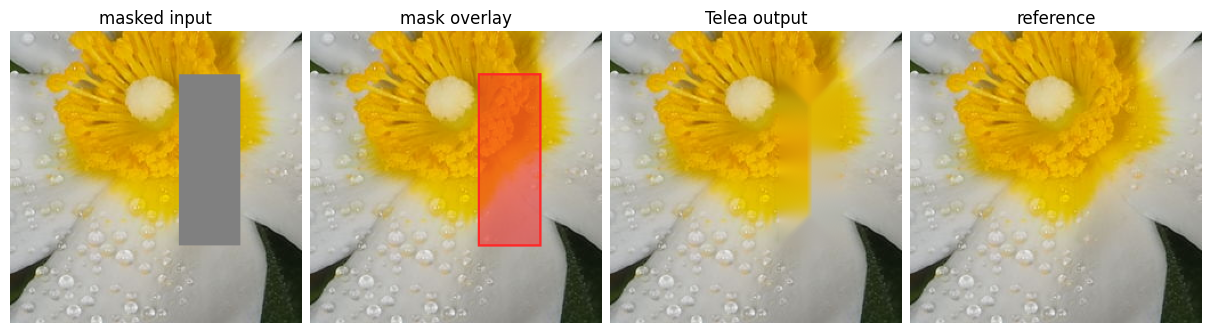

In [17]:
# Call the shared interface with the Telea baseline and score the result.
import importlib

import src.evaluation.inpaint_metrics as metrics_module
import src.inference.baselines as baselines_module
import src.inference.factory as factory_module
import src.inference.interface as interface_module
import src.inference.sd_inpaint as sd_module

for module in (metrics_module, interface_module, baselines_module, sd_module, factory_module):
    importlib.reload(module)  # pick up edits when cells are rerun

from src.evaluation.inpaint_metrics import LPIPSMetric, RESULT_FIELDS, inpaint_metrics, result_rows
from src.inference.baselines import OpenCVInpaint, register_baselines
from src.inference.interface import TASKS, Registry, free_gpu_memory, restore, set_default_registry

check_registry = Registry()
register_baselines(check_registry)
set_default_registry(check_registry)

row = inpaint_manifests["val"][0]
target = read_rgb(PREPARED_DIR / row["target_path"])
mask = load_mask_png(PREPARED_DIR / row["mask_path"])
result = restore(PREPARED_DIR / row["input_path"], "inpainting", PREPARED_DIR / row["mask_path"], seed=SEED,
                 method="opencv_telea")
output = np.asarray(result.image)
print(json.dumps(result.metadata(), indent=1))
print("Visible pixels identical to the reference:", np.array_equal(output[mask == 0], target[mask == 0]))
print({k: round(v, 4) for k, v in inpaint_metrics(output, target, mask).items()})

fig, axes = plt.subplots(1, 4, figsize=(12, 3.3), layout="constrained")
for ax, img, title in zip(axes, (read_rgb(PREPARED_DIR / row["input_path"]), overlay(target, mask), output, target),
                          ("masked input", "mask overlay", "Telea output", "reference")):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
plt.show()

## 6 · Select the inpainting model (C1)

**Candidates considered.** The model has to be a pretrained generative inpainting model on Hugging Face with downloadable weights, a workable fine-tuning path and a fit for 16 GB GPUs (Colab T4, my RTX 4080).

| Model | Decision | Reason |
|---|---|---|
| `stable-diffusion-v1-5/stable-diffusion-inpainting` | **candidate** | Latent diffusion with a dedicated 9-channel inpainting UNet (noisy latents + mask + masked-image latents); trained at 512 px with synthetic masks; first-class `diffusers` support, LoRA training and loading; fp16 weights about 2 GB; CreativeML OpenRAIL-M licence |
| `stabilityai/stable-diffusion-2-inpainting` | not used | The official repository is no longer available on Hugging Face (Stability AI deprecated SD 2.x); only unofficial mirrors remain |
| `diffusers/stable-diffusion-xl-1.0-inpainting-0.1` | not used | 1024 px model with a UNet about three times larger; fine-tuning would not fit comfortably in 16 GB |
| `kandinsky-community/kandinsky-2-2-decoder-inpaint` | not used | Needs a separate prior model and has less training tooling |
| LaMa (big-lama) | possible extra baseline | Strong non-diffusion inpainter, but only community mirrors and TorchScript exports are on Hugging Face |
| OpenCV Telea / Navier–Stokes | baselines | Required simple baselines (team README section 7) |

**What this section measures.** Zero-shot quality of SD 1.5 inpainting under three inference settings, against the two classical fills, on `N_SELECT` fixed validation crops with seed 42. The crops are stratified: half rectangle and half free-form masks, each spread evenly over 5–20% coverage, so neither mask family dominates the averages. The settings compared are working resolution 512 vs 256, and a short plant prompt with guidance 5 vs an empty prompt without guidance. One pipeline is loaded and shared by the three settings. The setting with the best perceptual score (lowest missing-region LPIPS) becomes the inference setting for fine-tuning and the app; the test split is not used.

### 6.1 Run the comparison

Expect about 25 minutes on a T4 for all 166 validation crops (about 5 minutes with `N_SELECT = 32`).

In [18]:
# Run the classical baselines and three SD 1.5 inpainting settings on fixed validation crops.
from src.inference.sd_inpaint import (DEFAULT_NEGATIVE, DEFAULT_PROMPT, StableDiffusionInpaint, load_inpaint_pipeline,
                                      snapshot_revision)

def stratified_subset(rows, n):
    """Equal numbers of each mask type, spread evenly over the coverage range within each type."""
    picked = []
    for mask_type in MASK_TYPES:
        group = sorted((r for r in rows if r["mask_type"] == mask_type), key=lambda r: float(r["mask_coverage"]))
        take = min(n // len(MASK_TYPES), len(group))
        picked += [group[i] for i in np.linspace(0, len(group) - 1, take).round().astype(int)]
    return sorted(picked, key=lambda r: r["sample_id"])


select_rows = (stratified_subset(inpaint_manifests["val"], N_SELECT) if N_SELECT
               else sorted(inpaint_manifests["val"], key=lambda r: r["sample_id"]))
cases = [{"row": r, "input": read_rgb(PREPARED_DIR / r["input_path"]), "target": read_rgb(PREPARED_DIR / r["target_path"]),
          "mask": load_mask_png(PREPARED_DIR / r["mask_path"])} for r in select_rows]
print(f"{len(cases)} validation crops · types {pd.Series([r['mask_type'] for r in select_rows]).value_counts().to_dict()} · "
      f"bins {pd.Series([r['coverage_bin'] for r in select_rows]).value_counts().sort_index().to_dict()} · "
      f"coverage {min(float(r['mask_coverage']) for r in select_rows):.1%}–{max(float(r['mask_coverage']) for r in select_rows):.1%}")

try:
    lpips_fn = LPIPSMetric()
except Exception as exc:  # LPIPS needs AlexNet weights from download.pytorch.org
    lpips_fn = None
    print(f"LPIPS unavailable ({exc}); continuing without it.")

start = time.perf_counter()
sd_pipe = load_inpaint_pipeline(MODEL_ID)
BASE_REVISION = snapshot_revision(sd_pipe)
print(f"Loaded {MODEL_ID} (revision {BASE_REVISION}) in {time.perf_counter() - start:.0f}s on {sd_pipe.device}")

SD_CANDIDATES = {
    f"sd15_{WORK_RES}_prompt": dict(work_res=WORK_RES, prompt=DEFAULT_PROMPT, negative_prompt=DEFAULT_NEGATIVE, guidance=5.0),
    f"sd15_{WORK_RES}_noprompt": dict(work_res=WORK_RES, prompt="", negative_prompt="", guidance=1.0),
    "sd15_256_prompt": dict(work_res=256, prompt=DEFAULT_PROMPT, negative_prompt=DEFAULT_NEGATIVE, guidance=5.0),
}
selection = Registry(max_gpu_models=len(SD_CANDIDATES))
selection.register(OpenCVInpaint("telea"))
selection.register(OpenCVInpaint("ns"))
for name, settings in SD_CANDIDATES.items():
    selection.register(StableDiffusionInpaint(name, model_id=MODEL_ID, pipe=sd_pipe, steps=SD_STEPS, label=name, **settings))
METHODS = ["opencv_telea", "opencv_ns", *SD_CANDIDATES]

selection_rows, selection_outputs, peak_memory = [], {}, {}
for method in METHODS:
    handler = selection.handler("inpainting", method)
    if handler.uses_gpu:  # untimed warm-up, then measure peak memory for this setting
        handler.run(Image.fromarray(cases[0]["input"]), cases[0]["mask"], SEED)
        if DEVICE == "cuda":
            torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    selection_outputs[method] = []
    for case in cases:
        res = selection.restore(case["input"], "inpainting", case["mask"], seed=SEED, method=method)
        scores = inpaint_metrics(np.asarray(res.image), case["target"], case["mask"], lpips_fn) if res.success else None
        selection_outputs[method].append(np.asarray(res.image) if res.success else None)
        selection_rows += result_rows(case["row"]["sample_id"], method, scores, checkpoint_revision=handler.version,
                                      seed=SEED, inference_seconds=res.elapsed_seconds,
                                      status="ok" if res.success else "error", error_note=res.error or "")
    if handler.uses_gpu and DEVICE == "cuda":
        peak_memory[method] = round(torch.cuda.max_memory_allocated() / 1024**3, 2)
    print(f"{method:24s} {time.perf_counter() - start:6.1f}s for {len(cases)} crops")

selection_df = pd.DataFrame(selection_rows, columns=RESULT_FIELDS)
selection_df.to_csv(OUTPUT_DIR / "model_selection_val.csv", index=False)
print(f"Saved {len(selection_df)} result rows to {OUTPUT_DIR / 'model_selection_val.csv'}")

166 validation crops · types {'rectangle': 83, 'freeform': 83} · bins {'large_15_20': 55, 'medium_10_15': 59, 'small_5_10': 52} · coverage 5.1%–20.0%


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 149MB/s]


model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loaded stable-diffusion-v1-5/stable-diffusion-inpainting (revision 8a4288a76071) in 27s on cuda:0
opencv_telea                9.9s for 166 crops
opencv_ns                   8.6s for 166 crops
sd15_512_prompt           744.7s for 166 crops
sd15_512_noprompt         480.7s for 166 crops
sd15_256_prompt           274.4s for 166 crops
Saved 7470 result rows to /content/drive/MyDrive/AAI521/Final_project/inpainting_week1/model_selection_val.csv


### 6.2 Results

Mean scores per method over the selection crops, then broken down by mask type and coverage bin. Failures are counted, not dropped. Expect the classical fills to score well on PSNR for small, smooth holes: PSNR rewards a blurry average. LPIPS and the boundary metrics show whether texture and leaf edges continue plausibly, which is what fine-tuning should improve.

No failed calls.


,masked_psnr,masked_ssim,masked_l1,boundary_l1,boundary_grad_l1,masked_bbox_lpips,inference_seconds,peak_gpu_memory_gb
method,,,,,,,,
opencv_telea,20.8266,0.5780,0.0678,0.0183,0.0746,0.1714,0.0251,NaN
opencv_ns,20.8595,0.5799,0.0671,0.0168,0.0712,0.1697,0.0282,NaN
sd15_512_prompt,19.5463,0.5090,0.0831,0.0263,0.0972,0.1262,4.4614,2.62
sd15_512_noprompt,19.5169,0.5004,0.0853,0.0246,0.0945,0.1385,2.8710,2.62
sd15_256_prompt,18.8097,0.4811,0.0888,0.0273,0.0950,0.1363,1.6286,2.18


masked_psnr           masked_bbox_lpips            \
mask_type            freeform rectangle          freeform rectangle   
method                                                                
opencv_telea          22.4342   19.2191            0.0732    0.2695   
opencv_ns             22.5572   19.1618            0.0724    0.2669   
sd15_512_prompt       19.5795   19.5131            0.0979    0.1544   
sd15_512_noprompt     20.2650   18.7688            0.0946    0.1824   
sd15_256_prompt       19.7637   17.8558            0.0793    0.1932   

                  boundary_l1            
mask_type            freeform rectangle  
method                                   
opencv_telea           0.0176    0.0190  
opencv_ns              0.0156    0.0179  
sd15_512_prompt        0.0323    0.0204  
sd15_512_noprompt      0.0281    0.0212  
sd15_256_prompt        0.0282    0.0264

masked_psnr                         masked_bbox_lpips  \
coverage_bin      large_15_20 medium_10_15 small_5_10       large_15_20   
method                                                                    
opencv_telea          20.4966      20.7904    21.2167            0.1795   
opencv_ns             20.5453      20.8199    21.2367            0.1769   
sd15_512_prompt       19.9872      18.6442    20.1035            0.1264   
sd15_512_noprompt     19.2471      18.8884    20.5154            0.1536   
sd15_256_prompt       18.2243      18.5604    19.7118            0.1530   

                                          boundary_l1                          
coverage_bin      medium_10_15 small_5_10 large_15_20 medium_10_15 small_5_10  
method                                                                         
opencv_telea            0.1848     0.1476      0.0185       0.0174     0.0191  
opencv_ns               0.1823     0.1478      0.0168       0.0159     0.0177  
sd15_512_prompt         0.1496     0.0993      0.0247       0.0271     0.0270  
sd15_512_noprompt       0.1595     0.0988      0.0229       0.0258     0.0250  
sd15_256_prompt         0.1421     0.1121      0.0293       0.0258     0.0269

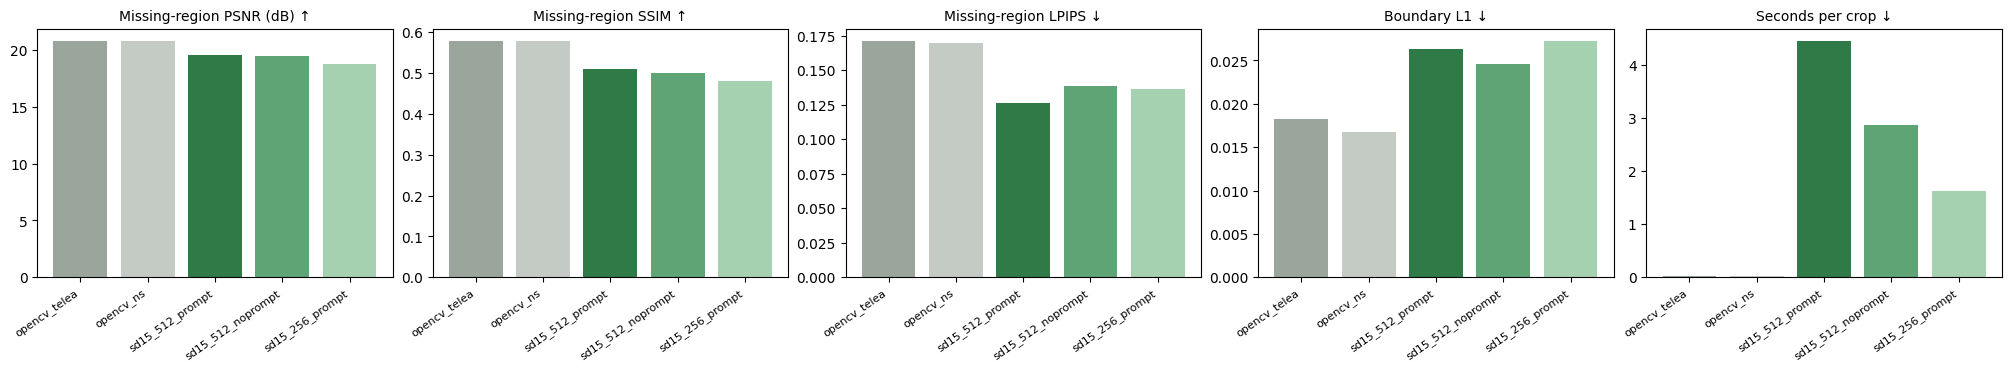

In [19]:
# Summarise the zero-shot comparison and plot the main metrics.
failures = selection_df[selection_df.status != "ok"]
print(f"Failed calls: {failures.sample_id.nunique()} rows" if len(failures) else "No failed calls.")
ok = selection_df[selection_df.status == "ok"].astype({"metric_value": float})
wide = ok.pivot_table(index=["sample_id", "method"], columns="metric_name", values="metric_value").reset_index()
wide = wide.merge(ok.groupby(["sample_id", "method"]).inference_seconds.first().astype(float).reset_index(),
                  on=["sample_id", "method"])
wide = wide.merge(pd.DataFrame([{"sample_id": r["sample_id"], "mask_type": r["mask_type"],
                                 "coverage_bin": r["coverage_bin"]} for r in select_rows]), on="sample_id")
MAIN = [c for c in ("masked_psnr", "masked_ssim", "masked_l1", "boundary_l1", "boundary_grad_l1", "masked_bbox_lpips")
        if c in wide]
selection_summary = wide.groupby("method")[MAIN + ["inference_seconds"]].mean().reindex(METHODS)
selection_summary["peak_gpu_memory_gb"] = pd.Series(peak_memory)
selection_summary.to_csv(OUTPUT_DIR / "model_selection_summary.csv")
display(selection_summary.round(4))
key = [c for c in ("masked_psnr", "masked_bbox_lpips", "boundary_l1") if c in wide]
display(wide.groupby(["mask_type", "method"])[key].mean().unstack(0).reindex(METHODS).round(4))
display(wide.groupby(["coverage_bin", "method"])[key].mean().unstack(0).reindex(METHODS).round(4))

panels = [("masked_psnr", "Missing-region PSNR (dB) ↑"), ("masked_ssim", "Missing-region SSIM ↑"),
          ("masked_bbox_lpips", "Missing-region LPIPS ↓"), ("boundary_l1", "Boundary L1 ↓"),
          ("inference_seconds", "Seconds per crop ↓")]
panels = [p for p in panels if p[0] in selection_summary]
fig, axes = plt.subplots(1, len(panels), figsize=(4 * len(panels), 3.6), layout="constrained")
colors = ["#9aa59c", "#c3cbc4"] + ["#2f7a46", "#5ea474", "#a5d1b0"][:len(SD_CANDIDATES)]
for ax, (col, title) in zip(np.atleast_1d(axes), panels):
    ax.bar(range(len(METHODS)), selection_summary[col], color=colors)
    ax.set_xticks(range(len(METHODS)), METHODS, rotation=35, ha="right", fontsize=8)
    ax.set_title(title, fontsize=10)
plt.show()

### 6.3 Visual comparison

Six selection crops, three per mask type, spread over coverage. Scores cannot show invented structure, so check whether leaf edges, veins and background continue plausibly into the hole.

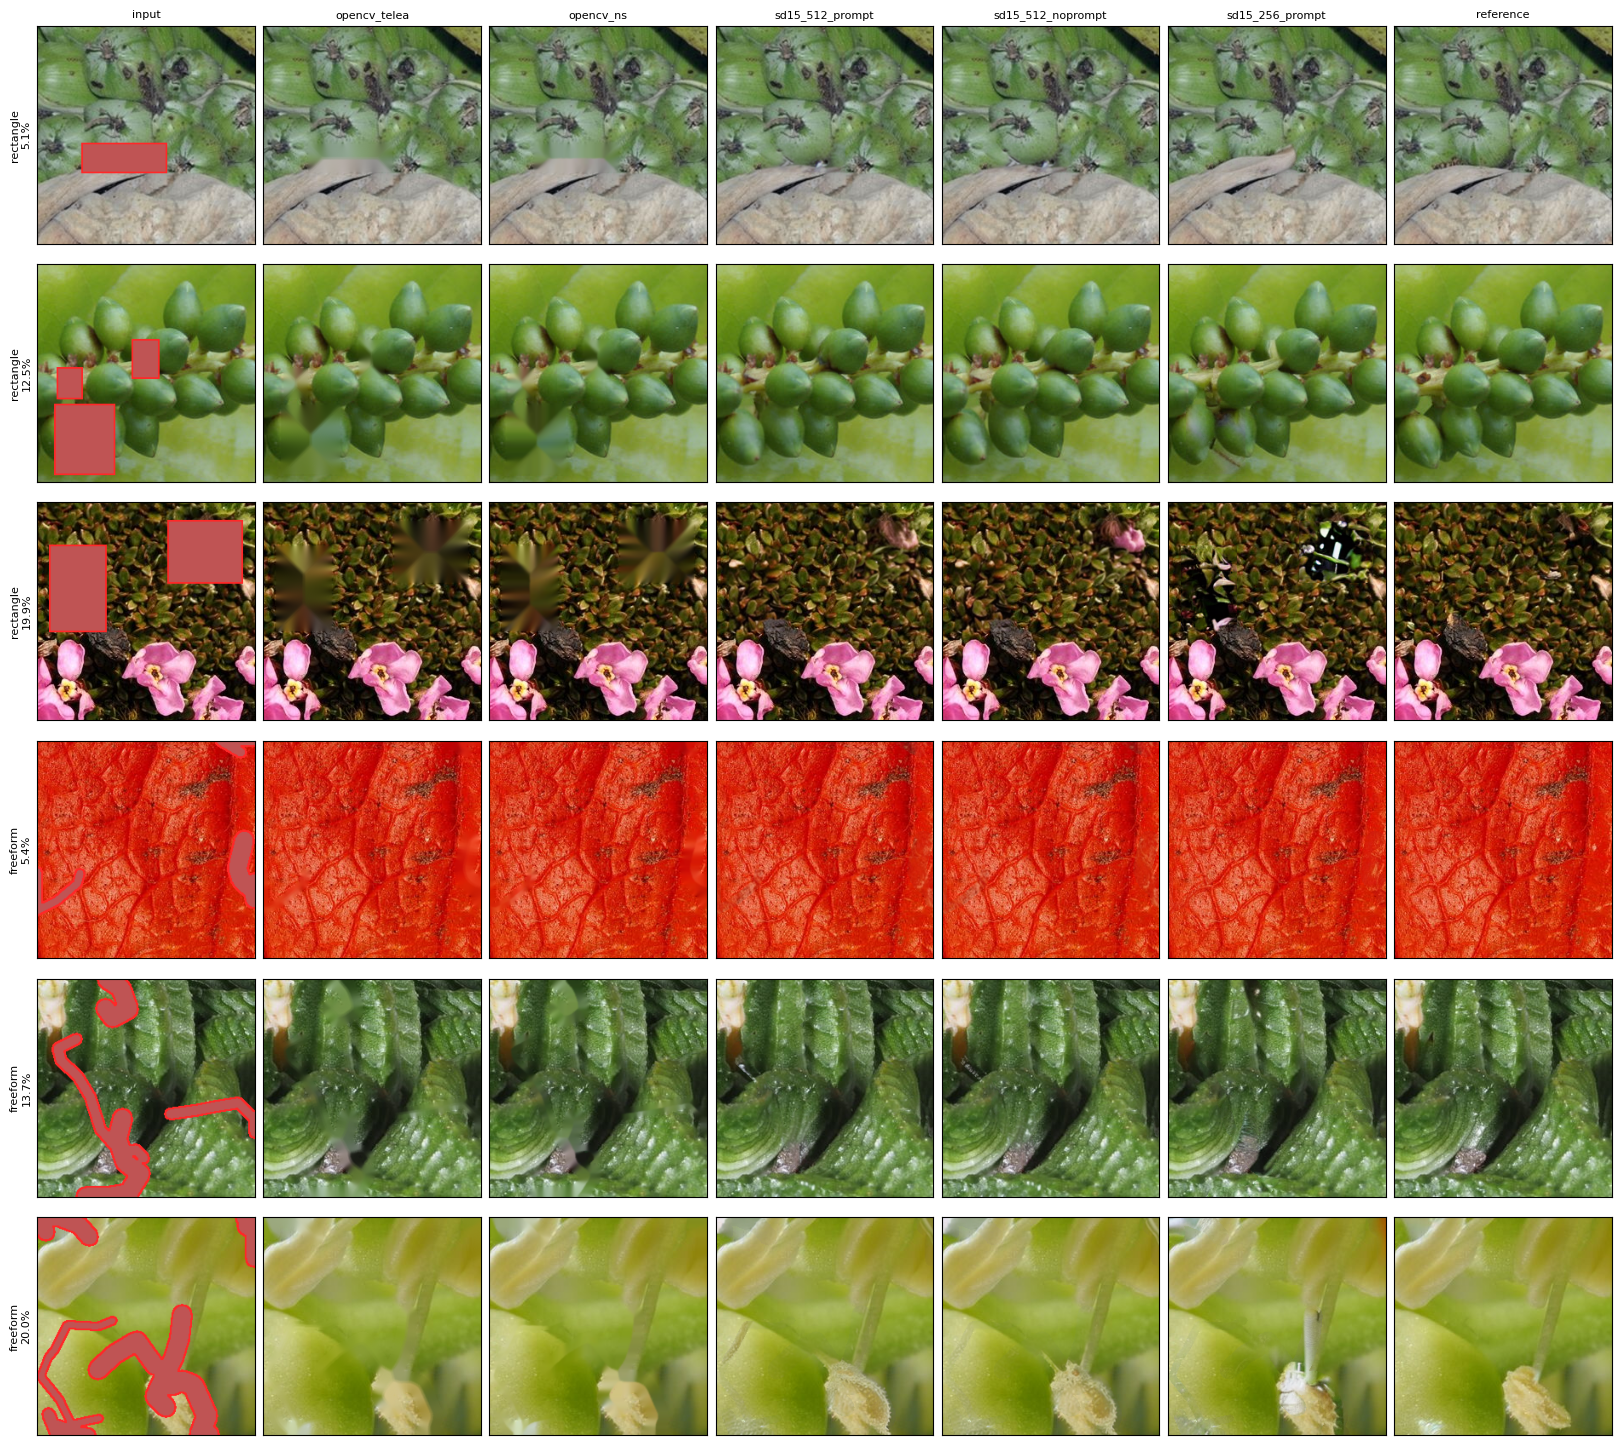

In [20]:
# Side-by-side outputs for six validation crops.
show = []  # three crops of each mask type, spread over coverage
for mask_type in MASK_TYPES:
    idx = sorted((i for i, c in enumerate(cases) if c["row"]["mask_type"] == mask_type),
                 key=lambda i: float(cases[i]["row"]["mask_coverage"]))
    show += [idx[k] for k in np.linspace(0, len(idx) - 1, min(3, len(idx))).round().astype(int)]
columns = ["input"] + METHODS + ["reference"]
fig, axes = plt.subplots(len(show), len(columns), figsize=(2.3 * len(columns), 2.4 * len(show)),
                         layout="constrained", squeeze=False)
for r, i in enumerate(show):
    case = cases[i]
    images = [overlay(case["input"], case["mask"])] + [selection_outputs[m][i] for m in METHODS] + [case["target"]]
    for c, (img, name) in enumerate(zip(images, columns)):
        ax = axes[r, c]
        if img is not None:
            ax.imshow(img)
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(name, fontsize=8)
    axes[r, 0].set_ylabel(f"{case['row']['mask_type']}\n{float(case['row']['mask_coverage']):.1%}", fontsize=8)
plt.show()

### 6.4 Record the selection

The SD setting with the lowest missing-region LPIPS is chosen automatically (SSIM is used if LPIPS is unavailable). To overrule it after looking at the images, set `SELECTED_CONFIG` to one of the setting names and rerun this cell. The cell writes:

- `configs/inpainting.json`: selected model, revision and inference settings, used by training and evaluation;
- `configs/app.json`: the app's model settings;
- `docs/inpainting_model_selection.md`: the decision, candidates and results table for the report.

Then it releases the selection pipeline from GPU memory.

In [21]:
# Choose the inference setting, then write the configs and the selection note.
from datetime import datetime, timezone

SELECTED_CONFIG = None  # e.g. "sd15_512_prompt" to overrule the automatic choice

rank_metric = "masked_bbox_lpips" if "masked_bbox_lpips" in selection_summary else "masked_ssim"
ranked = selection_summary.loc[list(SD_CANDIDATES), rank_metric].sort_values(ascending=rank_metric.endswith("lpips"))
selected_name = SELECTED_CONFIG or ranked.index[0]
chosen = SD_CANDIDATES[selected_name]
INFER = {"model_id": MODEL_ID, "revision": BASE_REVISION, "work_res": chosen["work_res"], "prompt": chosen["prompt"],
         "negative_prompt": chosen["negative_prompt"], "steps": SD_STEPS, "guidance": chosen["guidance"],
         "scheduler": "DPMSolverMultistep", "seed": SEED}
print(f"Selected setting: {selected_name} (ranked by {rank_metric})")
print(json.dumps(INFER, indent=1))

(CODE_DIR / "configs" / "inpainting.json").write_text(json.dumps({
    "task": "inpainting", "selected_setting": selected_name, "inference": INFER,
    "baseline": "opencv_telea", "masks": {"version": "inpainting_v1", "coverage": [0.05, 0.20], "seed": SEED},
    "selection": {"split": "val", "crops": len(cases), "rank_metric": rank_metric},
}, indent=2) + "\n", encoding="utf-8")
app_config = {"max_gpu_models": 1, "inpainting": {
    "enable_pretrained": True, **{k: INFER[k] for k in ("model_id", "work_res", "prompt", "negative_prompt", "steps", "guidance")},
    "lora_path": "", "lora_label": "", "default_method": ""}}
(CODE_DIR / "configs" / "app.json").write_text(json.dumps(app_config, indent=2) + "\n", encoding="utf-8")


def markdown_table(df, digits=4):
    head = "| " + " | ".join([df.index.name or "method", *map(str, df.columns)]) + " |"
    lines = [head, "|" + "---|" * (len(df.columns) + 1)]
    for index, values in df.iterrows():
        cells = [f"{v:.{digits}f}" if isinstance(v, (float, np.floating)) and np.isfinite(v) else str(v) for v in values]
        lines.append("| " + " | ".join([str(index), *cells]) + " |")
    return "\n".join(lines)


telea = selection_summary.loc["opencv_telea"]
best = selection_summary.loc[selected_name]
comparison = []
for col, higher in (("masked_psnr", True), ("masked_ssim", True), ("masked_bbox_lpips", False), ("boundary_l1", False)):
    if col in selection_summary:
        better = best[col] > telea[col] if higher else best[col] < telea[col]
        comparison.append(f"- `{col}`: {best[col]:.4f} vs Telea {telea[col]:.4f} ({'better' if better else 'worse'})")
note = f"""# Inpainting model selection (Week 1)

Generated by `notebooks/PlantSR_Inpainting_Week1.ipynb` on {datetime.now(timezone.utc):%Y-%m-%d %H:%M} UTC.

## Decision

- Fine-tune **`{MODEL_ID}`** (revision `{BASE_REVISION}`) with LoRA adapters on the UNet attention layers.
- Baseline: OpenCV Telea (radius 5). OpenCV Navier-Stokes is reported as a second classical fill.
- Inference setting selected on validation (`{selected_name}`): working resolution {INFER['work_res']} px,
  prompt "{INFER['prompt']}", guidance {INFER['guidance']}, {SD_STEPS} DPM-Solver++ steps, seed {SEED},
  composite `final = (1 - mask) * input + mask * generated`.

## Candidates

| Model | Decision | Reason |
|---|---|---|
| stable-diffusion-v1-5/stable-diffusion-inpainting | selected | 9-channel inpainting UNet; diffusers + LoRA support; fits 16 GB GPUs; CreativeML OpenRAIL-M |
| stabilityai/stable-diffusion-2-inpainting | not used | official repository no longer available on Hugging Face (SD 2.x deprecated); only unofficial mirrors |
| diffusers/stable-diffusion-xl-1.0-inpainting-0.1 | not used | 1024 px, ~3x larger UNet; fine-tuning does not fit comfortably in 16 GB |
| kandinsky-community/kandinsky-2-2-decoder-inpaint | not used | needs a separate prior; less training tooling |
| LaMa (big-lama) | optional extra baseline | community mirrors / TorchScript only |

## Zero-shot results on {len(cases)} validation crops (fixed masks v1, seed {SEED})

{markdown_table(selection_summary)}

Selected setting vs Telea:
{chr(10).join(comparison)}

Missing-region metrics only; full-image scores are inflated by copied pixels. LPIPS is computed on the padded
bounding box of the missing region. Per-crop rows: `model_selection_val.csv`.
"""
(CODE_DIR / "docs" / "inpainting_model_selection.md").write_text(note, encoding="utf-8")
print(note.split("## Zero-shot")[0])

del selection, sd_pipe, handler
free_gpu_memory()

Selected setting: sd15_512_prompt (ranked by masked_bbox_lpips)
{
 "model_id": "stable-diffusion-v1-5/stable-diffusion-inpainting",
 "revision": "8a4288a76071",
 "work_res": 512,
 "prompt": "a high-resolution photo of a plant, natural leaves, sharp focus",
 "negative_prompt": "blurry, text, watermark, frame, border, cartoon, painting",
 "steps": 25,
 "guidance": 5.0,
 "scheduler": "DPMSolverMultistep",
 "seed": 42
}
# Inpainting model selection (Week 1)

Generated by `notebooks/PlantSR_Inpainting_Week1.ipynb` on 2026-11-16 04:17 UTC.

## Decision

- Fine-tune **`stable-diffusion-v1-5/stable-diffusion-inpainting`** (revision `8a4288a76071`) with LoRA adapters on the UNet attention layers.
- Baseline: OpenCV Telea (radius 5). OpenCV Navier-Stokes is reported as a second classical fill.
- Inference setting selected on validation (`sd15_512_prompt`): working resolution 512 px,
  prompt "a high-resolution photo of a plant, natural leaves, sharp focus", guidance 5.0, 25 DPM-Solver++ steps, s

## 7 · Short LoRA fine-tuning trial and checkpoint reload (shared Week 1 task)

This is the plan's training-path check, not the real fine-tuning: run `TRIAL_STEPS` steps, confirm finite losses and parameter updates, record GPU memory and speed, save the adapter, and reload it **in a separate Python process**.

**Training sample.** A random 256 × 256 crop from a full-size *training* image, a random horizontal flip, then a random mask (5–20%, rectangle or free-form) drawn after the geometry. Image and mask are resized to the working resolution (bicubic image, nearest-neighbour mask), exactly as at inference.

**Objective.** The standard inpainting diffusion loss: encode the clean crop and the masked crop with the frozen VAE, add noise at a random timestep, and train the UNet on `[noisy latents, mask, masked-image latents]` to predict the noise (MSE). Only LoRA adapters on the UNet attention projections are trained (rank 8, learning rate 1e-4, batch size 1, AdamW, gradient clipping 1.0). The frozen weights stay in fp16; the adapters train in fp32 with mixed precision and gradient checkpointing.

In [22]:
%%writefile "{CODE_DIR}/src/train/inpaint_lora.py"
"""LoRA fine-tuning of Stable Diffusion 1.5 inpainting on PlantSR crops.

Week 1 uses `train_lora_trial` for a short 50-100 step run that checks the training path:
finite losses, parameter updates, GPU memory/speed, saving, and reloading in a new process.
The same loop is the starting point for the full Week 2 fine-tuning.

Training sample: random 256 x 256 crop of a full-size training image -> random horizontal
flip -> random mask (5-20%, rectangle or free-form) drawn *after* the geometry, so image
and mask are aligned by construction -> both resized to the working resolution
(bicubic image, nearest mask). Loss: standard epsilon-prediction MSE on the 9-channel UNet.

Fresh-process reload check (run by the notebook):
    python -m src.train.inpaint_lora reload-check --lora DIR --cases cases.json --out out.npz
"""
from __future__ import annotations

import argparse
import itertools
import json
import platform
import time
from dataclasses import asdict, dataclass, field
from pathlib import Path

import numpy as np
from PIL import Image

from src.data.inpaint_masks import TrainingMaskSampler, load_mask_png
from src.inference.sd_inpaint import (DEFAULT_MODEL_ID, DEFAULT_NEGATIVE, DEFAULT_PROMPT, StableDiffusionInpaint,
                                      load_inpaint_pipeline, lora_file)


@dataclass
class LoraTrialConfig:
    model_id: str = DEFAULT_MODEL_ID
    steps: int = 100
    learning_rate: float = 1e-4
    rank: int = 8
    alpha: int = 8  # alpha == rank -> LoRA scale 1.0
    batch_size: int = 1
    crop_size: int = 256
    work_res: int = 512
    prompt: str = DEFAULT_PROMPT
    seed: int = 42
    gradient_checkpointing: bool = True
    max_grad_norm: float = 1.0
    target_modules: tuple = ("to_q", "to_k", "to_v", "to_out.0")
    log_every: int = 10


@dataclass
class TrialResult:
    losses: list = field(default_factory=list)
    grad_norms: list = field(default_factory=list)
    step_seconds: list = field(default_factory=list)
    trainable_parameters: int = 0
    trainable_tensors: int = 0
    changed_tensors: int = 0
    max_abs_update: float = 0.0
    only_lora_trainable: bool = False
    peak_gpu_memory_gb: float | None = None
    amp_dtype: str = "float32"
    samples: list = field(default_factory=list)

    @property
    def all_finite(self) -> bool:
        return bool(self.losses) and bool(np.all(np.isfinite(self.losses)))

    def summary(self) -> dict:
        losses = np.asarray(self.losses, dtype=float)
        times = np.asarray(self.step_seconds[1:] or self.step_seconds, dtype=float)
        first = losses[: max(1, len(losses) // 5)].mean() if len(losses) else float("nan")
        last = losses[-max(1, len(losses) // 5):].mean() if len(losses) else float("nan")
        return {
            "steps": len(self.losses), "all_losses_finite": self.all_finite,
            "loss_first_20pct_mean": float(first), "loss_last_20pct_mean": float(last),
            "trainable_parameters": self.trainable_parameters, "trainable_tensors": self.trainable_tensors,
            "changed_tensors": self.changed_tensors, "max_abs_update": self.max_abs_update,
            "only_lora_trainable": self.only_lora_trainable,
            "median_step_seconds": float(np.median(times)) if len(times) else None,
            "peak_gpu_memory_gb": self.peak_gpu_memory_gb, "amp_dtype": self.amp_dtype,
        }


class TrainCropDataset:
    """Random crops + flips + masks from the full-size training images (map-style dataset)."""

    def __init__(self, prepared_dir, rows, crop_size: int = 256, work_res: int = 512, seed: int = 42):
        self.prepared_dir = Path(prepared_dir)
        self.rows = [r for r in rows if r.get("hr_path")]
        if not self.rows:
            raise ValueError("No training rows with hr_path were provided.")
        self.crop_size, self.work_res = crop_size, work_res
        self.rng = np.random.default_rng(seed)
        self.masks = TrainingMaskSampler(seed + 1)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        import torch

        row = self.rows[index]
        with Image.open(self.prepared_dir / row["hr_path"]) as src:
            image = src.convert("RGB")
        c = self.crop_size
        if min(image.size) < c:
            raise ValueError(f"{row['sample_id']} is smaller than the crop size")
        x = int(self.rng.integers(0, image.width - c + 1))
        y = int(self.rng.integers(0, image.height - c + 1))
        crop = image.crop((x, y, x + c, y + c))
        flip = bool(self.rng.random() < 0.5)
        if flip:
            crop = crop.transpose(Image.FLIP_LEFT_RIGHT)
        mask, params = self.masks(c, c)  # drawn after crop/flip -> always aligned
        work = self.work_res
        crop_w = crop.resize((work, work), Image.BICUBIC) if work != c else crop
        mask_w = Image.fromarray(mask * 255).resize((work, work), Image.NEAREST) if work != c else Image.fromarray(mask * 255)
        pixel = torch.from_numpy(np.asarray(crop_w, dtype=np.float32) / 127.5 - 1.0).permute(2, 0, 1)
        mask_t = torch.from_numpy((np.asarray(mask_w) > 127).astype(np.float32))[None]
        return {"pixel_values": pixel, "mask": mask_t, "sample_id": row["sample_id"], "crop_x": x, "crop_y": y,
                "flip": flip, "mask_type": params["mask_type"], "coverage": params["coverage"]}


def _collate(items):
    import torch

    batch = {"pixel_values": torch.stack([i["pixel_values"] for i in items]),
             "mask": torch.stack([i["mask"] for i in items])}
    batch["meta"] = [{k: v for k, v in i.items() if k not in ("pixel_values", "mask")} for i in items]
    return batch


def add_lora(unet, cfg: LoraTrialConfig):
    import torch
    from diffusers.training_utils import cast_training_params
    from peft import LoraConfig

    unet.requires_grad_(False)
    unet.add_adapter(LoraConfig(r=cfg.rank, lora_alpha=cfg.alpha, init_lora_weights="gaussian",
                                target_modules=list(cfg.target_modules)))
    if unet.dtype != torch.float32:
        cast_training_params(unet, dtype=torch.float32)  # train adapters in fp32, base stays fp16
    return [p for p in unet.parameters() if p.requires_grad]


def train_lora_trial(pipe, dataset: TrainCropDataset, cfg: LoraTrialConfig, progress=print) -> TrialResult:
    import torch
    import torch.nn.functional as F
    from diffusers import DDPMScheduler

    device = pipe.unet.device
    torch.manual_seed(cfg.seed)
    unet, vae = pipe.unet, pipe.vae
    vae.requires_grad_(False)
    pipe.text_encoder.requires_grad_(False)
    params = add_lora(unet, cfg)
    names = [n for n, p in unet.named_parameters() if p.requires_grad]
    before = {n: p.detach().clone() for n, p in unet.named_parameters() if p.requires_grad}
    optimizer = torch.optim.AdamW(params, lr=cfg.learning_rate, weight_decay=1e-2)
    noise_scheduler = DDPMScheduler.from_config(pipe.scheduler.config)
    prediction_type = noise_scheduler.config.prediction_type
    with torch.no_grad():
        prompt_embeds, _ = pipe.encode_prompt(cfg.prompt, device, 1, False)

    use_amp = device.type == "cuda"
    amp_dtype = torch.float32
    if use_amp:
        amp_dtype = torch.bfloat16 if torch.cuda.get_device_capability(device)[0] >= 8 else torch.float16
        torch.cuda.reset_peak_memory_stats(device)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp and amp_dtype == torch.float16)
    if cfg.gradient_checkpointing:
        unet.enable_gradient_checkpointing()
    unet.train()

    generator = torch.Generator().manual_seed(cfg.seed)
    loader = torch.utils.data.DataLoader(dataset, batch_size=cfg.batch_size, shuffle=True, num_workers=0,
                                         collate_fn=_collate, generator=generator, drop_last=True)
    batches = itertools.cycle(loader)
    sf = vae.config.scaling_factor
    result = TrialResult(trainable_parameters=sum(p.numel() for p in params), trainable_tensors=len(params),
                         amp_dtype=str(amp_dtype).replace("torch.", ""),
                         only_lora_trainable=bool(names) and all("lora" in n for n in names))
    for step in range(1, cfg.steps + 1):
        start = time.perf_counter()
        batch = next(batches)
        pixel = batch["pixel_values"].to(device, dtype=vae.dtype)
        mask = batch["mask"].to(device, dtype=vae.dtype)
        masked = pixel * (mask < 0.5)  # same masking as the pipeline: missing pixels -> 0 (grey)
        with torch.no_grad():
            latents = vae.encode(pixel).latent_dist.sample() * sf
            masked_latents = vae.encode(masked).latent_dist.sample() * sf
        mask_latent = F.interpolate(mask, size=latents.shape[-2:])
        noise = torch.randn_like(latents)
        timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps, (latents.shape[0],),
                                  device=device).long()
        noisy = noise_scheduler.add_noise(latents, noise, timesteps)
        model_input = torch.cat([noisy, mask_latent, masked_latents], dim=1)
        target = noise if prediction_type == "epsilon" else noise_scheduler.get_velocity(latents, noise, timesteps)
        with torch.autocast(device.type, dtype=amp_dtype, enabled=use_amp):
            pred = unet(model_input, timesteps,
                        encoder_hidden_states=prompt_embeds.expand(latents.shape[0], -1, -1)).sample
        loss = F.mse_loss(pred.float(), target.float())
        if not torch.isfinite(loss):
            result.losses.append(float("nan"))
            raise FloatingPointError(f"Non-finite loss at step {step}; lower the learning rate.")
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        grad_norm = torch.nn.utils.clip_grad_norm_(params, cfg.max_grad_norm)
        scaler.step(optimizer)
        scaler.update()
        if use_amp:
            torch.cuda.synchronize(device)
        result.losses.append(float(loss.detach()))
        result.grad_norms.append(float(grad_norm))
        result.step_seconds.append(time.perf_counter() - start)
        if step <= 3:
            result.samples.extend(batch["meta"])
        if progress and (step % cfg.log_every == 0 or step == 1):
            progress(f"step {step:4d}/{cfg.steps}  loss {result.losses[-1]:.4f}  "
                     f"grad-norm {result.grad_norms[-1]:.3f}  {result.step_seconds[-1]:.2f}s/step")
    unet.eval()
    if cfg.gradient_checkpointing:
        unet.disable_gradient_checkpointing()
    after = dict(unet.named_parameters())
    deltas = [float((after[n].detach() - before[n]).abs().max()) for n in names]
    result.changed_tensors = int(sum(d > 0 for d in deltas))
    result.max_abs_update = max(deltas) if deltas else 0.0
    if use_amp:
        result.peak_gpu_memory_gb = round(torch.cuda.max_memory_allocated(device) / 1024 ** 3, 2)
    del optimizer
    return result


def prepare_for_inference(unet, dtype) -> None:
    """Freeze the adapters and cast them to the pipeline dtype (as a fresh reload would)."""
    from diffusers.training_utils import cast_training_params

    cast_training_params(unet, dtype=dtype)
    unet.requires_grad_(False)
    unet.eval()


def lora_state_dict(unet, adapter_name: str = "default") -> dict:
    from diffusers.utils import convert_state_dict_to_diffusers
    from peft.utils import get_peft_model_state_dict

    return convert_state_dict_to_diffusers(get_peft_model_state_dict(unet, adapter_name=adapter_name))


def save_lora(unet, out_dir, cfg: LoraTrialConfig, extra: dict | None = None, adapter_name: str = "default") -> Path:
    from diffusers import StableDiffusionInpaintPipeline

    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    layers = lora_state_dict(unet, adapter_name)
    try:  # newer diffusers also store the LoRA config (rank/alpha) inside the file
        StableDiffusionInpaintPipeline.save_lora_weights(
            out_dir, unet_lora_layers=layers, safe_serialization=True,
            unet_lora_adapter_metadata=unet.peft_config[adapter_name].to_dict())
    except TypeError:
        StableDiffusionInpaintPipeline.save_lora_weights(out_dir, unet_lora_layers=layers, safe_serialization=True)
    record = {"config": asdict(cfg), "environment": environment(), **(extra or {})}
    (out_dir / "trial_config.json").write_text(json.dumps(record, indent=2, default=str), encoding="utf-8")
    return lora_file(out_dir)


def compare_adapter_to_file(unet, lora_dir, adapter_name: str) -> dict:
    """Compare LoRA tensors held by `unet` with the saved safetensors file."""
    from safetensors.torch import load_file

    saved = {k.removeprefix("unet."): v for k, v in load_file(str(lora_file(lora_dir))).items()}
    live = {k.removeprefix("unet."): v.detach().float().cpu() for k, v in lora_state_dict(unet, adapter_name).items()}
    shared = sorted(set(saved) & set(live))
    max_diff = max((float((saved[k].float() - live[k]).abs().max()) for k in shared), default=float("nan"))
    return {"saved_tensors": len(saved), "loaded_tensors": len(live), "matching_keys": len(shared),
            "missing_in_model": len(set(saved) - set(live)), "max_abs_diff": max_diff}


def environment() -> dict:
    import importlib.metadata as md

    info = {"python": platform.python_version()}
    for name in ("torch", "diffusers", "transformers", "peft", "accelerate", "numpy", "Pillow"):
        try:
            info[name] = md.version(name)
        except md.PackageNotFoundError:
            info[name] = None
    try:
        import torch

        info["cuda_device"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
    except ImportError:
        pass
    return info


def run_cases(handler: StableDiffusionInpaint, prepared_dir, cases) -> np.ndarray:
    """Generate raw (pre-composite) outputs for a list of {input_path, mask_path, seed} cases."""
    outputs = []
    for case in cases:
        with Image.open(Path(prepared_dir) / case["input_path"]) as src:
            image = src.convert("RGB")
        mask = load_mask_png(Path(prepared_dir) / case["mask_path"])
        outputs.append(np.asarray(handler.generate(image, mask, int(case["seed"]))))
    return np.stack(outputs)


def _reload_check(args) -> None:
    record = json.loads((Path(args.lora) / "trial_config.json").read_text(encoding="utf-8"))
    cfg = record["config"]
    infer = record.get("inference", {})
    start = time.perf_counter()
    pipe = load_inpaint_pipeline(cfg["model_id"])
    pipe.load_lora_weights(args.lora, adapter_name="plantsr")
    load_seconds = time.perf_counter() - start
    tensors = compare_adapter_to_file(pipe.unet, args.lora, "plantsr")
    handler = StableDiffusionInpaint("reload_check", model_id=cfg["model_id"], lora_path=args.lora, pipe=pipe,
                                     work_res=infer.get("work_res", cfg["work_res"]),
                                     prompt=infer.get("prompt", cfg["prompt"]),
                                     negative_prompt=infer.get("negative_prompt", DEFAULT_NEGATIVE),
                                     steps=infer.get("steps", 25), guidance=infer.get("guidance", 5.0))
    cases = json.loads(Path(args.cases).read_text(encoding="utf-8"))
    outputs = run_cases(handler, args.prepared_dir, cases)
    np.savez_compressed(args.out, outputs=outputs)
    report = {"load_seconds": round(load_seconds, 2), "adapter_tensors": tensors,
              "model_version": handler.version, "cases": len(cases)}
    Path(args.out).with_suffix(".json").write_text(json.dumps(report, indent=2), encoding="utf-8")
    print(json.dumps(report, indent=2))


def main(argv=None) -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    sub = parser.add_subparsers(dest="command", required=True)
    check = sub.add_parser("reload-check", help="Reload a saved LoRA in a fresh process and run fixed cases")
    check.add_argument("--lora", required=True)
    check.add_argument("--cases", required=True)
    check.add_argument("--prepared-dir", required=True)
    check.add_argument("--out", required=True)
    args = parser.parse_args(argv)
    if args.command == "reload-check":
        _reload_check(args)


if __name__ == "__main__":
    main()

Writing /content/AAI521-Group1-PlantSR-Restoration/src/train/inpaint_lora.py


### 7.1 Check training samples

Before training, draw a few samples from the training dataset and confirm that the mask and image tensors share the same size and that the mask is binary. The red overlay should sit on top of the crop it was drawn for.

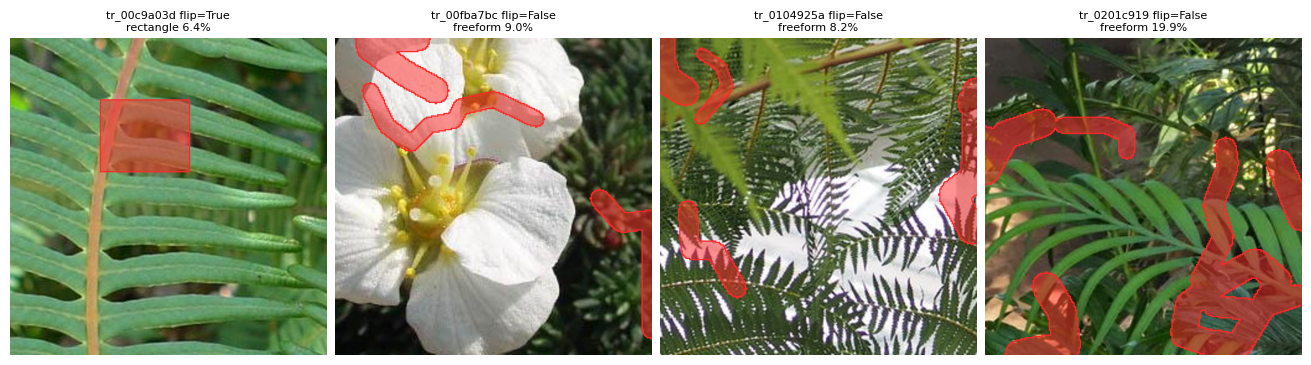

Training images: 663 · tensors (3, 512, 512) image, (1, 512, 512) mask


In [23]:
# Inspect four training samples at the working resolution.
import src.train.inpaint_lora as train_module
importlib.reload(train_module)
from src.train.inpaint_lora import (LoraTrialConfig, TrainCropDataset, compare_adapter_to_file, prepare_for_inference,
                                    run_cases, save_lora, train_lora_trial)

trial_cfg = LoraTrialConfig(model_id=MODEL_ID, steps=TRIAL_STEPS, work_res=INFER["work_res"], prompt=INFER["prompt"],
                            seed=SEED)
preview_set = TrainCropDataset(PREPARED_DIR, manifests["train"], trial_cfg.crop_size, trial_cfg.work_res, SEED + 1000)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), layout="constrained")
for ax, index in zip(axes, range(4)):
    item = preview_set[index]
    image = ((item["pixel_values"].permute(1, 2, 0).numpy() + 1) * 127.5).round().clip(0, 255).astype(np.uint8)
    mask_t = item["mask"][0].numpy()
    assert image.shape[:2] == mask_t.shape and set(np.unique(mask_t)) <= {0.0, 1.0}
    ax.imshow(overlay(image, mask_t))
    ax.set_title(f"{item['sample_id'][:11]} flip={item['flip']}\n{item['mask_type']} {item['coverage']:.1%}", fontsize=8)
    ax.axis("off")
plt.show()
print(f"Training images: {len(preview_set)} · tensors {tuple(item['pixel_values'].shape)} image, "
      f"{tuple(item['mask'].shape)} mask")

### 7.2 Run the trial

Losses of a diffusion model are noisy because each step uses a random timestep, so a short trial is not expected to show a clear downward trend. The checks are finite losses, updated adapter weights, unchanged base weights, and the memory and time per step that size the Week 2 run.

In [24]:
# Run the short LoRA fine-tuning trial.
start = time.perf_counter()
train_pipe = load_inpaint_pipeline(MODEL_ID)
PIPE_DTYPE = train_pipe.vae.dtype
train_set = TrainCropDataset(PREPARED_DIR, manifests["train"], trial_cfg.crop_size, trial_cfg.work_res, SEED)
print(f"Pipeline loaded in {time.perf_counter() - start:.0f}s · {len(train_set)} training images · "
      f"{trial_cfg.steps} steps at {trial_cfg.work_res}px")
trial = train_lora_trial(train_pipe, train_set, trial_cfg)
trial_summary = trial.summary()
display(pd.Series(trial_summary, name="trial").to_frame())

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Pipeline loaded in 2s · 663 training images · 100 steps at 512px
step    1/100  loss 0.0002  grad-norm 0.003  1.37s/step
step   10/100  loss 0.1974  grad-norm 0.026  0.68s/step
step   20/100  loss 0.0329  grad-norm 0.017  0.67s/step
step   30/100  loss 0.0009  grad-norm 0.003  0.65s/step
step   40/100  loss 0.0050  grad-norm 0.003  0.74s/step
step   50/100  loss 0.0008  grad-norm 0.005  0.63s/step
step   60/100  loss 0.0061  grad-norm 0.006  1.04s/step
step   70/100  loss 0.0296  grad-norm 0.011  0.66s/step
step   80/100  loss 0.0015  grad-norm 0.002  0.72s/step
step   90/100  loss 0.0115  grad-norm 0.008  0.64s/step
step  100/100  loss 0.0057  grad-norm 0.007  0.73s/step


,trial
steps,100
all_losses_finite,True
loss_first_20pct_mean,0.028435
loss_last_20pct_mean,0.016606
trainable_parameters,1594368
trainable_tensors,256
changed_tensors,256
max_abs_update,0.004953
only_lora_trainable,True
median_step_seconds,0.671416


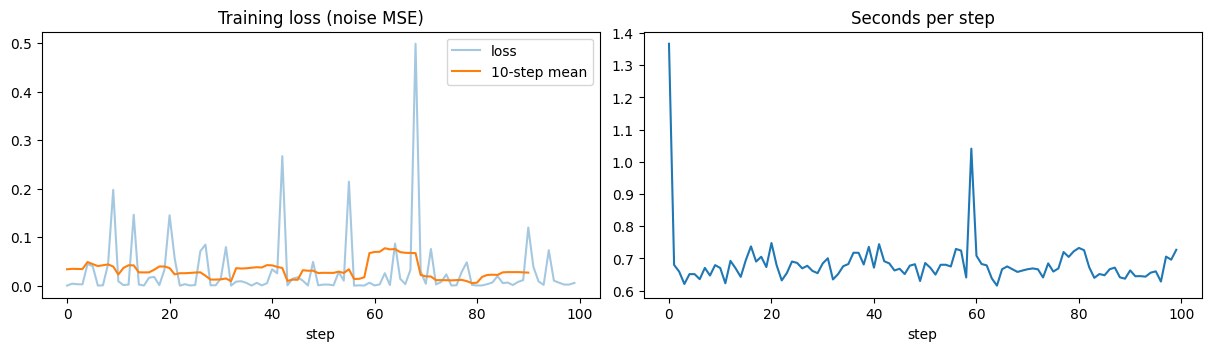

PASS  all losses finite
PASS  every LoRA tensor updated
PASS  only LoRA weights trainable (base frozen)
Estimated time for 2,000 steps: 22 min (peak GPU memory 2.44 GB)


In [25]:
# Plot the trial and check losses, updates and frozen weights.
losses = np.array(trial.losses)
window = max(1, len(losses) // 10)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), layout="constrained")
axes[0].plot(losses, alpha=0.4, label="loss")
axes[0].plot(np.convolve(losses, np.ones(window) / window, mode="valid"), label=f"{window}-step mean")
axes[0].set_xlabel("step"); axes[0].set_title("Training loss (noise MSE)"); axes[0].legend()
axes[1].plot(trial.step_seconds); axes[1].set_xlabel("step"); axes[1].set_title("Seconds per step")
plt.show()

trial_checks = {
    "all losses finite": trial.all_finite,
    "every LoRA tensor updated": trial.changed_tensors == trial.trainable_tensors > 0,
    "only LoRA weights trainable (base frozen)": trial.only_lora_trainable,
}
for name, passed in trial_checks.items():
    print(f"{'PASS' if passed else 'FAIL'}  {name}")
if trial_summary["median_step_seconds"]:
    print(f"Estimated time for 2,000 steps: {2000 * trial_summary['median_step_seconds'] / 60:.0f} min "
          f"(peak GPU memory {trial_summary['peak_gpu_memory_gb']} GB)")
if not all(trial_checks.values()):
    raise RuntimeError("The training trial failed a check; see above.")

### 7.3 Save the adapter and reload it in a fresh process

Save the LoRA weights (`pytorch_lora_weights.safetensors`) and `trial_config.json` to Drive. Then:

1. compare the adapter tensors in memory with the file;
2. generate three fixed validation inpaintings in this notebook;
3. start a **new Python process** that loads the base model plus the saved adapter, checks its tensors against the file and generates the same three cases;
4. compare the outputs of the two processes, and confirm that the adapter changes the output relative to the pretrained model.

Before saving, the adapters are cast to the pipeline's fp16 dtype, as a fresh load would do, so both processes run identical weights; small differences can still come from GPU kernels.

In [26]:
# Save the trial LoRA, reload it in a separate process and compare outputs.
LORA_DIR = OUTPUT_DIR / "lora_trial"
if LORA_DIR.exists():
    shutil.rmtree(LORA_DIR)
prepare_for_inference(train_pipe.unet, PIPE_DTYPE)
lora_file_path = save_lora(train_pipe.unet, LORA_DIR, trial_cfg, {
    "trial": trial_summary, "inference": INFER, "base_revision": BASE_REVISION,
    "data": {"train_images": len(train_set), "masks": "TrainingMaskSampler 5-20%", "split_seed": SEED}})
memory_check = compare_adapter_to_file(train_pipe.unet, LORA_DIR, "default")
print(f"Saved {lora_file_path.name} ({lora_file_path.stat().st_size / 1024**2:.1f} MB) · in-memory vs file: {memory_check}")

infer_kwargs = {k: INFER[k] for k in ("work_res", "prompt", "negative_prompt", "steps", "guidance")}
trial_handler = StableDiffusionInpaint("sd15_trial", model_id=MODEL_ID, lora_path=LORA_DIR, pipe=train_pipe, **infer_kwargs)
reload_cases = [{"input_path": r["input_path"], "mask_path": r["mask_path"], "seed": SEED} for r in select_rows[:3]]
(LORA_DIR / "reload_cases.json").write_text(json.dumps(reload_cases, indent=1), encoding="utf-8")
in_memory = run_cases(trial_handler, PREPARED_DIR, reload_cases)
train_pipe.unet.disable_adapters()
pretrained_out = run_cases(trial_handler, PREPARED_DIR, reload_cases)
train_pipe.unet.enable_adapters()

process = subprocess.run(
    [sys.executable, "-m", "src.train.inpaint_lora", "reload-check", "--lora", str(LORA_DIR),
     "--cases", str(LORA_DIR / "reload_cases.json"), "--prepared-dir", str(PREPARED_DIR),
     "--out", str(LORA_DIR / "reload_check.npz")],
    cwd=CODE_DIR, env={**os.environ, "PYTHONPATH": str(CODE_DIR)}, capture_output=True, text=True)
if process.returncode != 0:
    print(process.stderr[-4000:])
    raise RuntimeError("The fresh-process reload failed.")
reload_report = json.loads((LORA_DIR / "reload_check.json").read_text(encoding="utf-8"))
fresh = np.load(LORA_DIR / "reload_check.npz")["outputs"]
diff_fresh = np.abs(fresh.astype(np.float32) - in_memory.astype(np.float32))
diff_adapter = np.abs(in_memory.astype(np.float32) - pretrained_out.astype(np.float32))
tensors = reload_report["adapter_tensors"]
reload_checks = {
    "all saved tensors loaded in the new process": tensors["matching_keys"] == tensors["saved_tensors"] > 0
                                                    and tensors["missing_in_model"] == 0,
    f"reloaded tensors match the file (max diff {tensors['max_abs_diff']:.1e})": tensors["max_abs_diff"] <= 2e-3,
    f"outputs match across processes (mean |diff| {diff_fresh.mean():.3f} / 255)": diff_fresh.mean() <= 2.0,
    f"adapter changes the output (mean |diff| vs pretrained {diff_adapter.mean():.2f} / 255)": diff_adapter.mean() > 0,
}
for name, passed in reload_checks.items():
    print(f"{'PASS' if passed else 'FAIL'}  {name}")
print(f"Fresh process: load {reload_report['load_seconds']}s · version {reload_report['model_version']}")
if not all(reload_checks.values()):
    raise RuntimeError("Checkpoint reload check failed; see above.")

Saved pytorch_lora_weights.safetensors (3.1 MB) · in-memory vs file: {'saved_tensors': 256, 'loaded_tensors': 256, 'matching_keys': 256, 'missing_in_model': 0, 'max_abs_diff': 0.0}
PASS  all saved tensors loaded in the new process
PASS  reloaded tensors match the file (max diff 0.0e+00)
PASS  outputs match across processes (mean |diff| 0.000 / 255)
PASS  adapter changes the output (mean |diff| vs pretrained 1.31 / 255)
Fresh process: load 13.62s · version stable-diffusion-v1-5/stable-diffusion-inpainting@8a4288a76071+lora:bbeed152dc68


### 7.4 Before/after look (not an evaluation)

Three validation crops after compositing: pretrained model, the 100-step trial adapter in this notebook, and the same adapter reloaded in the fresh process. With so few steps the outputs should look similar to the pretrained model; the point is that the two right-hand columns match.

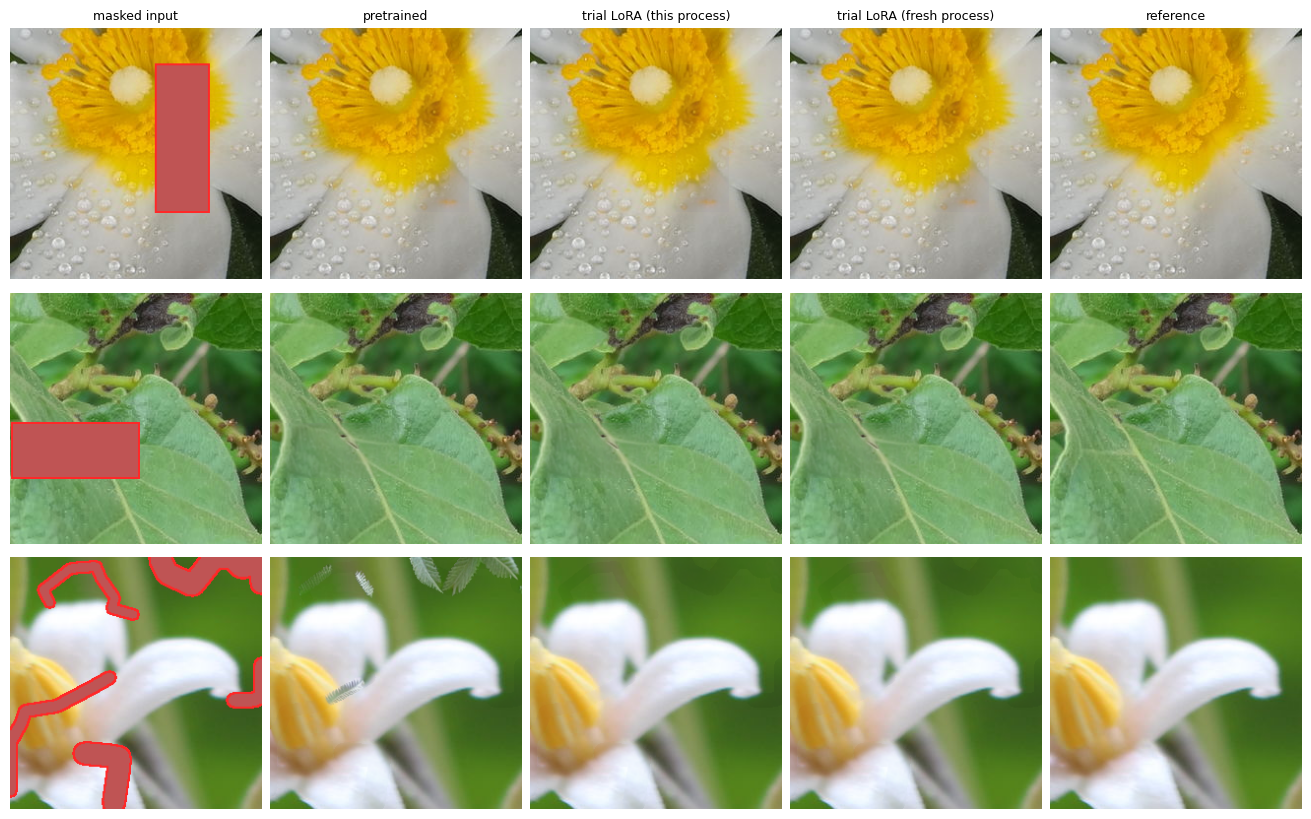

In [27]:
# Compare pretrained, trial adapter and reloaded adapter on three crops.
labels = ["masked input", "pretrained", "trial LoRA (this process)", "trial LoRA (fresh process)", "reference"]
fig, axes = plt.subplots(len(reload_cases), len(labels), figsize=(2.6 * len(labels), 2.7 * len(reload_cases)),
                         layout="constrained", squeeze=False)
for r, case in enumerate(reload_cases):
    masked = read_rgb(PREPARED_DIR / case["input_path"])
    mask = load_mask_png(PREPARED_DIR / case["mask_path"])
    reference = cases[r]["target"]
    comp = lambda raw: np.where(mask[..., None] > 0, raw, masked)  # noqa: E731
    for c, img in enumerate((overlay(masked, mask), comp(pretrained_out[r]), comp(in_memory[r]), comp(fresh[r]), reference)):
        axes[r, c].imshow(img)
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(labels[c], fontsize=9)
plt.show()
del train_pipe, trial_handler
free_gpu_memory()

## 8 · Common interface for all four tasks

Build the application registry from `configs/app.json`: baselines for every task, pretrained SD 1.5 inpainting with the selected settings, and the trial adapter as a separate method so the integration path for fine-tuned checkpoints is exercised now. The default inpainting method stays the pretrained model until the Week 2 checkpoint is validated.

`src/data/benchmark_examples.py` produces fixed degraded inputs from validation crops for all four tasks (σ = 15 noise, 4× bicubic downsampling, grayscale, fixed masks). The app uses it for its benchmark mode, the only place where it shows PSNR/SSIM. Peng and Jinyuan can swap in their official degradation code later.

The interface description for teammates is written to `docs/inference_interface.md`. Please share it in the channel so we can agree on it this week.

In [28]:
%%writefile "{CODE_DIR}/src/data/benchmark_examples.py"
"""Validation crops with fixed degradations for the application's benchmark mode.

The app shows PSNR/SSIM only for these examples, where the clean reference is known.
Degradations follow the README recipes (section 5):
  denoising        Gaussian noise, sigma 15 (0-255 units), seed fixed per sample
  super_resolution 256 -> 64 bicubic downsampling (x4)
  colorization     grayscale replicated to three channels
  inpainting       fixed mask from the inpainting manifest (or regenerated deterministically)
Replace these preview recipes with the shared generators once each task owner publishes them.
"""
from __future__ import annotations

import csv
from pathlib import Path

import numpy as np
from PIL import Image

from src.data.inpaint_masks import apply_mask, fixed_eval_masks, load_mask_png, seed_for
from src.evaluation.inpaint_metrics import full_metrics, inpaint_metrics


class BenchmarkExamples:
    def __init__(self, prepared_dir, split: str = "val", inpaint_manifest=None, limit: int = 24, seed: int = 42):
        self.prepared_dir = Path(prepared_dir)
        self.split, self.seed = split, seed
        with open(self.prepared_dir / "manifests" / f"{split}.csv", encoding="utf-8-sig", newline="") as f:
            rows = [r for r in csv.DictReader(f) if r.get("eval_crop_path")]
        self.rows = {r["sample_id"]: r for r in sorted(rows, key=lambda r: r["sample_id"])[:limit]}
        self.masks, self.mask_info = {}, {}
        manifest_rows = []
        if inpaint_manifest and Path(inpaint_manifest).is_file():
            with open(inpaint_manifest, encoding="utf-8-sig", newline="") as f:
                manifest_rows = [r for r in csv.DictReader(f) if r["sample_id"] in self.rows]
        for r in manifest_rows:
            self.masks[r["sample_id"]] = load_mask_png(self.prepared_dir / r["mask_path"])
            self.mask_info[r["sample_id"]] = {"mask_type": r["mask_type"], "mask_coverage": float(r["mask_coverage"])}
        missing = [sid for sid in self.rows if sid not in self.masks]
        if missing:  # same deterministic generator as the saved manifests
            all_ids = [r["sample_id"] for r in rows]
            generated = fixed_eval_masks(all_ids, split, seed)
            for sid in missing:
                mask, params, _ = generated[sid]
                self.masks[sid] = mask
                self.mask_info[sid] = {"mask_type": params["mask_type"], "mask_coverage": params["coverage"]}

    def __len__(self):
        return len(self.rows)

    def list(self) -> list[dict]:
        return [{"sample_id": sid, "source_image_id": f"{r['official_split']}/{r['relative_path']}",
                 **self.mask_info[sid]} for sid, r in self.rows.items()]

    def reference(self, sample_id: str) -> np.ndarray:
        with Image.open(self.prepared_dir / self.rows[sample_id]["eval_crop_path"]) as src:
            return np.asarray(src.convert("RGB"))

    def degraded(self, sample_id: str, task: str):
        """Return (input PIL image, mask or None) for one task."""
        if sample_id not in self.rows:
            raise KeyError(f"Unknown example {sample_id!r}")
        ref = self.reference(sample_id)
        if task == "denoising":
            rng = np.random.default_rng(seed_for(self.seed, "denoise_sigma15", sample_id))
            noisy = ref.astype(np.float32) + rng.normal(0.0, 15.0, ref.shape)
            return Image.fromarray(np.clip(np.round(noisy), 0, 255).astype(np.uint8)), None
        if task == "super_resolution":
            h, w = ref.shape[:2]
            return Image.fromarray(ref).resize((w // 4, h // 4), Image.BICUBIC), None
        if task == "colorization":
            return Image.fromarray(ref).convert("L").convert("RGB"), None
        if task == "inpainting":
            mask = self.masks[sample_id]
            return Image.fromarray(apply_mask(ref, mask)), mask
        raise ValueError(f"Unknown task {task!r}")

    def metrics(self, sample_id: str, task: str, output, mask=None) -> dict:
        ref = self.reference(sample_id)
        out = np.asarray(output)
        if out.shape != ref.shape:
            return {"note": f"output {out.shape[1]}x{out.shape[0]} differs from reference {ref.shape[1]}x{ref.shape[0]}"}
        if task == "inpainting":
            m = inpaint_metrics(out, ref, mask if mask is not None else self.masks[sample_id])
            return {"masked_psnr": m["masked_psnr"], "masked_ssim": m["masked_ssim"], "boundary_l1": m["boundary_l1"]}
        return full_metrics(out, ref)

Writing /content/AAI521-Group1-PlantSR-Restoration/src/data/benchmark_examples.py


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


,task,method,success,input_size,processed_size,output_size,elapsed_seconds,masked_psnr,psnr,ssim,masked_ssim,error
0,inpainting,opencv_telea,True,"[256, 256]","[256, 256]","[256, 256]",0.022,21.3260,NaN,NaN,0.6619,None
1,inpainting,sd15_pretrained,True,"[256, 256]","[512, 512]","[256, 256]",6.041,19.9821,NaN,NaN,0.5462,None
2,inpainting,sd15_finetuned,True,"[256, 256]","[512, 512]","[256, 256]",8.022,20.1730,NaN,NaN,0.5591,None
3,denoising,opencv_nlmeans,True,"[256, 256]","[256, 256]","[256, 256]",0.263,NaN,30.1928,0.7407,NaN,None
4,super_resolution,bicubic_x4,True,"[64, 64]","[64, 64]","[256, 256]",0.001,NaN,31.3814,0.8440,NaN,None
5,colorization,grayscale_rgb,True,"[256, 256]","[256, 256]","[256, 256]",0.000,NaN,13.3090,0.8394,NaN,None


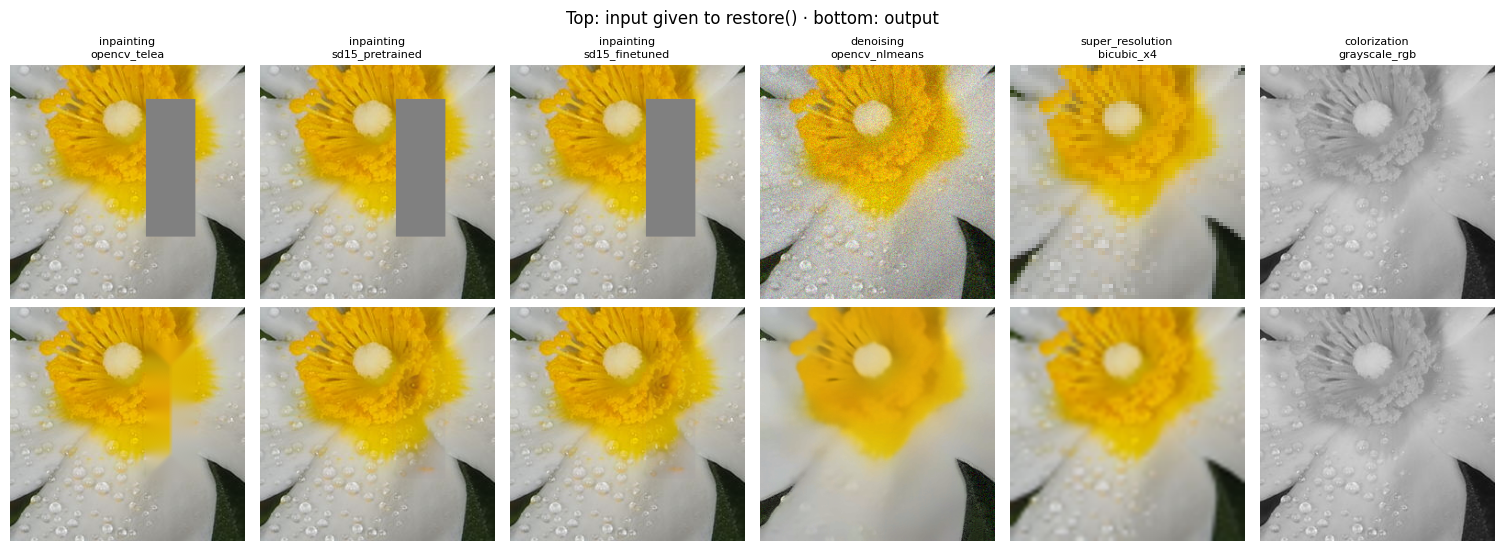

In [29]:
# Call restore() for every task through the application registry.
import src.data.benchmark_examples as examples_module
importlib.reload(examples_module)
from src.data.benchmark_examples import BenchmarkExamples
from src.inference.factory import build_registry, load_config

runtime_config = load_config(CODE_DIR / "configs" / "app.json")
runtime_config["inpainting"].update(lora_path=str(LORA_DIR), lora_label="SD 1.5 + PlantSR LoRA (100-step trial)",
                                    default_method="sd15_pretrained")
app_registry = build_registry(runtime_config)
set_default_registry(app_registry)
examples = BenchmarkExamples(PREPARED_DIR, "val", INPAINT_MANIFEST["val"], limit=24, seed=SEED)
example_id = examples.list()[0]["sample_id"]

calls = [("inpainting", "opencv_telea"), ("inpainting", "sd15_pretrained"), ("inpainting", "sd15_finetuned"),
         ("denoising", None), ("super_resolution", None), ("colorization", None)]
interface_rows, interface_images = [], []
for task, method in calls:
    image, mask = examples.degraded(example_id, task)
    res = restore(image, task, mask=mask, seed=SEED, method=method)
    scores = examples.metrics(example_id, task, res.image, mask) if res.success else {}
    interface_rows.append({**res.metadata(), **{k: round(v, 4) for k, v in scores.items() if isinstance(v, float)}})
    interface_images.append((image, res.image, f"{task}\n{res.method}"))
interface_df = pd.DataFrame(interface_rows)
display(interface_df[[c for c in ("task", "method", "success", "input_size", "processed_size", "output_size",
                                  "elapsed_seconds", "masked_psnr", "psnr", "ssim", "masked_ssim", "error")
                      if c in interface_df]])

fig, axes = plt.subplots(2, len(interface_images), figsize=(2.5 * len(interface_images), 5.4), layout="constrained")
for c, (inp, out, title) in enumerate(interface_images):
    axes[0, c].imshow(inp); axes[0, c].set_title(title, fontsize=8)
    if out is not None:
        axes[1, c].imshow(out)
    axes[0, c].axis("off"); axes[1, c].axis("off")
fig.suptitle("Top: input given to restore() · bottom: output")
plt.show()
if not interface_df.success.all():
    raise RuntimeError("Some restore() calls failed; see the error column.")

In [30]:
%%writefile "{CODE_DIR}/docs/inference_interface.md"
# Common inference interface

Proposal from Week 1 (Ali) for the four restoration tasks, building on the README signature. Please comment on it in the team channel before we freeze it at the end of Week 1.

```python
from src.inference.interface import restore

result = restore(image, task, mask=None, seed=42)                       # agreed signature
result = restore(image, task, mask=None, seed=42, method="sd15_finetuned")  # optional: pick a method
```

| Argument | Meaning |
| --- | --- |
| `image` | PIL image, RGB `uint8` array or file path. Converted to RGB; transparency is flattened onto white. |
| `task` | `"denoising"`, `"super_resolution"`, `"colorization"` or `"inpainting"`. |
| `mask` | Inpainting only. Same size as `image`; **1/white = missing (reconstruct), 0/black = preserve**. PIL, array or path. |
| `seed` | Integer used by generative models; deterministic methods ignore it. |
| `method` | Optional. Defaults to the task's default method (baseline, pretrained or fine-tuned). |

`restore` never raises for bad input or model errors. It returns a `RestoreResult`:

| Field | Meaning |
| --- | --- |
| `image` | Output PIL RGB image (`None` on failure) |
| `task`, `method`, `model_version` | What ran, including the checkpoint revision, e.g. `stable-diffusion-v1-5/stable-diffusion-inpainting@<commit>+lora:<sha12>` |
| `input_size`, `processed_size`, `output_size` | `(width, height)` received, actually processed by the model, and returned |
| `elapsed_seconds` | Wall time for the call, including model loading when it happens |
| `success`, `error` | `False` with a readable message on failure (validation errors, GPU out-of-memory, etc.) |
| `extra` | Optional task-specific details (inpainting adds `mask_coverage`) |

`result.metadata()` gives the same information as a JSON-safe dict for the app and the results CSV.

## Adding your model (Peng: SR, Jinyuan: denoising/colorization)

Write one small subclass of `TaskHandler` per method and register it in `src/inference/factory.py`:

```python
from PIL import Image
from src.inference.interface import TaskHandler

class RealESRGANx4(TaskHandler):
    task = "super_resolution"
    method = "realesrgan_finetuned"
    label = "Real-ESRGAN x4 (PlantSR fine-tuned)"
    description = "Real-ESRGAN generator fine-tuned with L1 on PlantSR 64->256 pairs."
    uses_gpu = True          # lets the registry unload it when another big model is needed
    generative = False       # True if the seed changes the output

    def __init__(self, checkpoint):
        self.checkpoint = checkpoint
        self.version = f"kornia/real_esrgan+ft:{checkpoint}"
        self.model = None
        super().__init__()

    def load(self):          # called lazily on the first request
        self.model = ...     # build the network, load weights, .to("cuda").eval()
        self._loaded = True

    def unload(self):
        self.model = None
        self._loaded = False

    def run(self, image: Image.Image, mask, seed: int):
        # image: RGB PIL at the uploaded size. Resize/tile here if needed and report it.
        output = ...         # RGB PIL
        processed_size = image.size
        return output, processed_size
```

```python
# src/inference/factory.py
registry.register(RealESRGANx4(checkpoint="checkpoints/sr/realesrgan_plantsr_v1.pth"), default=True)
```

Conventions:

- **Images in and out are RGB PIL images, values 0–255.** Do your own normalisation inside `run`.
- **Do not load weights at import time or in `__init__`.** Load in `load()`; the app keeps at most one large GPU model loaded (`max_gpu_models`) and calls `unload()` on the least recently used one.
- **Report `processed_size` honestly.** If you downscale a large upload, tile, or crop, return the size the model actually saw; the app displays it.
- **Inpainting outputs are composited**: `final = (1 - mask) * input + mask * generated`, so visible pixels are copied exactly.
- **Determinism**: use `seed` for any sampling (`torch.Generator("cpu").manual_seed(seed)`), so benchmark runs are reproducible.
- Baselines (`opencv_telea`, `opencv_nlmeans`, `bicubic_x4`, `grayscale_rgb`) are already registered, so the app works end to end before every model is ready.

## Quick test for a new handler

```python
from src.inference.factory import build_registry
from src.inference.interface import set_default_registry, restore

registry = build_registry(with_diffusion=False)
registry.register(RealESRGANx4("..."), default=True)
set_default_registry(registry)
r = restore("prepared/crops/val/<sample_id>.png", "super_resolution")
print(r.success, r.error, r.metadata())
```

Writing /content/AAI521-Group1-PlantSR-Restoration/docs/inference_interface.md


## 9 · Application layout (C3)

The Flask app is written to `app/`. It covers the Week 1 layout and the README requirements that do not depend on fine-tuned models:

- **Image**: drag-and-drop JPG/PNG upload with format and size checks, or a *benchmark example* (validation crop with a fixed degradation);
- **Task and method**: four task cards, a method menu (baselines, pretrained, fine-tuned) with descriptions, and a seed for generative methods;
- **Mask**: brush and eraser, brush size, clear, mask upload (white = fill), live coverage percentage; benchmark masks are locked;
- **Processing**: one background GPU worker with a queue, position and elapsed time; the registry keeps at most one large model in memory;
- **Results**: side-by-side input/output, received → processed → output sizes, model version, timing; PSNR/SSIM only for benchmark examples; PNG download.

In Colab the app runs inside this notebook's runtime and opens through Colab's private proxy link, which works only for you while the notebook is running. Week 2 moves it to the RTX 4080 with a tunnel for other devices.

### 9.1 Write the app files

In [31]:
%%writefile "{CODE_DIR}/app/app.py"
"""PlantSR restoration web application (Flask).

Local / GPU machine:
    python app/app.py --config configs/app.json --prepared-dir /path/to/prepared --port 7860
Colab: the Week 1 notebook builds the registry and calls `create_app(...)` directly.

All GPU work goes through one background worker thread, so requests are queued instead of
competing for GPU memory; the registry keeps at most one large model loaded at a time.
"""
from __future__ import annotations

import argparse
import io
import sys
import threading
import time
import uuid
from collections import OrderedDict
from pathlib import Path

from flask import Flask, jsonify, render_template, request, send_file
from PIL import Image, ImageOps, UnidentifiedImageError

ROOT = Path(__file__).resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.inference.interface import TASKS, Registry, normalize_mask  # noqa: E402

ALLOWED_FORMATS = {"JPEG", "PNG"}
MAX_PIXELS = 40_000_000
KEEP_JOBS = 100


def read_upload(storage, what: str = "image") -> Image.Image:
    data = storage.read() if storage else b""
    if not data:
        raise ValueError(f"No {what} file was received.")
    try:
        with Image.open(io.BytesIO(data)) as probe:
            fmt = probe.format
            if probe.width * probe.height > MAX_PIXELS:
                raise ValueError(f"The {what} is too large ({probe.width}x{probe.height}); keep it under 40 megapixels.")
        if fmt not in ALLOWED_FORMATS:
            raise ValueError(f"Unsupported {what} format {fmt}; upload a JPG or PNG.")
        image = Image.open(io.BytesIO(data))
        image = ImageOps.exif_transpose(image)
        image.load()
        return image
    except (UnidentifiedImageError, OSError) as exc:
        raise ValueError(f"The {what} could not be read as a JPG or PNG file.") from exc


def png_bytes(image: Image.Image) -> bytes:
    buffer = io.BytesIO()
    image.save(buffer, format="PNG")
    return buffer.getvalue()


class JobQueue:
    """Single GPU worker; jobs and results are kept in memory only."""

    def __init__(self, registry: Registry, examples=None):
        self.registry, self.examples = registry, examples
        self.jobs: OrderedDict[str, dict] = OrderedDict()
        self.order: list[str] = []
        self.lock = threading.Lock()
        self.wakeup = threading.Condition(self.lock)
        threading.Thread(target=self._loop, name="restoration-worker", daemon=True).start()

    def submit(self, job: dict) -> dict:
        job.update(id=uuid.uuid4().hex[:12], status="queued", created_at=time.time(), started_at=None,
                   finished_at=None, result=None, metrics=None, error=None)
        with self.lock:
            self.jobs[job["id"]] = job
            self.order.append(job["id"])
            while len(self.jobs) > KEEP_JOBS:  # drop the oldest finished job
                oldest = next((k for k, v in self.jobs.items() if v["status"] in ("done", "error")), None)
                if oldest is None:
                    break
                self.jobs.pop(oldest)
            self.wakeup.notify()
        return job

    def position(self, job_id: str) -> int:
        with self.lock:
            queued = [j for j in self.order if self.jobs.get(j, {}).get("status") == "queued"]
        return queued.index(job_id) + 1 if job_id in queued else 0

    def pending(self) -> int:
        with self.lock:
            return sum(1 for j in self.jobs.values() if j["status"] in ("queued", "running"))

    def _loop(self):
        while True:
            with self.lock:
                while not self.order:
                    self.wakeup.wait()
                job = self.jobs.get(self.order.pop(0))
                if job is None:
                    continue
                job["status"], job["started_at"] = "running", time.time()
            result = self.registry.restore(job.pop("_image"), job["task"], job.pop("_mask", None),
                                           seed=job["seed"], method=job["method"])
            job["result"] = result.metadata()
            if result.success:
                job["_png"] = png_bytes(result.image)
                if job.get("example_id") and self.examples is not None:
                    try:
                        job["metrics"] = self.examples.metrics(job["example_id"], job["task"], result.image,
                                                               job.get("_example_mask"))
                    except Exception as exc:  # noqa: BLE001 - metrics are optional
                        job["metrics"] = {"note": f"metrics unavailable: {exc}"}
            job["error"] = result.error
            job["status"] = "done" if result.success else "error"
            job["finished_at"] = time.time()


def public(job: dict, queue: JobQueue) -> dict:
    data = {k: v for k, v in job.items() if not k.startswith("_")}
    data["queue_position"] = queue.position(job["id"]) if job["status"] == "queued" else 0
    if job["status"] == "done":
        data["output_url"] = f"api/jobs/{job['id']}/output.png"
    return data


def create_app(registry: Registry, examples=None, max_upload_mb: int = 25) -> Flask:
    app = Flask(__name__, template_folder="templates", static_folder="static")
    app.config["MAX_CONTENT_LENGTH"] = max_upload_mb * 1024 * 1024
    queue = JobQueue(registry, examples)
    app.extensions["plantsr_queue"] = queue

    @app.get("/")
    def index():
        return render_template("index.html")

    @app.get("/api/health")
    def health():
        info = {"status": "ok", "pending_jobs": queue.pending(), "device": "cpu", "gpu": None,
                "examples": len(examples) if examples is not None else 0}
        try:
            import torch

            if torch.cuda.is_available():
                info.update(device="cuda", gpu=torch.cuda.get_device_name(0),
                            gpu_memory_allocated_gb=round(torch.cuda.memory_allocated() / 1024 ** 3, 2))
        except ImportError:
            pass
        info["loaded_models"] = [f"{t['task']}/{m['method']}" for t in registry.describe()
                                 for m in t["methods"] if m["uses_gpu"] and m["loaded"]]
        return jsonify(info)

    @app.get("/api/tasks")
    def tasks():
        return jsonify(registry.describe())

    @app.get("/api/examples")
    def example_list():
        return jsonify(examples.list() if examples is not None else [])

    @app.get("/api/examples/<sample_id>/<kind>.png")
    def example_file(sample_id, kind):
        if examples is None:
            return jsonify(error="No benchmark examples are configured."), 404
        task = request.args.get("task", "inpainting")
        try:
            image, mask = examples.degraded(sample_id, task)
        except (KeyError, ValueError) as exc:
            return jsonify(error=str(exc)), 404
        if kind == "input":
            payload = png_bytes(image)
        elif kind == "mask" and mask is not None:
            payload = png_bytes(Image.fromarray(mask * 255))
        else:
            return jsonify(error="Unknown file."), 404
        return send_file(io.BytesIO(payload), mimetype="image/png")

    @app.post("/api/jobs")
    def submit():
        form = request.form
        task = form.get("task", "")
        try:
            if task not in TASKS:
                raise ValueError(f"Choose a task: {', '.join(TASKS)}.")
            handler = registry.handler(task, form.get("method") or None)
            try:
                seed = int(form.get("seed", 42))
            except ValueError as exc:
                raise ValueError("The seed must be a whole number.") from exc
            job = {"task": task, "method": handler.method, "seed": seed, "source": form.get("source", "upload")}
            if job["source"] == "example":
                if examples is None:
                    raise ValueError("Benchmark examples are not available on this server.")
                job["example_id"] = form.get("example_id", "")
                image, mask = examples.degraded(job["example_id"], task)
                job["_example_mask"] = mask
            else:
                image = read_upload(request.files.get("image"))
                mask = None
                if handler.needs_mask:
                    if not request.files.get("mask"):
                        raise ValueError("Paint or upload a mask first (white = area to fill).")
                    mask_image = read_upload(request.files.get("mask"), "mask")
                    if mask_image.size != image.size:
                        job["mask_resized"] = True
                    mask = normalize_mask(mask_image, image.size)
            job["input_size"] = list(image.size)
            job["_image"], job["_mask"] = image, mask
        except (ValueError, KeyError) as exc:
            return jsonify(error=str(exc).strip("'\"")), 400
        job = queue.submit(job)
        return jsonify(public(job, queue)), 202

    @app.get("/api/jobs/<job_id>")
    def job_status(job_id):
        job = queue.jobs.get(job_id)
        if job is None:
            return jsonify(error="Unknown or expired job."), 404
        return jsonify(public(job, queue))

    @app.get("/api/jobs/<job_id>/output.png")
    def job_output(job_id):
        job = queue.jobs.get(job_id)
        if job is None or "_png" not in job:
            return jsonify(error="No output for this job."), 404
        name = f"plantsr_{job['task']}_{job['method']}_{job_id}.png"
        return send_file(io.BytesIO(job["_png"]), mimetype="image/png",
                         as_attachment=request.args.get("download") == "1", download_name=name)

    @app.errorhandler(413)
    def too_large(_):
        return jsonify(error=f"Upload is larger than {max_upload_mb} MB."), 413

    return app


def main(argv=None) -> None:
    from src.inference.factory import build_registry, load_config

    parser = argparse.ArgumentParser(description="PlantSR restoration web app")
    parser.add_argument("--config", default=str(ROOT / "configs" / "app.json"))
    parser.add_argument("--host", default="127.0.0.1")
    parser.add_argument("--port", type=int, default=7860)
    parser.add_argument("--prepared-dir", help="PlantSR prepared/ folder for benchmark examples")
    parser.add_argument("--inpaint-manifest", help="Fixed inpainting manifest (val) for example masks")
    parser.add_argument("--no-diffusion", action="store_true", help="Baselines only (no GPU models)")
    args = parser.parse_args(argv)

    registry = build_registry(load_config(args.config), with_diffusion=not args.no_diffusion)
    examples = None
    if args.prepared_dir:
        from src.data.benchmark_examples import BenchmarkExamples

        examples = BenchmarkExamples(args.prepared_dir, "val", args.inpaint_manifest)
    app = create_app(registry, examples)
    try:
        from waitress import serve

        print(f"Serving on http://{args.host}:{args.port} (waitress)")
        serve(app, host=args.host, port=args.port, threads=8)
    except ImportError:
        app.run(host=args.host, port=args.port, threaded=True, use_reloader=False)


if __name__ == "__main__":
    main()

Writing /content/AAI521-Group1-PlantSR-Restoration/app/app.py


In [32]:
%%writefile "{CODE_DIR}/app/templates/index.html"
<!doctype html>
<html lang="en">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>PlantSR Restoration</title>
  <link rel="icon" href="data:,">
  <link rel="stylesheet" href="static/style.css">
</head>
<body>
  <header class="topbar">
    <div class="brand">
      <span class="logo" aria-hidden="true"></span>
      <div>
        <h1>PlantSR Restoration</h1>
        <p class="subtitle">Denoising · Super-resolution · Colorization · Inpainting</p>
      </div>
    </div>
    <div id="health" class="pill" title="Server status">Connecting…</div>
  </header>

  <main class="layout">
    <section class="panel controls" aria-label="Controls">
      <div class="step">
        <h2><span class="num">1</span> Image</h2>
        <div class="segmented" role="tablist">
          <button type="button" class="seg active" data-source="upload" role="tab" aria-selected="true">Upload</button>
          <button type="button" class="seg" data-source="example" role="tab" aria-selected="false">Benchmark example</button>
        </div>
        <div id="uploadPane">
          <label id="dropzone" class="dropzone">
            <input id="fileInput" type="file" accept=".jpg,.jpeg,.png,image/jpeg,image/png">
            <strong>Drop a JPG or PNG</strong>
            <span>or click to browse</span>
          </label>
        </div>
        <div id="examplePane" hidden>
          <select id="exampleSelect" aria-label="Benchmark example"></select>
          <p class="hint">Validation crop with a fixed degradation. Scores are computed against the known reference.</p>
        </div>
        <p id="imageInfo" class="hint"></p>
      </div>

      <div class="step">
        <h2><span class="num">2</span> Task</h2>
        <div id="taskList" class="task-grid" role="radiogroup" aria-label="Restoration task"></div>
        <label class="field">Method
          <select id="methodSelect"></select>
        </label>
        <p id="methodDesc" class="hint"></p>
        <label id="seedRow" class="field inline">Seed
          <input id="seedInput" type="number" value="42" step="1">
        </label>
      </div>

      <div id="maskTools" class="step" hidden>
        <h2><span class="num">3</span> Mask <span class="hint">white = area to fill</span></h2>
        <div class="row">
          <div class="segmented small">
            <button type="button" class="seg active" data-tool="brush">Brush</button>
            <button type="button" class="seg" data-tool="eraser">Eraser</button>
          </div>
          <label class="field inline grow">Size
            <input id="brushSize" type="range" min="4" max="96" value="28">
          </label>
        </div>
        <div class="row">
          <button type="button" id="clearMask" class="button">Clear</button>
          <label class="button">Upload mask<input id="maskFile" type="file" accept="image/png,image/jpeg" hidden></label>
          <label class="check"><input id="showMask" type="checkbox" checked> Show</label>
        </div>
        <p class="coverage">Coverage <strong id="coverage">0.0%</strong> <span id="maskNote" class="hint"></span></p>
      </div>

      <button type="button" id="runBtn" class="button primary wide" disabled>Restore image</button>
      <div id="status" class="status" role="status" aria-live="polite"></div>
    </section>

    <section class="panel viewer" aria-label="Images">
      <div class="compare">
        <figure>
          <figcaption>Input <span id="inputDims" class="dims"></span></figcaption>
          <div class="stage" id="inputStage">
            <canvas id="imageCanvas"></canvas>
            <canvas id="maskCanvas"></canvas>
            <div id="inputPlaceholder" class="placeholder">Upload an image or choose a benchmark example</div>
          </div>
        </figure>
        <figure>
          <figcaption>Output <span id="outputDims" class="dims"></span></figcaption>
          <div class="stage">
            <img id="outputImg" alt="Restored output" hidden>
            <div id="outputPlaceholder" class="placeholder">The restored image appears here</div>
          </div>
        </figure>
      </div>
      <div id="resultBox" class="result" hidden>
        <table id="infoTable"></table>
        <div class="result-actions">
          <a id="downloadBtn" class="button primary" href="#" download>Download PNG</a>
        </div>
      </div>
    </section>
  </main>
  <script src="static/app.js"></script>
</body>
</html>

Writing /content/AAI521-Group1-PlantSR-Restoration/app/templates/index.html


In [33]:
%%writefile "{CODE_DIR}/app/static/style.css"
:root {
  --bg: #f4f6f3;
  --panel: #ffffff;
  --ink: #1d2a21;
  --muted: #5d6b61;
  --line: #dde3dc;
  --accent: #2f7a46;
  --accent-ink: #ffffff;
  --accent-soft: #e5f1e8;
  --danger: #b3261e;
  --mask: rgb(255, 48, 48);
  --radius: 10px;
  font-family: system-ui, -apple-system, "Segoe UI", Roboto, sans-serif;
  color: var(--ink);
  background: var(--bg);
}

* { box-sizing: border-box; }
[hidden] { display: none !important; }
body { margin: 0; }
h1, h2, p { margin: 0; }
button, input, select { font: inherit; color: inherit; }

.topbar {
  display: flex; align-items: center; justify-content: space-between; gap: 16px;
  padding: 14px 24px; background: var(--panel); border-bottom: 1px solid var(--line);
}
.brand { display: flex; align-items: center; gap: 12px; }
.logo {
  width: 34px; height: 34px; border-radius: 50% 0 50% 0; background: var(--accent);
  transform: rotate(-12deg);
}
h1 { font-size: 1.15rem; font-weight: 650; }
.subtitle { color: var(--muted); font-size: 0.85rem; }
.pill {
  font-size: 0.8rem; padding: 5px 10px; border-radius: 999px; background: var(--accent-soft);
  color: var(--accent); white-space: nowrap;
}
.pill.offline { background: #fbe9e7; color: var(--danger); }

.layout {
  display: grid; grid-template-columns: minmax(300px, 360px) 1fr; gap: 20px;
  padding: 20px 24px; max-width: 1500px; margin: 0 auto;
}
@media (max-width: 860px) { .layout { grid-template-columns: 1fr; padding: 12px; } }
.panel { background: var(--panel); border: 1px solid var(--line); border-radius: var(--radius); padding: 18px; }
.controls { display: flex; flex-direction: column; gap: 18px; align-self: start; }
.step { display: flex; flex-direction: column; gap: 10px; }
h2 { font-size: 0.95rem; font-weight: 650; display: flex; align-items: baseline; gap: 8px; }
.num {
  display: inline-grid; place-items: center; width: 22px; height: 22px; border-radius: 50%;
  background: var(--accent); color: var(--accent-ink); font-size: 0.75rem;
}
.hint { color: var(--muted); font-size: 0.8rem; font-weight: 400; }

.segmented { display: flex; border: 1px solid var(--line); border-radius: 8px; overflow: hidden; }
.seg { flex: 1; border: 0; background: transparent; padding: 7px 10px; cursor: pointer; font-size: 0.85rem; }
.seg:disabled { opacity: 0.45; cursor: not-allowed; }
.seg + .seg { border-left: 1px solid var(--line); }
.seg.active { background: var(--accent-soft); color: var(--accent); font-weight: 600; }
.segmented.small .seg { padding: 5px 12px; }

.dropzone {
  display: flex; flex-direction: column; align-items: center; gap: 2px; padding: 18px;
  border: 1.5px dashed #b8c4b9; border-radius: var(--radius); cursor: pointer; text-align: center;
  color: var(--muted); font-size: 0.85rem;
}
.dropzone strong { color: var(--ink); }
.dropzone.over { border-color: var(--accent); background: var(--accent-soft); }
.dropzone input { display: none; }

select, input[type="number"] {
  width: 100%; padding: 7px 9px; border: 1px solid var(--line); border-radius: 8px; background: #fff;
}
.field { display: flex; flex-direction: column; gap: 5px; font-size: 0.85rem; color: var(--muted); }
.field.inline { flex-direction: row; align-items: center; gap: 8px; }
.field.inline input[type="number"] { width: 110px; }
.grow { flex: 1; }
.grow input { flex: 1; }
.row { display: flex; align-items: center; gap: 10px; flex-wrap: wrap; }
.check { display: flex; align-items: center; gap: 6px; font-size: 0.85rem; }

.task-grid { display: grid; grid-template-columns: 1fr 1fr; gap: 8px; }
.task {
  border: 1px solid var(--line); border-radius: 8px; padding: 9px 10px; background: #fff; cursor: pointer;
  text-align: left; font-size: 0.85rem;
}
.task small { display: block; color: var(--muted); font-size: 0.72rem; margin-top: 2px; }
.task.active { border-color: var(--accent); box-shadow: inset 0 0 0 1px var(--accent); background: var(--accent-soft); }

.button {
  display: inline-flex; align-items: center; justify-content: center; gap: 6px; padding: 7px 12px;
  border: 1px solid var(--line); border-radius: 8px; background: #fff; cursor: pointer; text-decoration: none;
  font-size: 0.85rem;
}
.button:hover { border-color: #b8c4b9; }
.button.primary { background: var(--accent); border-color: var(--accent); color: var(--accent-ink); font-weight: 600; }
.button.primary:hover { filter: brightness(1.07); }
.button:disabled { opacity: 0.45; cursor: not-allowed; }
.button.wide { width: 100%; padding: 10px; font-size: 0.95rem; }
.coverage { font-size: 0.85rem; }
.step.locked .row { opacity: 0.45; pointer-events: none; }

.status { min-height: 1.3em; font-size: 0.85rem; color: var(--muted); }
.status.error { color: var(--danger); }
.status.done { color: var(--accent); }
.spinner {
  display: inline-block; width: 12px; height: 12px; margin-right: 6px; vertical-align: -1px;
  border: 2px solid var(--accent-soft); border-top-color: var(--accent); border-radius: 50%;
  animation: spin 0.8s linear infinite;
}
@keyframes spin { to { transform: rotate(360deg); } }

.viewer { display: flex; flex-direction: column; gap: 16px; min-width: 0; }
.compare { display: grid; grid-template-columns: 1fr 1fr; gap: 14px; }
@media (max-width: 640px) { .compare { grid-template-columns: 1fr; } }
figure { margin: 0; display: flex; flex-direction: column; gap: 6px; min-width: 0; }
figcaption { font-size: 0.85rem; font-weight: 600; }
.dims { color: var(--muted); font-weight: 400; margin-left: 6px; }
.stage {
  position: relative; display: grid; place-items: center; min-height: 260px; border-radius: 8px;
  background: repeating-conic-gradient(#eef1ed 0% 25%, #f8faf7 0% 50%) 50% / 20px 20px;
  border: 1px solid var(--line); overflow: hidden;
}
.stage canvas { max-width: 100%; display: block; grid-area: 1 / 1; }
.stage canvas.pixelated, .stage img.pixelated { image-rendering: pixelated; }
.stage img { width: 100%; height: auto; max-height: 70vh; object-fit: contain; display: block; grid-area: 1 / 1; }
#maskCanvas { opacity: 0.5; cursor: crosshair; touch-action: none; }
#maskCanvas.locked { cursor: not-allowed; }
.placeholder { grid-area: 1 / 1; color: var(--muted); font-size: 0.85rem; padding: 20px; text-align: center; }

.result { display: flex; flex-direction: column; gap: 12px; }
#infoTable { width: 100%; border-collapse: collapse; font-size: 0.85rem; }
#infoTable th { text-align: left; color: var(--muted); font-weight: 500; width: 34%; padding: 5px 8px 5px 0; }
#infoTable td { padding: 5px 0; border-bottom: 1px solid #eef1ed; }
#infoTable tr.section th { color: var(--ink); font-weight: 650; padding-top: 12px; }
.result-actions { display: flex; gap: 10px; }

Writing /content/AAI521-Group1-PlantSR-Restoration/app/static/style.css


In [34]:
%%writefile "{CODE_DIR}/app/static/app.js"
"use strict";

const $ = (id) => document.getElementById(id);
const TASK_HINTS = {
  denoising: "Remove noise",
  super_resolution: "Upscale 4×",
  colorization: "Color a grayscale photo",
  inpainting: "Fill missing regions",
};
const METRIC_LABELS = {
  masked_psnr: ["Missing-region PSNR", (v) => `${v.toFixed(2)} dB`],
  masked_ssim: ["Missing-region SSIM", (v) => v.toFixed(4)],
  boundary_l1: ["Boundary L1 (lower is better)", (v) => v.toFixed(4)],
  psnr: ["PSNR", (v) => `${v.toFixed(2)} dB`],
  ssim: ["SSIM", (v) => v.toFixed(4)],
};

const state = {
  tasks: [], task: null, source: "upload", file: null, exampleId: null, examples: [],
  loaded: false, tool: "brush", drawing: false, last: null, maskLocked: false,
  coverage: 0, busy: false, jobId: null, pollTimer: null,
};

const imageCanvas = $("imageCanvas");
const maskCanvas = $("maskCanvas");
const imageCtx = imageCanvas.getContext("2d");
const maskCtx = maskCanvas.getContext("2d", { willReadFrequently: true });

const dims = (size) => (size && size[0] ? `${size[0]}×${size[1]}` : "—");

async function api(path, options = {}) {
  const response = await fetch(path, options);
  const type = response.headers.get("content-type") || "";
  const body = type.includes("application/json") ? await response.json() : null;
  if (!response.ok) throw new Error((body && body.error) || `Request failed (${response.status})`);
  return body;
}

function setStatus(text, kind = "", spinning = false) {
  const el = $("status");
  el.className = `status ${kind}`;
  el.textContent = "";
  if (spinning) {
    const s = document.createElement("span");
    s.className = "spinner";
    el.appendChild(s);
  }
  el.appendChild(document.createTextNode(text));
}

// ---------------------------------------------------------------- tasks and methods
function currentTask() {
  return state.tasks.find((t) => t.task === state.task);
}

function currentMethod() {
  const task = currentTask();
  return task && task.methods.find((m) => m.method === $("methodSelect").value);
}

function renderTasks() {
  const list = $("taskList");
  list.textContent = "";
  for (const task of state.tasks) {
    const button = document.createElement("button");
    button.type = "button";
    button.className = "task";
    button.dataset.task = task.task;
    button.setAttribute("role", "radio");
    button.textContent = task.label;
    const small = document.createElement("small");
    small.textContent = TASK_HINTS[task.task] || "";
    button.appendChild(small);
    button.addEventListener("click", () => selectTask(task.task));
    list.appendChild(button);
  }
}

function selectTask(name) {
  state.task = name;
  const task = currentTask();
  document.querySelectorAll(".task").forEach((b) => {
    const active = b.dataset.task === name;
    b.classList.toggle("active", active);
    b.setAttribute("aria-checked", String(active));
  });
  const select = $("methodSelect");
  select.textContent = "";
  for (const m of task.methods) {
    const option = document.createElement("option");
    option.value = m.method;
    option.textContent = m.label + (m.method === task.default_method ? " (default)" : "");
    select.appendChild(option);
  }
  select.value = task.default_method;
  selectMethod();
  $("maskTools").hidden = !task.needs_mask;
  maskCanvas.hidden = !task.needs_mask || !state.loaded;
  if (state.source === "example" && state.exampleId) loadExample(state.exampleId);
  updateRunButton();
}

function selectMethod() {
  const method = currentMethod();
  $("methodDesc").textContent = method ? method.description : "";
  $("seedRow").hidden = !(method && method.generative);
}

// ---------------------------------------------------------------- image loading
function showImage(img) {
  const w = img.naturalWidth || img.width;
  const h = img.naturalHeight || img.height;
  for (const c of [imageCanvas, maskCanvas]) {
    c.width = w;
    c.height = h;
  }
  imageCtx.drawImage(img, 0, 0, w, h);
  maskCtx.clearRect(0, 0, w, h);
  state.loaded = true;
  $("inputPlaceholder").hidden = true;
  imageCanvas.hidden = false;
  maskCanvas.hidden = !(currentTask() && currentTask().needs_mask);
  $("inputDims").textContent = `${w}×${h}`;
  fitCanvas();
  updateCoverage();
}

function fitCanvas() {
  if (!state.loaded) return;
  const stage = $("inputStage");
  const maxW = stage.clientWidth - 2;
  const maxH = Math.max(240, window.innerHeight * 0.7);
  const scale = Math.min(maxW / imageCanvas.width, maxH / imageCanvas.height);
  for (const c of [imageCanvas, maskCanvas]) {
    c.style.width = `${Math.round(imageCanvas.width * scale)}px`;
    c.style.height = `${Math.round(imageCanvas.height * scale)}px`;
    c.classList.toggle("pixelated", scale >= 2);
  }
}

function loadImageFromUrl(url) {
  return new Promise((resolve, reject) => {
    const img = new Image();
    img.onload = () => resolve(img);
    img.onerror = () => reject(new Error("The image could not be displayed."));
    img.src = url;
  });
}

async function loadFile(file) {
  if (!file) return;
  if (!/^image\/(jpeg|png)$/.test(file.type) && !/\.(jpe?g|png)$/i.test(file.name)) {
    setStatus("Please choose a JPG or PNG image.", "error");
    return;
  }
  try {
    const url = URL.createObjectURL(file);
    const img = await loadImageFromUrl(url);
    state.file = file;
    state.exampleId = null;
    setMaskLocked(false);
    showImage(img);
    URL.revokeObjectURL(url);
    $("imageInfo").textContent =
      `${file.name} · ${img.naturalWidth}×${img.naturalHeight} · ${(file.size / 1048576).toFixed(2)} MB`;
    setStatus("");
    resetOutput();
  } catch (err) {
    setStatus(err.message, "error");
  }
}

async function loadExample(id) {
  if (!id) return;
  state.exampleId = id;
  const task = state.task || "inpainting";
  try {
    const base = `api/examples/${encodeURIComponent(id)}`;
    const img = await loadImageFromUrl(`${base}/input.png?task=${task}`);
    showImage(img);
    const info = state.examples.find((e) => e.sample_id === id) || {};
    let text = `${id} · ${img.naturalWidth}×${img.naturalHeight} · ${task.replace("_", "-")} input`;
    if (currentTask() && currentTask().needs_mask) {
      const mask = await loadImageFromUrl(`${base}/mask.png?task=inpainting`);
      paintMaskFromImage(mask);
      text += ` · ${info.mask_type || ""} mask`;
    }
    setMaskLocked(true);
    $("imageInfo").textContent = text;
    resetOutput();
  } catch (err) {
    setStatus(`Could not load example: ${err.message}`, "error");
  }
}

function setSource(source) {
  state.source = source;
  document.querySelectorAll("[data-source]").forEach((b) => {
    const active = b.dataset.source === source;
    b.classList.toggle("active", active);
    b.setAttribute("aria-selected", String(active));
  });
  $("uploadPane").hidden = source !== "upload";
  $("examplePane").hidden = source !== "example";
  if (source === "example") {
    if (!state.examples.length) {
      setStatus("No benchmark examples are configured on this server.", "error");
      return;
    }
    loadExample($("exampleSelect").value);
  } else if (state.file) {
    loadFile(state.file);
  } else {
    clearInput();
  }
}

function clearInput() {
  state.loaded = false;
  state.exampleId = null;
  imageCanvas.hidden = true;
  maskCanvas.hidden = true;
  $("inputPlaceholder").hidden = false;
  $("inputDims").textContent = "";
  $("imageInfo").textContent = "";
  setMaskLocked(false);
  updateRunButton();
}

// ---------------------------------------------------------------- mask editing
function setMaskLocked(locked) {
  state.maskLocked = locked;
  maskCanvas.classList.toggle("locked", locked);
  $("maskTools").classList.toggle("locked", locked);
  document.querySelectorAll("[data-tool], #clearMask, #maskFile").forEach((el) => { el.disabled = locked; });
  $("maskNote").textContent = locked ? "· fixed benchmark mask" : "";
}

function canvasPoint(event) {
  const rect = maskCanvas.getBoundingClientRect();
  return {
    x: ((event.clientX - rect.left) * maskCanvas.width) / rect.width,
    y: ((event.clientY - rect.top) * maskCanvas.height) / rect.height,
    scale: maskCanvas.width / rect.width,
  };
}

function strokeTo(point) {
  maskCtx.globalCompositeOperation = state.tool === "eraser" ? "destination-out" : "source-over";
  maskCtx.strokeStyle = maskCtx.fillStyle = "rgb(255, 48, 48)";
  maskCtx.lineCap = maskCtx.lineJoin = "round";
  maskCtx.lineWidth = Number($("brushSize").value) * point.scale;
  maskCtx.beginPath();
  const from = state.last || point;
  maskCtx.moveTo(from.x, from.y);
  maskCtx.lineTo(point.x + 0.01, point.y);
  maskCtx.stroke();
  state.last = point;
}

maskCanvas.addEventListener("pointerdown", (event) => {
  if (state.maskLocked || !state.loaded) return;
  state.drawing = true;
  state.last = null;
  maskCanvas.setPointerCapture(event.pointerId);
  strokeTo(canvasPoint(event));
});
maskCanvas.addEventListener("pointermove", (event) => {
  if (state.drawing) strokeTo(canvasPoint(event));
});
for (const name of ["pointerup", "pointercancel"]) {
  maskCanvas.addEventListener(name, () => {
    if (!state.drawing) return;
    state.drawing = false;
    state.last = null;
    updateCoverage();
  });
}

function paintMaskFromImage(img) {
  const w = maskCanvas.width;
  const h = maskCanvas.height;
  const tmp = document.createElement("canvas");
  tmp.width = w;
  tmp.height = h;
  const ctx = tmp.getContext("2d");
  ctx.imageSmoothingEnabled = false;
  ctx.drawImage(img, 0, 0, w, h);
  const src = ctx.getImageData(0, 0, w, h).data;
  const out = maskCtx.createImageData(w, h);
  for (let i = 0; i < src.length; i += 4) {
    const lum = 0.299 * src[i] + 0.587 * src[i + 1] + 0.114 * src[i + 2];
    if (lum > 127 && src[i + 3] > 0) {
      out.data[i] = 255; out.data[i + 1] = 48; out.data[i + 2] = 48; out.data[i + 3] = 255;
    }
  }
  maskCtx.globalCompositeOperation = "source-over";
  maskCtx.putImageData(out, 0, 0);
  updateCoverage();
}

function updateCoverage() {
  if (!state.loaded || !maskCanvas.width) {
    state.coverage = 0;
  } else {
    const data = maskCtx.getImageData(0, 0, maskCanvas.width, maskCanvas.height).data;
    let count = 0;
    for (let i = 3; i < data.length; i += 4) if (data[i] > 0) count += 1;
    state.coverage = count / (maskCanvas.width * maskCanvas.height);
  }
  $("coverage").textContent = `${(state.coverage * 100).toFixed(1)}%`;
  updateRunButton();
}

function maskBlob() {
  const w = maskCanvas.width;
  const h = maskCanvas.height;
  const src = maskCtx.getImageData(0, 0, w, h).data;
  const tmp = document.createElement("canvas");
  tmp.width = w;
  tmp.height = h;
  const ctx = tmp.getContext("2d");
  const out = ctx.createImageData(w, h);
  for (let i = 0; i < src.length; i += 4) {
    const v = src[i + 3] > 0 ? 255 : 0;
    out.data[i] = out.data[i + 1] = out.data[i + 2] = v;
    out.data[i + 3] = 255;
  }
  ctx.putImageData(out, 0, 0);
  return new Promise((resolve) => tmp.toBlob(resolve, "image/png"));
}

// ---------------------------------------------------------------- jobs
function updateRunButton() {
  const task = currentTask();
  const needsMask = task && task.needs_mask && state.source === "upload";
  $("runBtn").disabled = state.busy || !state.loaded || !task || (needsMask && state.coverage <= 0);
  $("runBtn").title = needsMask && state.coverage <= 0 ? "Paint the area to fill first" : "";
}

function resetOutput() {
  $("outputImg").hidden = true;
  $("outputImg").removeAttribute("src");
  $("outputPlaceholder").hidden = false;
  $("outputDims").textContent = "";
  $("resultBox").hidden = true;
}

async function runJob() {
  const form = new FormData();
  form.append("task", state.task);
  form.append("method", $("methodSelect").value);
  form.append("seed", $("seedInput").value || "42");
  form.append("source", state.source);
  if (state.source === "example") {
    form.append("example_id", state.exampleId);
  } else {
    form.append("image", state.file, state.file.name);
    if (currentTask().needs_mask) form.append("mask", await maskBlob(), "mask.png");
  }
  state.busy = true;
  updateRunButton();
  resetOutput();
  setStatus("Uploading…", "", true);
  try {
    const job = await api("api/jobs", { method: "POST", body: form });
    state.jobId = job.id;
    poll();
  } catch (err) {
    state.busy = false;
    updateRunButton();
    setStatus(err.message, "error");
  }
}

async function poll() {
  clearTimeout(state.pollTimer);
  try {
    const job = await api(`api/jobs/${state.jobId}`);
    if (job.status === "queued") {
      setStatus(`Queued${job.queue_position > 1 ? ` (position ${job.queue_position})` : ""}…`, "", true);
    } else if (job.status === "running") {
      const seconds = (Date.now() / 1000 - job.started_at).toFixed(1);
      setStatus(`Processing… ${seconds}s`, "", true);
    }
    if (job.status === "done" || job.status === "error") {
      state.busy = false;
      updateRunButton();
      return finish(job);
    }
  } catch (err) {
    setStatus(`Lost contact with the server: ${err.message}`, "error");
    state.busy = false;
    updateRunButton();
    return;
  }
  state.pollTimer = setTimeout(poll, 700);
}

function finish(job) {
  const r = job.result || {};
  if (job.status === "error") {
    setStatus(job.error || "The restoration failed.", "error");
    return;
  }
  const wait = job.started_at - job.created_at;
  setStatus(`Done in ${r.elapsed_seconds.toFixed(2)}s${wait > 0.5 ? ` (waited ${wait.toFixed(1)}s in queue)` : ""}`, "done");
  const img = $("outputImg");
  img.onload = () => {
    const shown = Math.min(img.clientWidth / img.naturalWidth, img.clientHeight / img.naturalHeight);
    img.classList.toggle("pixelated", shown >= 2);
  };
  img.src = `${job.output_url}?t=${Date.now()}`;
  img.hidden = false;
  $("outputPlaceholder").hidden = true;
  $("outputDims").textContent = dims(r.output_size);
  const method = currentTask().methods.find((m) => m.method === job.method);
  const rows = [
    ["Task", currentTask().label],
    ["Method", method ? method.label : job.method],
    ["Model version", r.model_version],
    ["Received", dims(r.input_size)],
    ["Processed at", dims(r.processed_size)],
    ["Output", dims(r.output_size)],
    ["Inference time", `${r.elapsed_seconds.toFixed(2)} s`],
  ];
  if (method && method.generative) rows.push(["Seed", String(job.seed)]);
  if (r.mask_coverage !== undefined) rows.push(["Mask coverage", `${(r.mask_coverage * 100).toFixed(1)}%`]);
  const table = $("infoTable");
  table.textContent = "";
  const addRow = (label, value, cls) => {
    const tr = table.insertRow();
    if (cls) tr.className = cls;
    const th = document.createElement("th");
    th.textContent = label;
    tr.appendChild(th);
    const td = tr.insertCell();
    td.textContent = value;
  };
  rows.forEach(([k, v]) => addRow(k, v));
  if (job.metrics) {
    addRow("Benchmark scores", "vs. the known reference", "section");
    for (const [key, value] of Object.entries(job.metrics)) {
      if (key === "note") addRow("Note", value);
      else if (METRIC_LABELS[key]) addRow(METRIC_LABELS[key][0], METRIC_LABELS[key][1](value));
    }
  }
  const download = $("downloadBtn");
  download.href = `${job.output_url}?download=1`;
  download.setAttribute("download", `plantsr_${job.task}_${job.method}_${job.id}.png`);
  $("resultBox").hidden = false;
}

// ---------------------------------------------------------------- server status
async function refreshHealth() {
  const pill = $("health");
  try {
    const h = await api("api/health");
    pill.classList.remove("offline");
    const where = h.gpu ? `GPU · ${h.gpu}` : "CPU";
    pill.textContent = `${where} · ${h.pending_jobs} in queue`;
    pill.title = h.loaded_models.length ? `Loaded: ${h.loaded_models.join(", ")}` : "No large model loaded";
  } catch (err) {
    pill.classList.add("offline");
    pill.textContent = "Server offline";
  }
}

// ---------------------------------------------------------------- wiring
async function init() {
  $("fileInput").addEventListener("change", (e) => loadFile(e.target.files[0]));
  const drop = $("dropzone");
  drop.addEventListener("dragover", (e) => { e.preventDefault(); drop.classList.add("over"); });
  drop.addEventListener("dragleave", () => drop.classList.remove("over"));
  drop.addEventListener("drop", (e) => {
    e.preventDefault();
    drop.classList.remove("over");
    loadFile(e.dataTransfer.files[0]);
  });
  document.querySelectorAll("[data-source]").forEach((b) => b.addEventListener("click", () => setSource(b.dataset.source)));
  document.querySelectorAll("[data-tool]").forEach((b) => b.addEventListener("click", () => {
    state.tool = b.dataset.tool;
    document.querySelectorAll("[data-tool]").forEach((x) => x.classList.toggle("active", x === b));
  }));
  $("clearMask").addEventListener("click", () => {
    maskCtx.clearRect(0, 0, maskCanvas.width, maskCanvas.height);
    updateCoverage();
  });
  $("maskFile").addEventListener("change", async (e) => {
    const file = e.target.files[0];
    if (!file || !state.loaded) return;
    const url = URL.createObjectURL(file);
    try {
      paintMaskFromImage(await loadImageFromUrl(url));
    } catch (err) {
      setStatus(err.message, "error");
    } finally {
      URL.revokeObjectURL(url);
      e.target.value = "";
    }
  });
  $("showMask").addEventListener("change", (e) => { maskCanvas.style.opacity = e.target.checked ? "" : "0"; });
  $("methodSelect").addEventListener("change", selectMethod);
  $("exampleSelect").addEventListener("change", (e) => loadExample(e.target.value));
  $("runBtn").addEventListener("click", runJob);

  try {
    state.tasks = await api("api/tasks");
    renderTasks();
    const preferred = state.tasks.find((t) => t.task === "inpainting") || state.tasks[0];
    selectTask(preferred.task);
    state.examples = await api("api/examples");
    const select = $("exampleSelect");
    for (const ex of state.examples) {
      const option = document.createElement("option");
      option.value = ex.sample_id;
      option.textContent = `${ex.sample_id} · ${ex.mask_type} · ${(ex.mask_coverage * 100).toFixed(1)}%`;
      select.appendChild(option);
    }
    document.querySelector('[data-source="example"]').disabled = !state.examples.length;
  } catch (err) {
    setStatus(`Could not load the task list: ${err.message}`, "error");
  }
  window.addEventListener("resize", fitCanvas);
  refreshHealth();
  setInterval(refreshHealth, 10000);
}

init();

Writing /content/AAI521-Group1-PlantSR-Restoration/app/static/app.js


In [35]:
%%writefile "{CODE_DIR}/app/README.md"
# app

Flask application and user interface for the four restoration tasks.

## Features (Week 1 layout)

- Upload a JPG/PNG (drag and drop) or choose a **benchmark example** (validation crop with a fixed degradation).
- Choose a task and method. Baselines are always available; diffusion inpainting runs on the GPU.
- Inpainting mask: paint with a brush or eraser, upload a mask PNG (white = fill), live coverage percentage.
- Processing status with queue position; one background worker runs GPU jobs one at a time.
- Side-by-side input/output, received → processed → output dimensions, model version and timing.
- PSNR/SSIM shown **only** for benchmark examples, where the reference is known.
- PNG download.

## Run

Colab: run `notebooks/PlantSR_Inpainting_Week1.ipynb`; section 9 starts the app and prints a link.

Local GPU machine (from the repository root):

```bash
pip install -r app/requirements.txt          # plus PyTorch for your CUDA version
python app/app.py --config configs/app.json \
    --prepared-dir /path/to/prepared \
    --inpaint-manifest /path/to/prepared/derived/inpainting_v1/inpainting_val.csv \
    --host 0.0.0.0 --port 7860
```

`--no-diffusion` starts the app with baselines only, which is handy for UI work without a GPU.

To let teammates or the instructor open a development version from another device, put a tunnel in front of the local server, for example `cloudflared tunnel --url http://localhost:7860`.

## API

| Method | Path | Purpose |
| --- | --- | --- |
| GET | `/api/tasks` | Tasks, methods and defaults |
| GET | `/api/examples` | Benchmark examples (validation crops) |
| GET | `/api/examples/<id>/input.png?task=…` · `/mask.png` | Degraded input / fixed mask |
| POST | `/api/jobs` | Form fields `task`, `method`, `seed`, `source` (`upload`/`example`), `image`, `mask`, `example_id` |
| GET | `/api/jobs/<id>` | Status, timing, sizes, metrics |
| GET | `/api/jobs/<id>/output.png[?download=1]` | Result |
| GET | `/api/health` | Device, queue length, loaded models |

Writing /content/AAI521-Group1-PlantSR-Restoration/app/README.md


In [36]:
%%writefile "{CODE_DIR}/app/requirements.txt"
# Web application + inpainting inference (PyTorch is installed separately for your CUDA version)
flask>=3.0
waitress>=3.0
pillow>=10.0
numpy>=1.26
opencv-python-headless>=4.8
scikit-image>=0.22
diffusers>=0.32
transformers>=4.40
accelerate>=0.30
peft>=0.14
safetensors>=0.4
lpips>=0.1.4  # optional, used for model-selection metrics only

Writing /content/AAI521-Group1-PlantSR-Restoration/app/requirements.txt


### 9.2 Start the app

Rerunning this cell restarts the server with the latest code. Open the printed link (or use the embedded view), upload a plant photo, choose **Inpainting**, paint over a region, and press **Restore image**. The first diffusion request loads the model, which takes 10–20 seconds.

In [37]:
# Start the Flask app in a background thread and open it through Colab's proxy.
import importlib.util as ilu
import threading

from werkzeug.serving import make_server

spec = ilu.spec_from_file_location("plantsr_app", CODE_DIR / "app" / "app.py")
app_module = ilu.module_from_spec(spec)
sys.modules["plantsr_app"] = app_module
spec.loader.exec_module(app_module)

if globals().get("APP_SERVER") is not None:
    APP_SERVER.shutdown()
flask_app = app_module.create_app(app_registry, examples)
APP_SERVER = make_server("0.0.0.0" if IN_COLAB else "127.0.0.1", APP_PORT, flask_app, threaded=True)
threading.Thread(target=APP_SERVER.serve_forever, daemon=True, name="plantsr-app").start()

if IN_COLAB:
    from google.colab import output
    from google.colab.output import eval_js
    print("Open the app in a new tab:", eval_js(f"google.colab.kernel.proxyPort({APP_PORT})"))
    output.serve_kernel_port_as_iframe(APP_PORT, height=980)
else:
    print(f"App running at http://127.0.0.1:{APP_PORT}")

Open the app in a new tab: https://7860-gpu-t4-s-usw4a0-2ut97f1171dao-a.us-west4.prod.r.colab.dev


<IPython.core.display.Javascript object>

### 9.3 Smoke-test the API

Submit one benchmark job per task and one uploaded photo with a painted mask through the same app instance, wait for each, and check statuses, sizes and that the uploaded image's visible pixels are unchanged.

In [38]:
# Exercise the API: four benchmark jobs and one upload with a mask.
import io
import urllib.request

client = flask_app.test_client()


def wait_for(job_id, timeout=600):
    deadline = time.time() + timeout
    while time.time() < deadline:
        job = client.get(f"/api/jobs/{job_id}").get_json()
        if job["status"] in ("done", "error"):
            return job
        time.sleep(0.5)
    raise TimeoutError(job_id)


api_rows = []
for task in TASKS:
    response = client.post("/api/jobs", data={"task": task, "source": "example", "example_id": example_id, "seed": SEED})
    job = wait_for(response.get_json()["id"])
    api_rows.append({"job": f"example · {task}", "status": job["status"], "method": job["method"],
                     "output": job["result"]["output_size"], "seconds": job["result"]["elapsed_seconds"],
                     "metrics": {k: round(v, 3) for k, v in (job["metrics"] or {}).items() if isinstance(v, float)},
                     "error": job["error"]})

upload_row = manifests["val"][0]
with Image.open(PREPARED_DIR / upload_row["hr_path"]) as photo:
    photo = photo.convert("RGB")
    photo.thumbnail((900, 900))
jpg = io.BytesIO(); photo.save(jpg, "JPEG", quality=95)
upload_mask = np.zeros((photo.height, photo.width), np.uint8)
upload_mask[photo.height // 3: photo.height // 3 + 80, photo.width // 4: photo.width // 4 + 160] = 255
png = io.BytesIO(); Image.fromarray(upload_mask).save(png, "PNG")
response = client.post("/api/jobs", content_type="multipart/form-data", data={
    "task": "inpainting", "source": "upload", "seed": SEED,
    "image": (io.BytesIO(jpg.getvalue()), "photo.jpg"), "mask": (io.BytesIO(png.getvalue()), "mask.png")})
job = wait_for(response.get_json()["id"])
result_png = Image.open(io.BytesIO(client.get("/" + job["output_url"]).data)).convert("RGB")
sent = np.asarray(Image.open(io.BytesIO(jpg.getvalue())).convert("RGB"))
kept = np.array_equal(np.asarray(result_png)[upload_mask == 0], sent[upload_mask == 0])
api_rows.append({"job": "upload · inpainting", "status": job["status"], "method": job["method"],
                 "output": job["result"]["output_size"], "seconds": job["result"]["elapsed_seconds"],
                 "metrics": {"visible_pixels_unchanged": kept, "processed_size": job["result"]["processed_size"]},
                 "error": job["error"]})
display(pd.DataFrame(api_rows))
with urllib.request.urlopen(f"http://127.0.0.1:{APP_PORT}/api/health", timeout=10) as reply:
    print("Live server health:", json.loads(reply.read()))
if any(r["status"] != "done" for r in api_rows) or not kept:
    raise RuntimeError("An API smoke test failed; see the table above.")

INFO:werkzeug:127.0.0.1 - - [16/Nov/2026 04:20:25] "GET / HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [16/Nov/2026 04:20:25] "GET /static/style.css HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [16/Nov/2026 04:20:25] "GET /static/app.js HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [16/Nov/2026 04:20:26] "GET /api/tasks HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [16/Nov/2026 04:20:26] "GET /api/examples HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [16/Nov/2026 04:20:26] "GET /api/health HTTP/1.1" 200 -


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

INFO:werkzeug:127.0.0.1 - - [16/Nov/2026 04:20:36] "GET /api/health HTTP/1.1" 200 -


,job,status,method,output,seconds,metrics,error
0,example · denoising,done,opencv_nlmeans,"[256, 256]",0.181,"{'psnr': 30.193, 'ssim': 0.741}",None
1,example · super_resolution,done,bicubic_x4,"[256, 256]",0.001,"{'psnr': 31.381, 'ssim': 0.844}",None
2,example · colorization,done,grayscale_rgb,"[256, 256]",0.000,"{'psnr': 13.309, 'ssim': 0.839}",None
3,example · inpainting,done,sd15_pretrained,"[256, 256]",6.798,"{'boundary_l1': 0.013, 'masked_psnr': 19.982, ...",None
4,upload · inpainting,done,sd15_pretrained,"[900, 675]",3.675,"{'visible_pixels_unchanged': True, 'processed_...",None


INFO:werkzeug:127.0.0.1 - - [16/Nov/2026 04:20:38] "GET /api/health HTTP/1.1" 200 -


Live server health: {'device': 'cuda', 'examples': 24, 'gpu': 'Tesla T4', 'gpu_memory_allocated_gb': 2.04, 'loaded_models': ['inpainting/sd15_pretrained'], 'pending_jobs': 0, 'status': 'ok'}


To stop the server, run `APP_SERVER.shutdown()`. It also stops when the Colab runtime disconnects.

## 10 · Save the Week 1 package

Write `week1_summary.json` with the settings and check results, and zip the code folder (`src/`, `app/`, `configs/`, `docs/`) into Drive. Unzip it at the root of the repository on a `feat/inpaint` branch and add this notebook to `notebooks/` before committing. Large files (datasets, masks ZIP, LoRA weights) stay in Drive, not in Git.

In [39]:
# Save the Week 1 summary and a ZIP of the code to commit.
from src.train.inpaint_lora import environment

week1 = {
    "generated_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "dataset": {split: len(rows) for split, rows in manifests.items()},
    "masks": {
        "version": "inpainting_v1", "seed": SEED,
        "coverage": coverage_df.groupby("split").coverage.agg(["min", "mean", "max"]).round(4).to_dict("index"),
        "per_type": coverage_df.groupby(["split", "mask_type"]).size().rename("count").reset_index().to_dict("records"),
        "alignment_problems": {k: len(v) for k, v in alignment.items()},
        "zip": str(masks_zip),
    },
    "model_selection": {"model_id": MODEL_ID, "revision": BASE_REVISION, "selected_setting": selected_name,
                        "rank_metric": rank_metric, "inference": INFER,
                        "summary": json.loads(selection_summary.round(5).to_json(orient="index"))},
    "lora_trial": {"summary": trial_summary, "checks": trial_checks, "reload_checks": reload_checks,
                   "reload_report": reload_report, "path": str(LORA_DIR)},
    "interface": interface_df.drop(columns=[c for c in ("error",) if c in interface_df]).to_dict("records"),
    "app_smoke_test": [{k: v for k, v in r.items() if k != "metrics"} for r in api_rows],
    "environment": environment(),
}
(OUTPUT_DIR / "week1_summary.json").write_text(json.dumps(week1, indent=2, default=str), encoding="utf-8")

code_zip = OUTPUT_DIR / "inpainting_week1_code.zip"
with zipfile.ZipFile(code_zip, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(CODE_DIR.rglob("*")):
        if path.is_file() and "__pycache__" not in path.parts:
            archive.write(path, arcname=path.relative_to(CODE_DIR))
print(f"Summary: {OUTPUT_DIR / 'week1_summary.json'}")
print(f"Code:    {code_zip}")
for name in sorted(zipfile.ZipFile(code_zip).namelist()):
    print("   ", name)

Summary: /content/drive/MyDrive/AAI521/Final_project/inpainting_week1/week1_summary.json
Code:    /content/drive/MyDrive/AAI521/Final_project/inpainting_week1/inpainting_week1_code.zip
    app/README.md
    app/app.py
    app/requirements.txt
    app/static/app.js
    app/static/style.css
    app/templates/index.html
    configs/app.json
    configs/inpainting.json
    docs/inference_interface.md
    docs/inpainting_model_selection.md
    src/__init__.py
    src/data/__init__.py
    src/data/benchmark_examples.py
    src/data/inpaint_masks.py
    src/evaluation/__init__.py
    src/evaluation/inpaint_metrics.py
    src/inference/__init__.py
    src/inference/baselines.py
    src/inference/factory.py
    src/inference/interface.py
    src/inference/sd_inpaint.py
    src/train/__init__.py
    src/train/inpaint_lora.py


## Week 1 status and next steps

| Item | Evidence in this notebook |
|---|---|
| C1 masks with verified coverage and alignment | Sections 4.3–4.5; `PlantSR_inpainting_masks_v1.zip` |
| C1 model selection | Section 6; `docs/inpainting_model_selection.md`, `configs/inpainting.json` |
| Short fine-tuning trial and fresh-process reload | Section 7; `lora_trial/` with `reload_check.json` |
| Common inference interface proposal | Sections 5 and 8; `docs/inference_interface.md` |
| Application layout | Section 9; `app/` |

**Commit** (from a clone of the team repository):

```bash
git checkout -b feat/inpaint
unzip -o /path/to/inpainting_week1_code.zip -d .
cp /path/to/PlantSR_Inpainting_Week1.ipynb notebooks/
git add src app configs docs notebooks
git commit -m "Inpainting week 1: fixed masks, model selection, LoRA trial, inference interface, app layout"
git push -u origin feat/inpaint   # then open a pull request for Jinyuan to review
```

**Share with the team:** the masks ZIP (and that mask 1 = missing), `docs/inference_interface.md` for agreement, and the selection note.

**Week 2 (C2, C4, C5):** extend the trial into full LoRA fine-tuning (start with about 2,000 steps, validating every 250 on the selection crops), choose the checkpoint on validation, then evaluate pretrained vs fine-tuned vs Telea on all validation crops; register teammates' handlers in `src/inference/factory.py`; run the app on the RTX 4080 with `python app/app.py` and a tunnel so it can be opened from another device.